# 14 · Ensembles — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch14_ensembles/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 14.Q1 à 14.Q11, 14.R1 à 14.R3, 14.1 à 14.3, 14.5 à 14.7 | vérifier tes réponses courtes | 🧠 🔁 ✏️ ∂ | ★ à ★★★ | |
| A | 14.11 | Trois classifieurs du ch. 13 votent : mieux que le meilleur ? | 🔮 | ★ | 10 |
|  | 14.12 | Coder le vote pondéré et le tirage bootstrap | 🔨 | ★★ | 25 |
|  | 14.13 | Jury de votants : indépendants puis corrélés | 🔬 | ★★ | 30 |
|  | 14.14 | Voting et stacking avec les classifieurs du ch. 13 | 📦 | ★★ | 25 |
| B | 14.15 | Forêts scikit-learn sur California : OOB et parallélisme | 📦 | ★★ | 25 |
|  | 14.16 | Combien d'arbres ? Bagging, forêt et ExtraTrees face au bruit | 🔬 | ★★ | 30 |
|  | 14.17 | Coder BaggingClassifier avec score out-of-bag | 🔨 | ★★★ | 50 |
|  | 14.18 | Coder RandomForest et ExtraTrees | 🔨 | ★★★ | 45 |
|  | 14.19 | Importance des features : impureté contre permutation | 📦 | ★★★ | 35 |
| C | 14.20 | Lire les courbes train/validation d'un boosting | 📈 | ★ | 15 |
|  | 14.21 | Learning rate et nombre d'arbres : prédire les courbes | 🔮 | ★ | 15 |
|  | 14.22 | Frontières d'AdaBoost après 1, 3, 10 et 50 souches | 🎨 | ★★ | 25 |
|  | 14.23 | L'AdaBoost qui n'apprend rien | 🐛 | ★★ | 25 |
|  | 14.24 | Coder AdaBoost (SAMME) avec des souches pondérées | 🔨 | ★★★ | 75 |
|  | 14.25 | Coder un gradient boosting de régression | 🔨 | ★★★ | 60 |
| D | 14.26 | HistGradientBoosting, XGBoost et LightGBM sur California | 📦 | ★★★ | 45 |
|  | 14.27 | Un benchmark reproductible : graines, versions et tableau de résultats | 🛠️ | ★★ | 25 |
|  | 14.28 | Défi : RMSE ≤ 0,45 sur California | 🏆 | ★★★★ | 100 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main un vote pondéré, la probabilité qu'une majorité se trompe, la part des exemples oubliés par un bootstrap, une itération d'AdaBoost et deux itérations de gradient boosting.
- Écrire et vérifier contre scikit-learn les ensembles de ta librairie, construits sur tes arbres du ch. 13 : `plurality_vote`, `bootstrap_indices`, `BaggingClassifier`, `RandomForestClassifier`, `ExtraTreesClassifier`, `AdaBoostClassifier` et `GradientBoostingRegressor`.
- Utiliser les forêts de scikit-learn, HistGradientBoosting, XGBoost et LightGBM avec early stopping, et interpréter l'importance des features.
- Choisir entre bagging et boosting, et rendre un benchmark reproductible.

**Rappel express.** Vote pondéré : $\hat y = \arg\max_k \sum_m w_m\,\mathbb{1}[h_m(\mathbf{x}) = k]$ ; majorité de $M$ votants indépendants, chacun juste avec la probabilité $q$ : $\sum_{j > M/2} \binom{M}{j} q^j (1 - q)^{M - j}$ ; jamais tiré par un bootstrap : $(1 - 1/n)^n \to e^{-1} \approx 0{,}368$ ; variance d'une moyenne corrélée : $\rho\sigma^2 + (1 - \rho)\sigma^2/M$ ; AdaBoost (SAMME) : $\varepsilon_m = \sum_i w_i \mathbb{1}[h_m(\mathbf{x}_i) \ne y_i] / \sum_i w_i$, $\alpha_m = \eta\big(\ln\frac{1 - \varepsilon_m}{\varepsilon_m} + \ln(K - 1)\big)$, $w_i \leftarrow w_i e^{\alpha_m}$ pour les mal classés ; gradient boosting : $F_0 = \bar y$, $r_i = y_i - F_{m-1}(\mathbf{x}_i)$, $F_m = F_{m-1} + \eta\, h_m$. En scikit-learn : `sklearn.ensemble` (`BaggingClassifier`, `RandomForestClassifier`, `ExtraTreesClassifier`, `AdaBoostClassifier`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor`, `VotingClassifier`, `StackingClassifier`), `sklearn.inspection.permutation_importance` ; `xgboost.XGBRegressor`, `lightgbm.LGBMRegressor`.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 14.1, 14.2, 14.5 à 14.7 et ∂ 14.3)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une suite de codes : les lettres dans l'ordre (`"XYZ"`) ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la preuve ∂ 14.4, la réflexion (🗣️ 14.8, ⚖️ 14.9, 📄 14.10) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np
from scipy.stats import binom


def gini(weights_per_class):
    p = np.asarray(weights_per_class, dtype=float) / np.sum(weights_per_class)
    return float(1 - np.sum(p ** 2))


def majority_right(M, p):
    """P(more than M/2 of M independent voters are right), each right with probability p."""
    return float(binom.sf(M // 2, M, p))


# Q3: seven voters, their classes and weights
VOTES_Q3 = np.array(list("ABCABAC"))
W_Q3 = np.array([1, 2, 1, 1, 2, 1, -1])
SCORE_Q3 = {c: float(W_Q3[VOTES_Q3 == c].sum()) for c in "ABC"}

# 14.1: five voters (rows) and four samples (columns)
P_141 = np.array([[0, 1, 2, 0], [1, 1, 0, 2], [1, 0, 2, 2], [0, 1, 1, 0], [2, 0, 0, 1]])
W_141 = np.array([2, 1, 1.5, -1, 0.5])


def scores_141(weights):
    """(4 samples, 3 classes) table of weighted votes."""
    return np.array([[weights[P_141[:, j] == k].sum() for k in range(3)] for j in range(4)])


def winners_141(weights):
    return [int(k) for k in np.argmax(scores_141(weights), axis=1)]      # argmax: the smallest of tied classes


# 14.2: three weak learners A (x1 >= 1), B (x2 >= 1), C (x1 + x2 <= 3)
def score_142(x1, x2, wA=2, wB=2, wC=-3):
    return wA * (x1 >= 1) + wB * (x2 >= 1) + wC * (x1 + x2 <= 3)


REGIONS_142 = {"ABC": (1.5, 1.2), "AB": (2.5, 2.5), "AC": (2, 0.5), "A": (3, 0.5), "BC": (0.5, 1.5),
               "B": (0.5, 2.8), "C": (0.5, 0.5)}                      # one point inside each region
POINTS_142 = [(3, 0.5), (0.5, 2.8), (2, 0.5), (0.2, 1.5), (2.5, 2.5)]
TRUE_142 = [1, 1, 0, 0, 1]

# 14.6: AdaBoost by hand, eight points, stumps "x <= s -> g, else the other class"
X_146 = np.arange(1, 9)
Y_146 = np.array([0, 1, 0, 0, 1, 1, 1, 1])


def stump_146(s, g):
    return np.where(X_146 <= s, g, 1 - g)


def best_stump_146(w):
    candidates = [(float(w[stump_146(s, g) != Y_146].sum()), s, g) for s in np.arange(1.5, 8.5) for g in (0, 1)]
    return min(candidates)                                             # unique minimum here


def adaboost_146(rounds, stumps=None):
    """Errors, alphas, stumps and the weights before each round (learning_rate = 1, two classes)."""
    w = np.full(8, 1 / 8)
    out = []
    for m in range(rounds):
        if stumps and m < len(stumps):
            s, g = stumps[m]
            err = float(w[stump_146(s, g) != Y_146].sum())
        else:
            err, s, g = best_stump_146(w)
        alpha = math.log((1 - err) / err)
        out.append({"err": err, "alpha": alpha, "s": float(s), "g": int(g), "w": w.copy()})
        w = np.where(stump_146(s, g) != Y_146, w * math.exp(alpha), w)
        w = w / w.sum()
    return out, w


def vote_146(rounds):
    votes = np.zeros((8, 2))
    for r in rounds:
        votes[np.arange(8), stump_146(r["s"], r["g"])] += r["alpha"]
    return [int(k) for k in np.argmax(votes, axis=1)]


R_146, W_AFTER_1 = adaboost_146(1)
R2_146, _ = adaboost_146(2)
R3_146, _ = adaboost_146(3, stumps=[(R2_146[0]["s"], R2_146[0]["g"]), (R2_146[1]["s"], R2_146[1]["g"]), (2.5, 1)])

# 14.7: gradient boosting by hand, regression stumps, learning rate 0.5
X_147 = np.arange(1.0, 6.0)
Y_147 = np.array([1.0, 2.0, 6.0, 7.0, 9.0])


def stump_147(r):
    """Best regression stump on the residuals r: (threshold, left value, right value)."""
    best = None
    for s in (1.5, 2.5, 3.5, 4.5):
        left, right = r[X_147 <= s], r[X_147 > s]
        sse = ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, s, float(left.mean()), float(right.mean()))
    return best[1:]


def boost_147(eta, stages):
    F = np.full(5, Y_147.mean())
    trees = []
    for _ in range(stages):
        s, vl, vr = stump_147(Y_147 - F)
        trees.append((s, vl, vr))
        F = F + eta * np.where(X_147 <= s, vl, vr)
    return F, trees


def predict_147(x, eta, trees):
    return float(Y_147.mean() + eta * sum(vl if x <= s else vr for s, vl, vr in trees))


F1_147, T1_147 = boost_147(0.5, 1)
F2_147, T2_147 = boost_147(0.5, 2)

**14.Q1 — Pourquoi un groupe peut battre chacun de ses membres**

In [3]:
wb.record("14.Q1a", majority_right(15, 0.7) > 0.7, mistakes={"relis l'encadré sur la loi binomiale : que devient la majorité de votants indépendants justes à plus de 50 % ?": False})
wb.record("14.Q1b", "B", mistakes={"des membres identiques font-ils jamais des erreurs différentes ?": "A",
          "la profondeur des arbres crée-t-elle des membres différents ?": "C",
          "qu'apporte un nombre pair de votants, à deux classes ?": "D"})
wb.record("14.Q1c", False, mistakes={"dix votes toujours identiques peuvent-ils être en désaccord avec l'arbre seul ?": True})
wb.record("14.Q1d", True, mistakes={"quand une copie tombe en panne, combien de copies justes restent, et que décide la majorité ?": False})

WB_ANSWER {"hash": "0989dcdb16daaf222c6652089b68ac6b3ee17fa50095e1b6b2c6204dfe5f1b57", "id": "14.Q1a", "kind": "bool", "mistakes": {"44e5ffde3085f5d43417b63d6d13f886b828e4178c9a98f93136a7bd541d4e40": "relis l'encadré sur la loi binomiale : que devient la majorité de votants indépendants justes à plus de 50 % ?"}}
📝 Ex 14.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "997d7250926088383fc980dc8145f73ed7ad04a72deab50142fd84a9ea450770", "id": "14.Q1b", "kind": "str", "mistakes": {"f1fad24c9accb0df93c308a2e604ff7092bd38f55b8bfff4902d5f5882c66c97": "des membres identiques font-ils jamais des erreurs différentes ?", "fc1cc5f0727692283d05243a7c468f19b6793636095551d00adbf114efb3fb14": "qu'apporte un nombre pair de votants, à deux classes ?", "ff722262afbbdf9a9c0430fbb3ace789da05c2c77d370d16f9dcdeabe98983cc": "la profondeur des arbres crée-t-elle des membres différents ?"}}
📝 Ex 14.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "a612bc432de13c3e67ef79318a86fa688b19085901ffa41ff21a775

**14.Q2 — Un ensemble corrige-t-il un biais des données ?**

In [4]:
wb.record("14.Q2a", False, mistakes={"que deviennent les proportions de ce groupe dans un bootstrap des mêmes données ?": True})
wb.record("14.Q2b", "B", mistakes={"un bootstrap peut-il contenir un groupe absent des données de départ ?": "A",
          "entraîner plus longtemps change-t-il ce que contiennent les données ?": "C",
          "tirer des features change-t-il les exemples sur lesquels on apprend ?": "D"})
wb.record("14.Q2c", True, mistakes={"relis le paragraphe sur les ensembles hors du ML (§14.2) : que fait-on varier en prévision d'ensemble ?": False})
wb.record("14.Q2d", True, mistakes={"une erreur que tous les membres font varie-t-elle d'un membre à l'autre ?": False})

WB_ANSWER {"hash": "071febf324cd88b219bf7cc991133e7d13250694088e97d3897109f79297e2b7", "id": "14.Q2a", "kind": "bool", "mistakes": {"4bf6c46aaea2faac82601502f3fd675e34559e9c7107cb3f6392bb7292002ffe": "que deviennent les proportions de ce groupe dans un bootstrap des mêmes données ?"}}
📝 Ex 14.Q2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "089dc494635dbdc1b5590c0e20c1d1d6e6d923dcf4a0e296e75a29219d05f76d", "id": "14.Q2b", "kind": "str", "mistakes": {"1342d2bca7afaa4f1542d398a62360c070445d8d6f7daf7faa7d3e088b4c17a1": "tirer des features change-t-il les exemples sur lesquels on apprend ?", "b9c18f5f3f4a3b51ab9074196320026fc3cc1fb7d5154144a22075060745b1bf": "entraîner plus longtemps change-t-il ce que contiennent les données ?", "fb350e850cc3f0d156fb60a6c86ef144a53ba3ef64b767da95dad74f9d1cf5b5": "un bootstrap peut-il contenir un groupe absent des données de départ ?"}}
📝 Ex 14.Q2b : réponse enregistrée (str).
WB_ANSWER {"hash": "d876f9419eeb4afd5a618f5d297dc65e240128b2d369f8f59c54153

**14.Q3 — Pluralité, majorité et vote pondéré**

In [5]:
wb.record("14.Q3a", "A", mistakes={"compte de nouveau les voix de chaque classe, sans les poids": "B",
          "compte les voix de chaque classe : C en a-t-elle le plus ?": "C"})
wb.record("14.Q3b", False, mistakes={"plus de la moitié de 7 voix, c'est au moins combien de voix ?": True})
wb.record("14.Q3c", int(SCORE_Q3['C']), mistakes={"le votant 6 a un poids négatif : as-tu retiré son poids ?": 2,
          "additionne les poids de tous les votants de C, signe compris": 1})
wb.record("14.Q3d", "B", mistakes={"avec les poids, recalcule le total de chaque classe": "A",
          "recalcule le total de chaque classe, poids et signes compris": "C"})

WB_ANSWER {"hash": "293680f478c7ae24649b91a13d345bf411827e6a4c4c5f30775bbf0952dc0b1a", "id": "14.Q3a", "kind": "str", "mistakes": {"7eb230fa5a1882b66eae0791e17160766d5cdfb48f4dc7ae3c0e675e049081ad": "compte les voix de chaque classe : C en a-t-elle le plus ?", "ac270beb34036edf2ce9260bfbe7968488533a0d9c45bea97df20011db9373fd": "compte de nouveau les voix de chaque classe, sans les poids"}}
📝 Ex 14.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "7186bc912769cbbe3321cf9e91399e3c5e680d24206f0da2250b05570925788f", "id": "14.Q3b", "kind": "bool", "mistakes": {"cab951d41110cf307370a761090fee668681c9d3071de05c8521642b1f7bad6f": "plus de la moitié de 7 voix, c'est au moins combien de voix ?"}}
📝 Ex 14.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0b0e1ffe68184dfb13f0119d8ab0b3cf393a50d217c62b2e16b49f62060254d0", "id": "14.Q3c", "kind": "int", "magnitude": null, "mistakes": {"1c5530a1782c60e5f5adc47b54e68143e206d6a6ccd21abd93b0b434b6caf45e": "additionne les poids de tous les votant

**14.Q4 — Tirer avec remise**

In [6]:
wb.record("14.Q4a", True, mistakes={"avec remise, un exemple tiré revient dans l'urne : peut-il ressortir ?": False})
wb.record("14.Q4b", 1, mistakes={"cherche le cas extrême : que se passe-t-il si les quatre tirages donnent le même exemple ?": 4,
          "les tirages identiques comptent pour un seul exemple distinct": 2})
wb.record("14.Q4c", 4, mistakes={"on demande le plus PETIT nombre d'exemples jamais tirés : combien quatre tirages peuvent-ils en toucher au mieux ?": 7,
          "8 exemples, au plus combien de tirés : combien en reste-t-il dehors ?": 0})
wb.record("14.Q4d", True, mistakes={"relis l'encadré sur la limite de (1 − 1/n)^n : quelle part des exemples n'est jamais tirée ?": False})
wb.record("14.Q4e", True, mistakes={"sans remise, un exemple peut-il sortir deux fois, ou rester dehors avec n tirages parmi n ?": False})

WB_ANSWER {"hash": "408fdb36264ef5b70c5279db1b2a8f4f5d43c55ec81b1eb92a8215e41301370e", "id": "14.Q4a", "kind": "bool", "mistakes": {"7e5ed9b81975fd7104377affd973bc312cb7ca86bb6174da444500814841df0c": "avec remise, un exemple tiré revient dans l'urne : peut-il ressortir ?"}}
📝 Ex 14.Q4a : réponse enregistrée (bool).
WB_ANSWER {"hash": "29ecb4234184574ef04deabbe50706441b5c333302c011ae004e1edc663ae5e3", "id": "14.Q4b", "kind": "int", "magnitude": 0, "mistakes": {"34c427e47d59971d2ce05f67b65c0b2f8c04eee32c85d60321332b30eba2dfc8": "cherche le cas extrême : que se passe-t-il si les quatre tirages donnent le même exemple ?", "e426bcc75d20ec44a35622aebcf367d830c9d851886205f1fce1a84faeceefd0": "les tirages identiques comptent pour un seul exemple distinct"}, "sign": 1}
📝 Ex 14.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "ad712d534d8788f98d23512e94eb85857d35c0b7bdfd172fa24ea7f2b880b58c", "id": "14.Q4c", "kind": "int", "magnitude": 0, "mistakes": {"602aec9afb12e9b19e8a683124cda1c4d854bf0e

**14.Q5 — Ce que le bagging réduit**

In [7]:
wb.record("14.Q5a", "B", mistakes={"une moyenne de modèles biaisés de la même façon garde-t-elle ce biais ?": "A",
          "le bagging change-t-il les labels ?": "C",
          "prédire avec cent arbres est-il plus rapide qu'avec un seul ?": "D"})
wb.record("14.Q5b", "B", mistakes={"une régression linéaire change-t-elle beaucoup d'un bootstrap à l'autre ?": "A",
          "une souche change-t-elle beaucoup d'un bootstrap à l'autre ?": "C",
          "un kNN avec k = n prédit-il autre chose que la classe majoritaire ?": "D"})
wb.record("14.Q5c", False, mistakes={"un arbre voit-il les exemples que son bootstrap n'a pas tirés ?": True})
wb.record("14.Q5d", True, mistakes={"avec quels arbres prédit-on un exemple pour son score out-of-bag ?": False})

WB_ANSWER {"hash": "6627bcf35e3f9bec108d73df5b6fc905b169f85073fcb0b9ba5aaba563837573", "id": "14.Q5a", "kind": "str", "mistakes": {"1dcedb4bccc9050d77aa5c53437c1f9d8e6db4309a05a0884880866fc973fc19": "le bagging change-t-il les labels ?", "4bb95a5bfa1f2fbf82d3553b36e4ea4b413d1ca4e57654c62d49249cf7eb5199": "prédire avec cent arbres est-il plus rapide qu'avec un seul ?", "6ce106efa3e777194a75897f70fd97ef791f3a408bd53c3104c3c3b724cf9ade": "une moyenne de modèles biaisés de la même façon garde-t-elle ce biais ?"}}
📝 Ex 14.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "d7da233329d03c39d37fc707c6bf9588ffb14bdd93df6b67bd17e56f97cbdb6f", "id": "14.Q5b", "kind": "str", "mistakes": {"b7d693001b8d1b681cb8fdb0336aca9784672a7bef8611bdce3670846d86e4e5": "une souche change-t-elle beaucoup d'un bootstrap à l'autre ?", "bb84747384ace90b1058d6a238a293544eb1524e0f17ba25fa4c4d67e611f94b": "une régression linéaire change-t-elle beaucoup d'un bootstrap à l'autre ?", "f37aef4bb3392a205a835d78a6a30d1e4e4

**14.Q6 — Le hasard d'une forêt aléatoire**

In [8]:
wb.record("14.Q6a", int(math.sqrt(16)), mistakes={"\"sqrt\" : la racine carrée du nombre de features, pas sa moitié": 8, "relis ce que veut dire \"sqrt\"": 16})
wb.record("14.Q6b", "C", mistakes={"relis le pseudo-code du §14.5 : à quelle ligne a lieu le tirage ?": "A",
          "un arbre tire-t-il ses features une seule fois ? Relis le pseudo-code": "B",
          "le tirage porte-t-il sur les exemples ou sur les features d'un nœud ?": "D"})
wb.record("14.Q6c", False, mistakes={"examiner deux fois la même feature à un nœud aurait-il un sens ?": True})
wb.record("14.Q6d", "AC", mistakes={"un seuil tiré au hasard : est-ce la forêt ou ExtraTrees ? Relis le §14.6": "BC",
          "l'ordre des exemples est-il une source de hasard voulue de la forêt ?": "CD",
          "relis le pseudo-code du §14.5 : que tire-t-on à chaque nœud ?": "AB"})
wb.record("14.Q6e", True, mistakes={"sans tirage de features, que reste-t-il d'aléatoire dans la forêt ?": False})

WB_ANSWER {"hash": "f14b12a3f9730b7a4899d2a50fcb4839a86d06d719ad1b34473ab1c5bfdfc263", "id": "14.Q6a", "kind": "int", "magnitude": 0, "mistakes": {"5b0a58eae7290a7ff1bd0af23ab37e662735bbfb749c75e4d29a2cb9d1856d4d": "\"sqrt\" : la racine carrée du nombre de features, pas sa moitié", "d0f5a37e242a4c1458479cf2d20b7ace0495a1aeb5641cb2474bc189417c6e9d": "relis ce que veut dire \"sqrt\""}, "sign": 1}
📝 Ex 14.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "810a6f2d543bd75d6d2b401f80cf724930e4a9111936575aa3b276df29a12cc3", "id": "14.Q6b", "kind": "str", "mistakes": {"75114e05cf6ad018fb81719ff6717b346a0a6462822a3950e39d5b08f7a64f70": "relis le pseudo-code du §14.5 : à quelle ligne a lieu le tirage ?", "b6af852624deb495f7a924cb378590ebfd6d8dc0b8b54f13b343c158ab973b64": "le tirage porte-t-il sur les exemples ou sur les features d'un nœud ?", "c5575fb4f2a576cc70d702ff24b70820c9b1b2ed24420e66a5930cd17fefed14": "un arbre tire-t-il ses features une seule fois ? Relis le pseudo-code"}}
📝 Ex 14.Q6

**14.Q7 — ExtraTrees : encore plus de hasard**

In [9]:
wb.record("14.Q7a", "B", mistakes={"tester tous les seuils, c'est ce que fait une forêt aléatoire": "A",
          "la médiane dépend-elle du hasard ? Relis ce que tire ExtraTrees (§14.6)": "C",
          "les arbres d'ExtraTrees dépendent-ils les uns des autres ?": "D"})
wb.record("14.Q7b", True, mistakes={"relis la valeur par défaut de bootstrap pour ExtraTrees dans scikit-learn": False})
wb.record("14.Q7c", True, mistakes={"au même nœud, un seuil tiré peut-il faire baisser l'impureté plus que le meilleur seuil ?": False})
wb.record("14.Q7d", "B", mistakes={"ExtraTrees examine-t-il moins de features qu'une forêt, à max_features égal ?": "A",
          "un nœud d'ExtraTrees a-t-il des enfants ?": "C",
          "comment choisirait-il sa feature sans calculer d'impureté ?": "D"})

WB_ANSWER {"hash": "5565e85df6562d17244754fc72a09c91e4e92c39fbe20d7d50c3d9b73c095bc9", "id": "14.Q7a", "kind": "str", "mistakes": {"2ba4b72a3c77a2d9d16641839a8a24c6ff87ade0dc9743db60dd44380907427f": "la médiane dépend-elle du hasard ? Relis ce que tire ExtraTrees (§14.6)", "9547a5a517132fb2c1c71210beae48ab60748172ecfa7fd1bb57ca919c042bcb": "tester tous les seuils, c'est ce que fait une forêt aléatoire", "cfe0caf0ced013b8121ee8292980742aecac4039636d606a7ab9ed42b8157460": "les arbres d'ExtraTrees dépendent-ils les uns des autres ?"}}
📝 Ex 14.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "f03d71aba7cb1935a707d0c14a7f5fc9fa24aab0423a81ce2ad595f7d1b01cf5", "id": "14.Q7b", "kind": "bool", "mistakes": {"d8cd01128f2be87f22e65b7b180f570162143fa0540058cddc7d40645aab15f1": "relis la valeur par défaut de bootstrap pour ExtraTrees dans scikit-learn"}}
📝 Ex 14.Q7b : réponse enregistrée (bool).
WB_ANSWER {"hash": "b2289fd6ac133f2341c2094d4e6a6a675099c966cd22be86f6f8dc198d67084a", "id": "14.Q7c"

**14.Q8 — Apprenant faible, souche et apprenant fort**

In [10]:
wb.record("14.Q8a", 2, mistakes={"une souche pose UNE question : combien de feuilles ?": 1, "une seule question, pas deux": 4})
wb.record("14.Q8b", 1, mistakes={"combien d'arêtes entre la racine et une feuille d'une souche ?": 0, "une souche a une seule question": 2})
wb.record("14.Q8c", True, mistakes={"à deux classes, que devient chaque erreur quand on échange les deux réponses ?": False})
wb.record("14.Q8d", "B", mistakes={"90 %, c'est un apprenant fort": "A",
          "exactement 50 %, c'est le hasard : est-ce « mieux que le hasard » ?": "C",
          "en dessous de 50 %, à deux classes, l'apprenant est pire que le hasard": "D"})
wb.record("14.Q8e", False, mistakes={"relis la dernière phrase du paragraphe sur les apprenants faibles et forts (§14.7)": True})

WB_ANSWER {"hash": "05beef76d19af2516747f5e0e9da18d50d3e212627a8702f9b85d8838a343b78", "id": "14.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"12865ef878bde96e505e300ff484da934321972e0cb88b2f6cad8cc4f2fff1c0": "une souche pose UNE question : combien de feuilles ?", "b258d3b02170fca40a2b47966237161ba1f6d188d5816848a4b8be7058d2bdb3": "une seule question, pas deux"}, "sign": 1}
📝 Ex 14.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "80f4800358fd7ef46e121b1150003bd237de3b4115fde88eefa2e188628a791e", "id": "14.Q8b", "kind": "int", "magnitude": 0, "mistakes": {"267291c53bd4ea5e2e6060499d3a41eef54976c30c41ab156608c04155f77910": "une souche a une seule question", "e707efc6853d3ee8c8149b33995dd18b2ae171d4817df104bedbd6aeab38a82b": "combien d'arêtes entre la racine et une feuille d'une souche ?"}, "sign": 1}
📝 Ex 14.Q8b : réponse enregistrée (int).
WB_ANSWER {"hash": "23557a7954e14c28ea8633ff49ee1b23cbbcccb52c63ab19d537db8ac1b8cf94", "id": "14.Q8c", "kind": "bool", "mistakes": {"b61351

**14.Q9 — Ce que repondère AdaBoost**

In [11]:
wb.record("14.Q9a", "B", mistakes={"les mal classés sont multipliés par e^α avec α > 0 : plus grand ou plus petit que 1 ?": "A",
          "relis la mise à jour des poids : les mal classés sont-ils modifiés ?": "C"})
wb.record("14.Q9b", math.log(0.5 / 0.5) + math.log(2 - 1), decimals=3, mistakes={"que vaut ln 1 ?": 1, "à deux classes, que vaut ln(K − 1) ?": 0.693})
wb.record("14.Q9c", "B", mistakes={"regarde comment varie (1 − ε)/ε quand ε diminue": "A"})
wb.record("14.Q9d", False, mistakes={"de quoi le membre m a-t-il besoin avant d'être entraîné ?": True})
wb.record("14.Q9e", 1 - 1 / 4, decimals=2, mistakes={"1/K est la probabilité d'avoir raison au hasard ; quelle erreur fait le hasard ?": 0.25, "avec K = 4 classes, le hasard ne se trompe pas dans 50 % des cas": 0.5,
          "as-tu pris le bon nombre de classes ?": 0.67})

WB_ANSWER {"hash": "d9cab9d5c5631dbe44d6f4a0557f4eac71345d0373fe5f22ff235a37cdf42f7d", "id": "14.Q9a", "kind": "str", "mistakes": {"416eef0606ab25bdb03a2989c588297a689f280d96b188a3cc4df08dc7b7931b": "les mal classés sont multipliés par e^α avec α > 0 : plus grand ou plus petit que 1 ?", "5177e1deb82d05d42ffd7d3dae3b425904c33e3305c159e47cc8625bd60e092d": "relis la mise à jour des poids : les mal classés sont-ils modifiés ?"}}
📝 Ex 14.Q9a : réponse enregistrée (str).
WB_ANSWER {"decimals": 3, "hash": "c5b94c53458c9059de10db7036417a3409f00bcced2326fc9a3babec860d3314", "hash_coarse": "98d35c210f881302bd2e6e3bfed8d72200cbe0e2c3fd8572d7f9d9dea4888052", "id": "14.Q9b", "kind": "float", "magnitude": null, "mistakes": {"35209631d76c15282bc53fc6a10b36de8d180c6e3d70b84a6e2855aa13e5e0e5": "que vaut ln 1 ?", "a1b5daacb4d15aa9c08a2f4fbcb5a86e1b4d8d85657bc777d86a382e3bec5ec9": "à deux classes, que vaut ln(K − 1) ?"}, "sign": 0}
📝 Ex 14.Q9b : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"has

**14.Q10 — Bagging ou boosting ?**

In [12]:
wb.record("14.Q10a", "BOOBOB", mistakes={"relis la ligne « ce qui baisse » du tableau Bilan pour les phrases 3 et 6": "BOBBOO",
          "relis la ligne « bruit des labels » du tableau Bilan pour la phrase 5": "BOOBBB",
          "pour chaque phrase, demande-toi si les membres sont entraînés indépendamment ou l'un après l'autre": "OBBOBO"})
wb.record("14.Q10b", "B", mistakes={"une souche qui underfit souffre-t-elle de biais ou de variance, et que réduit le bagging ?": "A"})
wb.record("14.Q10c", False, mistakes={"relis le §14.4 : que se passe-t-il quand on ajoute des arbres à une forêt ?": True})

WB_ANSWER {"hash": "da2dee8c0c05de2b1973e3cc944932a3ee9cc3cfc69ef23456dc6be58b91abd0", "id": "14.Q10a", "kind": "str", "mistakes": {"2d9ad7c433aeaffb0c1f475edfea81c3d2bb5aea8d157f7622075ed3cdf21a9e": "relis la ligne « ce qui baisse » du tableau Bilan pour les phrases 3 et 6", "495fdcc60ea92311d70e8cce4c5ccb1500a6f7f058c8389b926e3beccd496e44": "pour chaque phrase, demande-toi si les membres sont entraînés indépendamment ou l'un après l'autre", "c9dc78cc1434f7420f0dce7cbe13719d21ec9ec4743316d78bef790ab1605d3b": "relis la ligne « bruit des labels » du tableau Bilan pour la phrase 5"}}
📝 Ex 14.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "83177345e172135510021a4f32dfa84d260ee7e07681c133c0e53b1bac879b99", "id": "14.Q10b", "kind": "str", "mistakes": {"7a800039507e3b4d6534ab2a0f19bbf8354c3ef553ae537efcdcbb3295cabb77": "une souche qui underfit souffre-t-elle de biais ou de variance, et que réduit le bagging ?"}}
📝 Ex 14.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash": "1dae8b17d0bb

**14.Q11 — Gradient boosting : corriger les résidus**

In [13]:
wb.record("14.Q11a", "B", mistakes={"0 est-il la meilleure constante pour la MSE ?": "A",
          "la médiane minimise la somme des valeurs absolues ; et la MSE ?": "C",
          "la cible d'un seul exemple résume-t-elle les autres ?": "D"})
wb.record("14.Q11b", 7 - 5, mistakes={"le résidu est la cible moins la prédiction, pas l'inverse": -2})
wb.record("14.Q11c", 5 + 0.1 * 2, decimals=1, mistakes={"multiplie la correction par le learning rate": 7, "on part de la prédiction actuelle, pas de 0": 0.2,
          "on ajoute 0,1 × le résidu, on ne le soustrait pas": 4.8})
wb.record("14.Q11d", True, mistakes={"si chaque arbre ne corrige qu'un dixième de l'erreur, en faut-il plus ou moins ?": False})
wb.record("14.Q11e", True, mistakes={"relis la fiche : que fait un gradient boosting auquel on ajoute des arbres sans contrôle ?": False})

WB_ANSWER {"hash": "430a6164e108c0a6935ade7731d60c61d7379534e494fd90f61568b3569b7bab", "id": "14.Q11a", "kind": "str", "mistakes": {"4bce06f8378cad22354442271363c8f79815b9b757e6015f68873a54ae263247": "la médiane minimise la somme des valeurs absolues ; et la MSE ?", "7c1e04778a365a7472e11833a79b9882f20afee2bb5c8cbabd46c800d8049786": "la cible d'un seul exemple résume-t-elle les autres ?", "dcba9f923aba24b5f5bdd9a6a44a12d9ea36d46d1968036c1e061c3f4e1e7c91": "0 est-il la meilleure constante pour la MSE ?"}}
📝 Ex 14.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "0ef82efb2d7f67188dc32b4f8609881b24378b3ec1a7f0a667910da575892d20", "id": "14.Q11b", "kind": "int", "magnitude": 0, "mistakes": {"806fd19bcd06a08ccc1791aa6425e5f8e8fcff020b869801cf52f1cfc532d442": "le résidu est la cible moins la prédiction, pas l'inverse"}, "sign": 1}
📝 Ex 14.Q11b : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "cdc4f2319ff5793a5cce07fd5113a760eae4d2529599808fa3826084ee590094", "hash_coarse": 

**14.R1 — L'impureté de Gini d'un nœud**

In [14]:
wb.record("14.R1a", gini([6, 3, 1]), decimals=2, mistakes={"c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.46})
wb.record("14.R1b", gini([0, 3, 1]), decimals=3, mistakes={"c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.625,
          "les proportions se calculent sur les 4 exemples de l'enfant, pas sur les 10 du parent": 0.9})
wb.record("14.R1c", gini([6, 3, 1]) - 0.4 * gini([0, 3, 1]), decimals=3, mistakes={"pondère l'impureté de l'enfant droit par sa part des exemples (4 sur 10)": 0.165,
          "le gain, c'est l'impureté du parent MOINS la moyenne pondérée des enfants": 0.15,
          "l'enfant droit contient 4 exemples sur 10, pas 6": 0.315})
wb.record("14.R1d", gini([6, 3, 4]), decimals=3, mistakes={"as-tu divisé par la somme des poids (13), et pas par le nombre d'exemples ?": 0.39,
          "as-tu tenu compte du poids 4 de l'exemple de la classe 2 ?": 0.54,
          "c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.361})
wb.record("14.R1e", True, mistakes={"les proportions changent-elles si tous les poids sont multipliés par 2 ?": False})

WB_ANSWER {"decimals": 2, "hash": "9031dc17f050a6c9006c91e1b6ced191b975fb8e3a22d6e400b61633d8fa58d1", "hash_coarse": "1626c9f6748af6e1428be79caba298b555c157b5177896b772997082b5c8928f", "id": "14.R1a", "kind": "float", "magnitude": -1, "mistakes": {"f1d669b7e33887c908e383bb58c711557b322ae4b2bf853c74ce423665d41eef": "c'est la somme des carrés ; Gini, c'est 1 moins cette somme"}, "sign": 1}
📝 Ex 14.R1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "e6b977a8d9a2b958fb3e96f4e2ef75d51d0a23633a1e8c3a241920468da34b80", "hash_coarse": "2ad8beb9ffe1daf613e493af0550981b26ba1ea6effaff082a53bd564666c380", "id": "14.R1b", "kind": "float", "magnitude": -1, "mistakes": {"dfe9016b88cc3d0ab039bb0647652d8f85c8772d7551440968cc398c6feb3ef2": "les proportions se calculent sur les 4 exemples de l'enfant, pas sur les 10 du parent", "e2b0f173455fa5bb2bf4f5558242cbccbacf9fa9a263a7675710d62c2faa861a": "c'est la somme des carrés ; Gini, c'est 1 moins cette somme"}, "sign": 1}
📝 E

**14.R2 — Induction et généralisation**

In [15]:
wb.record("14.R2a", "B", mistakes={"la conclusion d'un modèle sur un nouveau cas est-elle certaine ?": "A",
          "relis les deux façons de raisonner du ch. 11 : laquelle tire une règle d'observations ?": "C"})
wb.record("14.R2b", False, mistakes={"un bootstrap peut-il contenir ce que l'échantillon ne contient pas ?": True})
wb.record("14.R2c", "B", mistakes={"personne n'invoque ici un expert": "A",
          "l'équipe refuse-t-elle une conclusion qu'imposent les données ?": "C",
          "l'équipe écarte-t-elle des résultats gênants ?": "D"})
wb.record("14.R2d", False, mistakes={"un ensemble est-il entraîné sur autre chose que des données passées ?": True})

WB_ANSWER {"hash": "be2c4f2cd5fbeee58350a4a38affe2becb226a6c18a92459c58d4178cfdcb8cc", "id": "14.R2a", "kind": "str", "mistakes": {"2c7c4fe2fef093838b45091b71ebce10a9512f7c467a255c967c3abeb33cff2a": "la conclusion d'un modèle sur un nouveau cas est-elle certaine ?", "5bfc6f131066bc4f3c090403451c7c41186f519a840998eb7364b7370bfc0499": "relis les deux façons de raisonner du ch. 11 : laquelle tire une règle d'observations ?"}}
📝 Ex 14.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "9a0cba105bd6eb7b0920e6d8694367cd6863f501db1a53aba07682b46258a7f8", "id": "14.R2b", "kind": "bool", "mistakes": {"8b641b080a8d63489060ac983fc2364c1ae369c97711419e1473afc32e374d7d": "un bootstrap peut-il contenir ce que l'échantillon ne contient pas ?"}}
📝 Ex 14.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "3c8c0a56c7333f86217cf9e6dbe34641e15b8d7c587bfd78ac49291df1f15bfa", "id": "14.R2c", "kind": "str", "mistakes": {"79f10ec44c38a819cd3749f17b2c6fb929d4938c4634b0ca6cbb652cd80805ae": "l'équipe refuse-t

**14.R3 — Un-contre-tous et un-contre-un**

In [16]:
wb.record("14.R3a", 5, mistakes={"un-contre-tous oppose chaque classe au reste : combien de classifieurs pour 5 classes ?": 10, "chaque classe a-t-elle son classifieur ?": 4})
wb.record("14.R3b", math.comb(5, 2), mistakes={"un-contre-un : un classifieur par paire de classes, sans compter deux fois la même paire": 20,
          "un-contre-un : un classifieur par paire de classes": 5, "compte les paires de classes distinctes, pas les couples ordonnés ni les classes seules": 25})
wb.record("14.R3c", math.comb(10, 2), mistakes={"un-contre-un : un classifieur par paire de classes, sans compter deux fois la même paire": 90,
          "un-contre-un : un classifieur par paire de classes": 10})
wb.record("14.R3d", True, mistakes={"le classifieur « classe 1 contre classe 3 » a-t-il besoin des exemples des autres classes ?": False})
wb.record("14.R3e", 1 / 4, decimals=2, mistakes={"les positifs sont les exemples d'une seule classe : quelle part du total ?": 0.75, "avec 4 classes, les positifs ne sont pas la moitié des exemples": 0.5})

WB_ANSWER {"hash": "47aee60eabe0805cf7dd553e5ba075b4b8686a694b86a1ed278855c9d7b903e5", "id": "14.R3a", "kind": "int", "magnitude": 0, "mistakes": {"384547dc864171f84f4bd93b8d6c7a225c59f9f37ce644389882fd15c70a11f1": "chaque classe a-t-elle son classifieur ?", "a97ff0e75d6ed6e8f21622b5a9bc5fd9a2b26555eff930594079722a18c89648": "un-contre-tous oppose chaque classe au reste : combien de classifieurs pour 5 classes ?"}, "sign": 1}
📝 Ex 14.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "92c085a1818a1b884df3d7756c44a39014708a7bfb3836a65380d42a02e905e2", "id": "14.R3b", "kind": "int", "magnitude": 1, "mistakes": {"0e5fcc860448e6e6d21a921f517d5d0ef24826828b66f212ad572b57dd137d5c": "compte les paires de classes distinctes, pas les couples ordonnés ni les classes seules", "9d5a275ec2741f27156c07c1c3543b82b0db502ab5f08b467e5d41bc2ffa6ca2": "un-contre-un : un classifieur par paire de classes, sans compter deux fois la même paire", "d7aad2796d7c168bd287d9b218175baf4f066348629ce87c908e1bd381e708

**Ex 14.1 — Dépouiller un vote pondéré**

In [17]:
wb.record("14.1a", float(scores_141(W_141)[0, 1]), decimals=1, mistakes={"additionne les poids de tous les votants qui prédisent la classe 1 pour l'exemple 0": 1.5,
          "c'est le nombre de voix ; on demande la somme de leurs poids": 2})
wb.record("14.1b", winners_141(W_141)[0], mistakes={"le votant 3 a un poids négatif : as-tu retiré son poids à la classe 0 ?": 0,
          "recalcule le score de la classe 2 : un seul votant la prédit": 2})
wb.record("14.1c", winners_141(W_141)[1], mistakes={"le poids du votant 3 est négatif, et une égalité va à la plus petite classe : recalcule les deux scores": 1,
          "recalcule le score de la classe 2 pour l'exemple 1": 2})
wb.record("14.1d", winners_141(W_141), mistakes={"c'est le vote sans les poids ; ajoute le poids de chaque votant": [0, 1, 0, 0],
          "le votant 3 a un poids négatif : as-tu retiré son poids aux classes qu'il prédit ?": [0, 1, 2, 0],
          "une égalité donne la plus petite classe : vérifie l'exemple 1": [1, 1, 2, 2]})
wb.record("14.1e", winners_141(np.ones(5)), mistakes={"sans les poids, chaque votant a une voix ; en cas d'égalité, la plus petite classe gagne": [1, 1, 2, 2],
          "as-tu gardé les poids ? Donne une voix à chaque votant": [1, 0, 2, 2]})
wb.record("14.1f", 0, mistakes={"avec ce poids, les deux classes sont à égalité : qui gagne une égalité ?": -1,
          "on demande la PLUS PETITE valeur entière : essaie une valeur plus petite": 1})
wb.record("14.1g", True, mistakes={"multiplier tous les scores par 3 change-t-il leur ordre ?": False})
wb.record("14.1h", False, mistakes={"ajouter 10 à chaque voix ajoute à chaque classe 10 fois son NOMBRE de voix : refais l'exemple 1": True})

WB_ANSWER {"alt_coarse": ["09f31c87eab08b3e6e5b49ae9eb8334282b8965deb5efbbcd49a33c2f7dca596"], "decimals": 1, "hash": "c0685537707e09b9447e3d134c19fa99eb40dd06330d9b7838c4829801f7f356", "hash_coarse": "108f17e557af8a90507389863cc6989e71af59651cc0c60633cfd2493c14cf72", "id": "14.1a", "kind": "float", "magnitude": 0, "mistakes": {"88fa0014831fc2bbc0126d0b9ca9ed93043ca471fc3fa56c5ffd9a6b41e94f23": "additionne les poids de tous les votants qui prédisent la classe 1 pour l'exemple 0", "e934112effe6299c2d56547dff9d4325de297d09f594b0a7fd5553a2348ff8c0": "c'est le nombre de voix ; on demande la somme de leurs poids"}, "sign": 1}
📝 Ex 14.1a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"hash": "bc12c3d1cedce398bde534506499a8aec7b4046ad18d4dcbf1375d86c5424efd", "id": "14.1b", "kind": "int", "magnitude": 0, "mistakes": {"5dc6b1a4dd890a003d1641342602a40d51dc27ac2f8e00bfea234bdd4ac1f03d": "recalcule le score de la classe 2 : un seul votant la prédit", "7331d043e0122ebf3fd5aeae77020e1f77a

**Ex 14.2 — Additionner les voix de trois droites, région par région**

In [18]:
wb.record("14.2a", score_142(*REGIONS_142['C']), mistakes={"la région « C » ne reçoit que le poids de C, signe compris": 3, "la région « C » est du côté positif de C : elle reçoit son poids": 0})
wb.record("14.2b", score_142(1.5, 1.2), mistakes={"vérifie les trois conditions pour ce point, dont x₁ + x₂ ≤ 3": 4, "le point est-il du côté positif de A et de B ?": -3})
wb.record("14.2c", int(score_142(0.5, 0.5) > 0), mistakes={"le point est classé 1 seulement si son score est strictement positif : calcule son score": 1,
          "réponds par la classe, 0 ou 1": -3})
wb.record("14.2d", sum(score_142(*p) > 0 for p in REGIONS_142.values()), mistakes={"recalcule le score de chaque région, et compte celles de score strictement positif": 3,
          "recalcule le score de chaque région, signe compris": 5})
wb.record("14.2e", [int(score_142(*p) > 0) for p in POINTS_142], mistakes={"pour P₂, calcule x₁ + x₂ avant de conclure sur C": [1, 0, 0, 0, 1]})
wb.record("14.2f", sum(score_142(*p, wC=-1) > 0 for p in REGIONS_142.values()), mistakes={"recalcule les sept scores avec w_C = −1": 4, "recalcule les sept scores avec w_C = −1, signe compris": 7})
wb.record("14.2g", float(np.mean([int(p[0] >= 1) == t for p, t in zip(POINTS_142, TRUE_142)])), decimals=1, mistakes={"A prédit 1 seulement de son côté positif (x₁ ≥ 1) : compare point par point": 0.4,
          "compare les prédictions de A seul aux vraies classes, point par point": 1})
wb.record("14.2h", (2 + 2 - 3) / 2, decimals=1, mistakes={"remplace chaque indicatrice par (s + 1)/2 : as-tu gardé le facteur 1/2 ?": 1,
          "la constante dépend du signe de chaque poids : as-tu pris w_C avec son signe ?": 3.5})

WB_ANSWER {"hash": "c32abb61cd46d2d13d932bd2d18ecc4b3f754fc2f10b97f778689802b808c1af", "id": "14.2a", "kind": "int", "magnitude": 0, "mistakes": {"4489652ce365b56302d5eba769d88cc5672d66115afec6938f6ac0e669a3b5fd": "la région « C » est du côté positif de C : elle reçoit son poids", "f553561a99e797963286e55aca696306c20b7fb6e4977ca6b47fdb126498a863": "la région « C » ne reçoit que le poids de C, signe compris"}, "sign": -1}
📝 Ex 14.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "d19f81536f6116df340eeb316d05efc06c75b8e166e7cfb26b84a4406ea7079f", "id": "14.2b", "kind": "int", "magnitude": 0, "mistakes": {"a1580f9ea0a8a029eb8a5d531c591877fe0e47319c22dcb10701f1d3de55a024": "vérifie les trois conditions pour ce point, dont x₁ + x₂ ≤ 3", "d02b4c656dff23dbad23032d704bd3b5b285a397eff684597bea1755e6c9af6c": "le point est-il du côté positif de A et de B ?"}, "sign": 1}
📝 Ex 14.2b : réponse enregistrée (int).
WB_ANSWER {"hash": "02f72501e2739731b8a4f51dbf0b1d04b351dd01f2bcc6600135076f9d62a042", 

**Ex 14.3 — Probabilité d'être oublié par un bootstrap : vers 36,8 %**

In [19]:
wb.record("14.3a", (7 / 8) ** 4, decimals=3, mistakes={"c'est la probabilité d'être tiré à chaque tirage ; on demande de ne jamais l'être": 0.0002,
          "les probabilités des tirages indépendants se multiplient, elles ne s'additionnent pas": 0.5,
          "c'est la probabilité d'être tiré au moins une fois": 0.414,
          "as-tu échangé n et d ? Il y a 4 tirages parmi 8 exemples": 0.1})
wb.record("14.3b", 8 * (1 - (7 / 8) ** 4), decimals=2, mistakes={"c'est le nombre de tirages ; des tirages peuvent tomber sur le même exemple": 4,
          "c'est le nombre moyen d'exemples JAMAIS tirés": 4.69})
wb.record("14.3c", 0.9 ** 10, decimals=4, mistakes={"c'est la probabilité d'être tiré au moins une fois": 0.6513,
          "calcule 0,9 puissance 10 lui-même : n = 10 est loin de la limite": 0.3679})
wb.record("14.3d", 0.999 ** 1000, decimals=4, mistakes={"c'est la probabilité d'être tiré au moins une fois": 0.6323, "calcule 0,999 puissance 1 000 lui-même, sans passer à la limite": 0.3679})
wb.record("14.3e", math.exp(-1), decimals=4, mistakes={"relis ce que demande e) : l'exposant est −1": 2.7183, "relis ce que demande e) : une seule exponentielle, sans complément": 0.6321})
wb.record("14.3f", 100 * math.log(1 - 1 / 100), decimals=4, mistakes={"le logarithme est népérien, pas décimal": -0.4365, "c'est l'approximation −1 ; calcule la valeur exacte": -1})
wb.record("14.3g", 1000 * (1 - 0.999 ** 1000), decimals=1, mistakes={"c'est le nombre moyen d'exemples JAMAIS tirés": 367.7, "c'est l'arrondi avec la limite e⁻¹ ; calcule avec (1 − 1/1 000)^1 000": 632.1})
wb.record("14.3h", 1 - (1 - math.exp(-1)) ** 10, decimals=3, mistakes={"c'est la probabilité d'être out-of-bag pour TOUS les arbres": 0.0,
          "c'est la probabilité d'être dans les dix bootstraps": 0.010,
          "c'est la probabilité pour un seul arbre": 0.368})

WB_ANSWER {"decimals": 3, "hash": "6ae566f3d6259aaebdf40cda7b6662714867e0b9c27b6bf94e789412525d71da", "hash_coarse": "77925b05f12862d658136de926186f79f90732416f78b392148392b6eca514ba", "id": "14.3a", "kind": "float", "magnitude": -1, "mistakes": {"6a721c2188cdd14da5c82ac77a3325340c83a2badb0ee78153c5712ad6e6740d": "les probabilités des tirages indépendants se multiplient, elles ne s'additionnent pas", "86cc30a2b94d99b02eaefd67cf27591357ca75aeed233f353fa1ad124355fb89": "c'est la probabilité d'être tiré à chaque tirage ; on demande de ne jamais l'être", "96b7a9d61a0698dd4a86336bc9546e7fa1b7225c2dc231bf3289049b8fec1831": "c'est la probabilité d'être tiré au moins une fois", "b4a25750061f411acf7df390c65f0b2b0a47e667767536d8c4aa2af851d9a71c": "as-tu échangé n et d ? Il y a 4 tirages parmi 8 exemples"}, "sign": 1}
📝 Ex 14.3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "b644bde8809dce3169692e5f7e2c8b2cc5da5624e35bb41fb804b95ed825332f", "hash_coarse": "5e7237

**Ex 14.5 — Quand la majorité de votants indépendants se trompe**

In [20]:
wb.record("14.5a", majority_right(3, 0.7), decimals=3, mistakes={"il y a 3 façons d'avoir exactement deux votants justes : as-tu le coefficient binomial ?": 0.49,
          "c'est la probabilité que les trois aient raison ; ajoute le cas de deux justes": 0.343,
          "la majorité est juste aussi quand les trois ont raison": 0.441})
wb.record("14.5b", majority_right(5, 0.7), decimals=3, mistakes={"la majorité de 5, c'est 3, 4 ou 5 votants justes : as-tu tous les termes ?": 0.309,
          "as-tu ajouté le terme des cinq votants justes ?": 0.669})
wb.record("14.5c", majority_right(3, 0.4), decimals=3, mistakes={"il y a 3 façons d'avoir exactement deux votants justes : as-tu le coefficient binomial ?": 0.16,
          "c'est la probabilité que la majorité se trompe": 0.648})
wb.record("14.5d", majority_right(11, 0.6), decimals=4, mistakes={"la majorité de 11 votants, c'est au moins 6 votants justes, pas 5": 0.9006,
          "la majorité de 11 votants, c'est au moins 6 votants justes, pas 7": 0.5328,
          "c'est la probabilité que la majorité se trompe": 0.2465})
wb.record("14.5e", math.comb(5, 3) * 0.7 ** 3 * 0.3 ** 2, decimals=4, mistakes={"il y a 10 façons de choisir les trois votants justes parmi cinq": 0.0309,
          "on demande exactement trois votants justes : un seul terme de la somme": 0.8369})
wb.record("14.5f", 0.7, decimals=1, mistakes={"les trois votes sont toujours identiques : la loi binomiale s'applique-t-elle ?": 0.8})
wb.record("14.5g", next(M for M in range(1, 50, 2) if majority_right(M, 0.7) >= 0.9), mistakes={"calcule la probabilité pour ce nombre de votants : atteint-elle 0,9 ?": 7, "existe-t-il un nombre impair plus petit qui atteint 0,9 ?": 11})
wb.record("14.5h", majority_right(101, 0.51), decimals=3, mistakes={"c'est la probabilité que la majorité se trompe": 0.42, "c'est p ; on demande la probabilité que la majorité ait raison": 0.51})
wb.record("14.5i", majority_right(25, 0.45), decimals=3, mistakes={"c'est la probabilité que la majorité se trompe": 0.694, "c'est p ; on demande la probabilité que la majorité ait raison": 0.45})

WB_ANSWER {"decimals": 3, "hash": "233a74ffbbc067cab0524d2ad40b61e422b998fee85b1a44627748d07b1bfa06", "hash_coarse": "52dac454b3af8fad42d622b43b947d23061186eeb9acbb64b95a1d5f2dbc846d", "id": "14.5a", "kind": "float", "magnitude": -1, "mistakes": {"1fb2ca763590e8e9ad8159a83dd3634b7c63df98b10aeff5d5806945511d55aa": "il y a 3 façons d'avoir exactement deux votants justes : as-tu le coefficient binomial ?", "866e982bef534d4448e9405fbd86618ce49e416445d8be41b3691d6551f5bae6": "c'est la probabilité que les trois aient raison ; ajoute le cas de deux justes", "e5db71ffb564454d92fe4ec3c7f4e768a73bcd77d2347a310b8f188004e68082": "la majorité est juste aussi quand les trois ont raison"}, "sign": 1}
📝 Ex 14.5a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c3ff7972cb339606958014740980abd3d516abac739b313640528d308de88c01", "hash_coarse": "0c43d2a6304d85862608cbd2f41247429fb077a30d3935f3a90b2fd22675d8fb", "id": "14.5b", "kind": "float", "magnitude": -1, "mistakes": {"

**Ex 14.6 — Une itération d'AdaBoost à la main**

In [21]:
wb.record("14.6a", R_146[0]['err'], decimals=3, mistakes={"cherche une souche qui ne laisse qu'un seul exemple du mauvais côté": 0.25,
          "c'est l'accuracy ; on demande l'erreur pondérée": 0.875})
wb.record("14.6b", R_146[0]['alpha'], decimals=3, mistakes={"le logarithme est népérien, pas décimal": 0.845, "c'est (1 − ε)/ε ; prends son logarithme": 7,
          "la formule de la fiche n'a pas de facteur 1/2": 0.973,
          "à deux classes, ln(K − 1) vaut 0": 2.639})
wb.record("14.6c", float(W_AFTER_1[1]), decimals=3, mistakes={"as-tu normalisé les poids pour qu'ils fassent 1 au total ?": 0.875,
          "le poids de l'exemple mal classé est multiplié par e^α, puis on normalise": 0.125})
wb.record("14.6d", float(W_AFTER_1[0]), decimals=4, mistakes={"les poids des exemples bien classés ne changent qu'à la normalisation : divise par le nouveau total": 0.125})
wb.record("14.6e", [R2_146[1]['s'], R2_146[1]['g']], decimals=1, mistakes={"avec les nouveaux poids, la souche du tour 1 a une erreur bien plus grande : recalcule": [4.5, 0],
          "le côté gauche de ta souche prédit l'autre classe : vérifie-la sur x = 1": [1.5, 1]})
wb.record("14.6f", R2_146[1]['err'], decimals=4, mistakes={"additionne les poids des exemples mal classés par la souche du tour 2, avec les poids de c) et d)": 0.25,
          "c'est l'erreur de la souche du tour 1 avec les nouveaux poids": 0.5})
wb.record("14.6g", R2_146[1]['alpha'], decimals=3, mistakes={"le logarithme est népérien, pas décimal": 0.778, "c'est (1 − ε)/ε ; prends son logarithme": 6,
          "la formule de la fiche n'a pas de facteur 1/2": 0.896})
wb.record("14.6h", vote_146(R2_146), mistakes={"là où les deux souches se contredisent, compare leurs poids α": [0, 1, 1, 1, 1, 1, 1, 1]})
wb.record("14.6i", R3_146[2]['err'], decimals=4, mistakes={"as-tu mis à jour les poids après le tour 2 (erreurs de la souche 2 multipliées par e^α₂, puis normalisation) ?": 0.3571,
          "les poids ne sont plus uniformes au tour 3 : utilise les poids mis à jour": 0.625,
          "as-tu bien compté tous les exemples que cette souche classe mal (à gauche et à droite) ?": 0.0417})
wb.record("14.6j", R3_146[2]['alpha'], decimals=3, mistakes={"le logarithme est népérien, pas décimal": 0.580,
          "l'erreur de i) se calcule avec les poids mis à jour après le tour 2 : refais i) d'abord": 0.588,
          "la formule de la fiche n'a pas de facteur 1/2": 0.668, "la formule de la fiche n'a pas de facteur 1/2 (et garde α non arrondi)": 0.667})
wb.record("14.6k", vote_146(R3_146), mistakes={"additionne les α des souches qui votent pour chaque classe, exemple par exemple": [0, 0, 0, 0, 1, 1, 1, 1],
          "pour x = 3 et x = 4, compare la somme des α de chaque classe": [0, 1, 1, 1, 1, 1, 1, 1]})
wb.record("14.6l", math.log(0.7 / 0.3) + math.log(3 - 1), decimals=3, mistakes={"avec K = 3, ajoute ln(K − 1)": 0.847, "le terme ajouté est ln(K − 1), pas ln K": 1.946,
          "le logarithme est népérien, pas décimal": 0.669})
wb.record("14.6m", 0.55 < 1 - 1 / 3, mistakes={"avec K = 3 classes, le seuil de rejet n'est pas 0,5 : compare 0,55 à 1 − 1/K": False})

WB_ANSWER {"alt_coarse": ["e89409b02e821a52579148623773658f7b9be338d456f43a05af241d72acbddf"], "decimals": 3, "hash": "1ff80b49e6fae32e7abc24545a645af190c269d1a3dd10666e1fb3faf6f51a8d", "hash_coarse": "6b3fbeb171db3fda9c6289d0aa713c286e44fbfc74d99eab1498d69590fa9c17", "id": "14.6a", "kind": "float", "magnitude": -1, "mistakes": {"b598a865bf9d0060974cadc3df2050797485c4b89ec31c2cb10ca04b7fcb9d6d": "c'est l'accuracy ; on demande l'erreur pondérée", "f89de8fad02fbe03d0d49a61c7a76c4e2f68aca73bd39d3cbbd232914f3f4f16": "cherche une souche qui ne laisse qu'un seul exemple du mauvais côté"}, "sign": 1}
📝 Ex 14.6a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "642db69619caeeb62f2096f0a896c2784d86aaffc1bea8dde303b5d90e9cee7f", "hash_coarse": "e15731e50f4fdcd15abe89326a73f5c5f0cf36f62b330a66254d8284c8d065ab", "id": "14.6b", "kind": "float", "magnitude": 0, "mistakes": {"062232996fe14fdbe2bd4ab407e9abf8e927ec0be8d339471e73a7d779826907": "la formule de la fiche n'a 

**Ex 14.7 — Deux itérations de gradient boosting sur cinq points**

In [22]:
wb.record("14.7a", int(Y_147.mean()), mistakes={"c'est la médiane ; la MSE demande une autre constante": 6})
wb.record("14.7b", [int(v) for v in Y_147 - Y_147.mean()], mistakes={"le résidu est la cible moins la prédiction": [4, 3, -1, -2, -4]})
wb.record("14.7c", T1_147[0][0], decimals=1, mistakes={"compare les sommes des carrés des écarts des quatre seuils, sur les résidus": 3.5})
wb.record("14.7d", [T1_147[0][1], T1_147[0][2]], decimals=3, mistakes={"la souche apprend les résidus : chaque feuille prédit la moyenne des résidus, pas des cibles y": [1.5, 7.333],
          "as-tu pris le seuil de la question c) ?": [-2.0, 3.0]})
wb.record("14.7e", float(F1_147[0]), decimals=2, mistakes={"multiplie la valeur de la feuille par le learning rate 0,5": 1.5,
          "x = 1 est dans la feuille gauche, x ≤ 2,5": 6.17,
          "F₁ = F₀ + 0,5 × la feuille : as-tu ajouté F₀ ?": -1.75})
wb.record("14.7f", float(np.mean((Y_147 - F1_147) ** 2)), decimals=3, mistakes={"divise la somme des carrés par 5, le nombre d'exemples": 15.375,
          "c'est la MSE avant la première étape": 9.2,
          "as-tu multiplié la feuille par le learning rate 0,5 dans F₁ ?": 1.033})
wb.record("14.7g", T2_147[1][0], decimals=1, mistakes={"la deuxième souche s'ajuste aux NOUVEAUX résidus y − F₁ : recompare les quatre seuils": 2.5,
          "as-tu calculé F₁ avec le learning rate 0,5 ?": 4.5})
wb.record("14.7h", predict_147(3, 0.5, T2_147), decimals=4, mistakes={"as-tu ajouté la contribution de la deuxième souche ?": 6.1667,
          "multiplie aussi la feuille de la deuxième souche par 0,5": 4.9444})
wb.record("14.7i", predict_147(4.2, 0.5, T2_147), decimals=4, mistakes={"as-tu ajouté la contribution de la deuxième souche ?": 6.1667,
          "multiplie aussi la feuille de la deuxième souche par 0,5": 8.0})
wb.record("14.7j", float(np.mean((Y_147 - F2_147) ** 2)), decimals=4, mistakes={"as-tu ajouté la deuxième souche avant de calculer la MSE ?": 3.075, "divise la somme des carrés par 5": 6.9722})
wb.record("14.7k", predict_147(1, 1.0, boost_147(1.0, 1)[1]), decimals=1, mistakes={"avec η = 1, la feuille s'ajoute entière": 3.25, "F₁ = F₀ + la feuille : as-tu ajouté F₀ ?": -3.5})

WB_ANSWER {"hash": "669dc099b3ef8755893ae9e768f2ff0ae17e88840d2f2a437dfa4b360c0f08be", "id": "14.7a", "kind": "int", "magnitude": 0, "mistakes": {"2d1e0d16420d66cc4fcd4cf74d5f5d47e8fad835e3d7f8734c92000d731ae6b3": "c'est la médiane ; la MSE demande une autre constante"}, "sign": 1}
📝 Ex 14.7a : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["76d4fe7f699024d94d6089f1cb0c2d749fb929bf6eeacaedbc1b12ee7ddafbe8", "c876d3b208d758c85825983013dc993c82f14b5f5405e1c76dc514e91a0b4125", "dc85d83f2572ab8ad9899a4ae6c1d40c19589c88ad2b37eca034ed34230d07bb", "6ff50fb5ea4c103f4ed3304fe130728bf527d476fd960f00b5417a5fa03353b6", "8ee1dce96ebf476f5b36b0bbc11b5a00c11fb46a8ec5e8a4b590817f30ca0f7c"], "hash": "83c25e5b02d32ea8fdab6519ea2a6942dcf26c71fe3ea64a1abaedb0672cdc49", "id": "14.7b", "integer": true, "kind": "array", "mistakes": {"d2c5af598ed604c2566f138407ba790e9de54e6941566b218e4021122fde56d3": "le résidu est la cible moins la prédiction"}, "shape": [5]}
📝 Ex 14.7b : réponse enr

## Partie A · Faire voter des modèles

Trois classifieurs du ch. 13 qui votent (14.11), ton vote pondéré et ton bootstrap (14.12), ce que la corrélation fait à un jury (14.13), puis voting et stacking avec scikit-learn (14.14). La cellule suivante importe les ensembles de scikit-learn, définit les outils des parties A à D et découpe les 333 manchots complets (233 pour l'entraînement, 100 pour le test), comme au ch. 13. Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [23]:
# Tools for the notebook exercises (parts A to D), and the penguins
import contextlib
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor,
                              StackingClassifier, VotingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from wb.errors import MylearnMissingError


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def fr(x, digits=3):
    """A number written the French way, with a decimal comma (for the messages in French)."""
    return f"{x:.{digits}f}".replace(".", ",")


def returned(ex_id, name, value):
    """False, with a ❌ message, when the function `name` returned None (a forgotten return); True otherwise."""
    if value is None:
        print(f"❌ Ex {ex_id} : {name} renvoie None : as-tu oublié le return ?")
        return False
    return True


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):     # a list of names
        shown = list(value)
    print(f"{ex_id}:", shown)


def fitted(model, X, y=None, **fit_params):
    """The model after model.fit(X, y): no chained call, so that a fit that forgets `return self` (the tests report
    it) does not stop the check cells."""
    if y is None:
        model.fit(X, **fit_params)
    else:
        model.fit(X, y, **fit_params)
    return model


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            hint = " ; une fonction ou une méthode oublie-t-elle son return ?" if "NoneType" in str(exc) else ""
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}{hint}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def rmse(y_true, y_pred):
    """Root mean squared error, a Python float."""
    return float(np.sqrt(np.mean((np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)) ** 2)))


TEST_FILES = {"ensemble": "tests/test_ch14_ensemble.py", "tree": "tests/test_ch13_tree.py"}


def run_mylearn_tests(module, keyword, impl="learner"):
    """Run the tests of mylearn.<module> selected by `keyword` (on YOUR code by default)."""
    test_file = TEST_FILES[module]
    command = [sys.executable, "-m", "pytest", test_file, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    try:
        result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, timeout=600,
                                env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    except subprocess.TimeoutExpired:
        print("❌ les tests n'ont pas fini en 10 min : une boucle de ton code ne s'arrête-t-elle pas ?")
        return
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    if any("'NoneType' object has no attribute" in line for line in failed):
        print("💡 un attribut est lu sur None : une méthode oublie-t-elle son return ?")
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {test_file}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


PENGUINS = wb.datasets.load_penguins(dropna=True).reset_index(drop=True)   # the 333 complete penguins
MEASURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
P_TRAIN, P_TEST = train_test_split(PENGUINS, test_size=100, random_state=1314, stratify=PENGUINS["species"])
print(len(P_TRAIN), "training penguins,", len(P_TEST), "test penguins")

233 training penguins, 100 test penguins


### Ex 14.11 — Trois classifieurs du ch. 13 votent : mieux que le meilleur ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir, avant de le mesurer, ce qu'un vote apporte à trois classifieurs entraînés sur les mêmes données.  
**Prérequis :** ch. 13 (kNN, Naïve Bayes, arbres) · fiche §14.1 à §14.3 · **Fil rouge :** Penguins · **Parcours :** R, C

Les 333 manchots, décrits par **deux** mesures seulement : l'épaisseur du bec (`bill_depth_mm`) et la longueur de la nageoire (`flipper_length_mm`). Trois classifieurs du ch. 13 : A un kNN à 15 voisins sur les mesures standardisées, B `GaussianNB()`, C un arbre de profondeur 3. Chaque manchot est prédit par des modèles qui ne l'ont pas vu (validation croisée à 10 folds, `cross_val_predict`), puis les trois prédictions votent à la pluralité. Les trois membres font entre 79 et 82 % d'accuracy.

Prédis, **avant** d'exécuter quoi que ce soit (un point = 0,01 d'accuracy) :
a) `vote_11` : l'accuracy du vote, comparée à celle du meilleur des trois : `"A"` plus d'un point **sous** le meilleur ; `"B"` à moins d'un point du meilleur (au-dessus ou au-dessous) ; `"C"` de 1 à 3 points au-dessus ; `"D"` plus de 3 points au-dessus ;
b) `shared_11` : parmi les manchots que le meilleur membre classe mal, la part que les **deux autres** classent mal aussi : `"A"` moins de 25 % ; `"B"` de 25 à 50 % ; `"C"` de 50 à 75 % ; `"D"` plus de 75 % ;
c) `pair_11` : les erreurs du vote confondent surtout : `"A"` Adélie et Chinstrap ; `"B"` Adélie et Gentoo ; `"C"` Chinstrap et Gentoo ; `"D"` les erreurs se répartissent sur les trois paires.

Puis exécute l'expérience : elle affiche l'accuracy de chaque membre et du vote, les erreurs partagées, la table des espèces et des votes, et entoure les manchots mal classés.

In [24]:
X_11 = PENGUINS[["bill_depth_mm", "flipper_length_mm"]].to_numpy()   # two measures only
Y_11 = PENGUINS["species"].to_numpy()
CV_11 = StratifiedKFold(n_splits=10, shuffle=True, random_state=1411)
MEMBERS_11 = {"A": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
              "B": GaussianNB(),
              "C": DecisionTreeClassifier(max_depth=3, random_state=0)}

In [25]:
vote_11, shared_11, pair_11 = "B", "D", "A"   # the answers, for the record

In [26]:
wb.record("14.11a", "B", mistakes={"un vote à la pluralité ne descend nettement sous son meilleur membre que si les deux autres se trompent ensemble là où il a raison : est-ce le cas de membres qui butent sur les mêmes manchots ?": "A",
                                    "pour gagner des points, il faudrait des manchots que le meilleur membre rate et que les deux autres réussissent : relis b), et pense à ce que ces deux mesures laissent indistinct": "C",
                                    "plus de trois points, c'est une dizaine de manchots rattrapés : des membres entraînés sur les mêmes deux mesures se trompent-ils sur des manchots différents ?": "D"})
wb.record("14.11b", "D", mistakes={"les trois membres voient les mêmes deux mesures : les manchots difficiles pour l'un sont-ils faciles pour les autres ?": "A",
                                    "les erreurs d'un membre viennent-elles surtout de son modèle, ou d'une zone où deux espèces se mélangent dans ces deux mesures ?": "B",
                                    "pense à la zone où deux espèces ont les mêmes mesures : un modèle, quel qu'il soit, peut-il y faire mieux que les autres ?": "C"})
wb.record("14.11c", "A", mistakes={"relis les mesures des Gentoo au ch. 12 ou 13 : leurs nageoires et leurs becs les distinguent-ils des deux autres espèces ?": "B",
                                    "relis les mesures des Gentoo au ch. 12 ou 13 : leurs nageoires et leurs becs ressemblent-ils à ceux d'une autre espèce ?": "C",
                                    "l'une des trois espèces se distingue nettement des deux autres sur ces deux mesures : laquelle, et que reste-t-il à confondre ?": "D"})

WB_ANSWER {"hash": "8c75e7bc4754bcf98f0b8aed0d761b974a3d598176f0381ab343db52a906055b", "id": "14.11a", "kind": "str", "mistakes": {"117595f0122ff09d556a99bef4d2314fce3e600b96e93d180e18914237a45777": "un vote à la pluralité ne descend nettement sous son meilleur membre que si les deux autres se trompent ensemble là où il a raison : est-ce le cas de membres qui butent sur les mêmes manchots ?", "7e88cce192623c98cd53b10ef587224148c7053e8def04045ebb1e2a8ffd4ad2": "plus de trois points, c'est une dizaine de manchots rattrapés : des membres entraînés sur les mêmes deux mesures se trompent-ils sur des manchots différents ?", "bfb69319069621d98721b3c88ef43f64d4e4d5daf9d025390639d33d198cf077": "pour gagner des points, il faudrait des manchots que le meilleur membre rate et que les deux autres réussissent : relis b), et pense à ce que ces deux mesures laissent indistinct"}}
📝 Ex 14.11a : réponse enregistrée (str).
WB_ANSWER {"hash": "1625a7ab35eae7e790624bb47e8fc0f65f2fc6c10e71248b85253ebfe98037

member A: accuracy 0.802
member B: accuracy 0.817
member C: accuracy 0.799
plurality vote of the three: accuracy 0.814
the best member (B) misclassifies 61 penguins; the other two misclassify 55 of them as well
vote       Adelie  Chinstrap  Gentoo
species                             
Adelie        133         13       0
Chinstrap      49         19       0
Gentoo          0          0     119


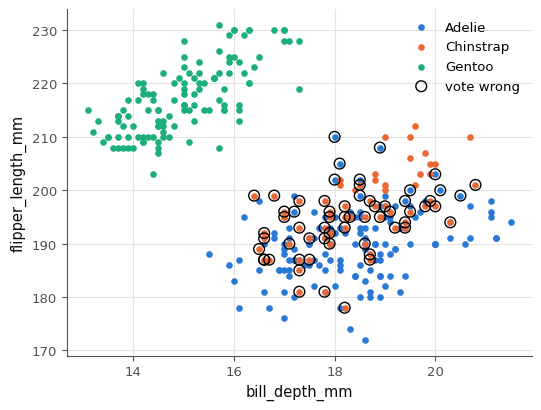

✅ Ex 14.11a : Bien joué !
✅ Ex 14.11b : C'est ça !
✅ Ex 14.11c : Parfait !


In [27]:
if any(answer is ... or answer is None for answer in [vote_11, shared_11, pair_11]):
    print("⏳ Ex 14.11 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    # every penguin predicted by models that did not see it (10-fold cross-validation)
    predictions_11 = {letter: cross_val_predict(model, X_11, Y_11, cv=CV_11) for letter, model in MEMBERS_11.items()}
    accuracies_11 = {letter: float(np.mean(predicted == Y_11)) for letter, predicted in predictions_11.items()}
    stacked_11 = np.array(list(predictions_11.values()))               # (3 voters, 333 penguins)
    species_11 = np.unique(Y_11)
    votes_11 = np.array([(stacked_11 == s).sum(axis=0) for s in species_11])
    vote_result_11 = species_11[np.argmax(votes_11, axis=0)]           # plurality vote, ties: the first species
    for letter, accuracy in accuracies_11.items():
        print(f"member {letter}: accuracy {accuracy:.3f}")
    print(f"plurality vote of the three: accuracy {np.mean(vote_result_11 == Y_11):.3f}")
    wrong_11 = stacked_11 != Y_11
    best_11 = int(np.argmax(list(accuracies_11.values())))
    print(f"the best member ({'ABC'[best_11]}) misclassifies {wrong_11[best_11].sum()} penguins; "
          f"the other two misclassify {wrong_11.all(axis=0)[wrong_11[best_11]].sum()} of them as well")
    print(pd.crosstab(pd.Series(Y_11, name="species"), pd.Series(vote_result_11, name="vote")))
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for s in species_11:
        ax.scatter(*X_11[Y_11 == s].T, s=14, label=s)
    ax.scatter(*X_11[vote_result_11 != Y_11].T, s=60, facecolors="none", edgecolors="black", label="vote wrong")
    ax.set_xlabel("bill_depth_mm")
    ax.set_ylabel("flipper_length_mm")
    ax.legend()
    plt.show()
    wb.check("14.11a", vote_11)
    wb.check("14.11b", shared_11)
    wb.check("14.11c", pair_11)

Dans tes notes : compare avec tes prédictions. Les deux conditions de la fiche (§14.2) sont-elles remplies par ces trois membres ? Leurs erreurs se ressemblent-elles, et que faudrait-il changer pour qu'elles se ressemblent plus ou moins ? Ce que tu as observé sur ces deux mesures vaudrait-il encore avec les quatre ?

💡 Les trois membres font 0,802 (kNN), 0,817 (Naïve Bayes) et 0,799 (arbre) ; le vote fait 0,814, à moins d'un point du meilleur. Le meilleur classe mal 61 manchots, et les deux autres en classent mal 55 aussi (90 %). Toutes les erreurs du vote (62) confondent Adélie et Chinstrap : sur l'épaisseur du bec et la nageoire, ces deux espèces se superposent, alors que les Gentoo (bec mince, longue nageoire) se détachent. Les trois membres font mieux que le hasard, mais leurs erreurs sont presque les mêmes : la seconde condition du §14.2 manque. Avec d'autres découpages en folds (graines 1 à 4), le vote reste entre −0,3 et +0,3 point du meilleur et la part des erreurs partagées entre 87 et 92 %. La longueur du bec, qui sépare Adélie et Chinstrap, changerait tout ; 📦 14.14 donne à chaque membre une mesure différente.

### Ex 14.12 — Coder le vote pondéré et le tirage bootstrap 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire les deux briques de tous les ensembles : un vote pondéré vectorisé et un tirage avec remise.  
**Prérequis :** ✏️ 14.1 · ∂ 14.3 · ch. 2 (bootstrap) · fiche §14.3 et §14.4 · **mylearn :** `ensemble.py` · **Parcours :** C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/ensemble.py` (créé par `python tools/start_chapter.py 14`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement, plus tes modules des chapitres précédents : `clone` (ch. 8, `model_selection.py`) et tes arbres (ch. 13, `tree.py`) ; scikit-learn est l'**oracle** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch14_ensemble.py -q` les lance tous dans un terminal (compte quelques minutes si ton arbre est lent).

Écris `plurality_vote` et `bootstrap_indices`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `plurality_vote(predictions, weights=None)` reçoit un tableau 2-D (ou une liste de listes) de forme `(n_voters, n_samples)`, une ligne par votant, et rend un tableau `(n_samples,)` : pour chaque exemple, la classe dont la somme des poids des votants est la plus grande ; une classe que personne ne désigne a un total nul, un poids peut être négatif ou nul ; à égalité, la **plus petite** classe, dans l'ordre de tri des labels (des entiers ou des chaînes) ; `weights=None` donne une voix à chacun ; `ValueError` si `predictions` n'est pas 2-D, si `weights` n'a pas une valeur par votant ou contient `NaN` ; elle ne modifie pas ses arguments ;
- `bootstrap_indices(n_samples, n_draws=None, rng=None)` rend un tableau d'**entiers** de forme `(n_draws,)` (`n_samples` tirages si `n_draws` vaut `None`), tirés uniformément **avec remise** dans $0, \dots, n - 1$ ; `rng` accepte `None`, un entier ou un `Generator` ; deux appels avec deux générateurs de même graine rendent les mêmes indices, deux appels successifs avec le **même** générateur en rendent d'autres ; `ValueError` si `n_samples < 1` ou `n_draws < 1`.

La vérification essaie les exemples des docstrings, compare tes votes à `scipy.stats.mode` (sans poids) et à une boucle (avec des poids), mesure la part d'indices distincts d'un bootstrap, puis lance les tests.

Dans tes notes : combien d'opérations ton vote fait-il pour $M$ votants, $n$ exemples et $K$ classes ? Pourquoi `bootstrap_indices` reçoit-elle un générateur plutôt qu'une graine fixée à l'intérieur ?

In [28]:
with checked("14.12"):
    doc_12 = np.array([[0, 1, 1], [0, 0, 1], [1, 0, 1]])
    plain_12 = mylearn.ensemble.plurality_vote(doc_12)
    weighted_12 = mylearn.ensemble.plurality_vote(doc_12, weights=[1.0, 1.0, 3.0])
    if returned("14.12", "plurality_vote", plain_12) and returned("14.12", "plurality_vote", weighted_12):
        print("docstring examples:", np.asarray(plain_12).tolist(), np.asarray(weighted_12).tolist(),
              "(expected [0, 0, 1] and [1, 0, 1])")
with checked("14.12"):
    ballots_12 = np.random.default_rng(1412).integers(0, 4, size=(7, 500))      # 7 voters, 500 samples, labels 0 to 3
    mine_12 = np.asarray(mylearn.ensemble.plurality_vote(ballots_12))
    oracle_12 = stats.mode(ballots_12, axis=0).mode                                # ties: the smallest label
    verdict("14.12", mine_12.shape == (500,) and np.array_equal(mine_12, oracle_12),
            "sans poids, tes 500 votes sont ceux de scipy.stats.mode.",
            ("sans poids, tes votes diffèrent de scipy.stats.mode (relis la règle d'égalité : la plus petite classe) ; "
             if mine_12.shape == (500,) else f"sans poids, ton vote rend un tableau de forme {mine_12.shape}, au lieu "
             "d'une classe par exemple (500,) ; ") + "les tests ci-dessous disent où.")
    w_12 = np.array([2.0, 1.0, 1.5, -1.0, 0.5, 0.0, 3.0])
    totals_12 = np.array([[w_12[ballots_12[:, j] == k].sum() for k in range(4)] for j in range(500)])
    verdict("14.12", np.array_equal(np.asarray(mylearn.ensemble.plurality_vote(ballots_12, w_12)),
                                    np.argmax(totals_12, axis=1)),
            "avec des poids (un négatif, un nul), tes votes sont ceux d'une boucle qui additionne les poids.",
            "avec des poids, tes votes diffèrent d'une boucle qui additionne les poids de chaque classe (un poids "
            "négatif retire des voix).")
with checked("14.12"):
    draws_12 = mylearn.ensemble.bootstrap_indices(1000, rng=np.random.default_rng(1412))
    if returned("14.12", "bootstrap_indices", draws_12):
        draws_12 = np.asarray(draws_12)
        distinct_12 = len(np.unique(draws_12)) / 1000
        print(f"bootstrap of 1000 among 1000: {distinct_12:.3f} distinct indices (about 0.632 expected)")
        verdict("14.12", draws_12.shape == (1000,) and 0.60 < distinct_12 < 0.66
                and np.array_equal(draws_12, np.asarray(mylearn.ensemble.bootstrap_indices(1000, rng=np.random.default_rng(1412))))
                and np.array_equal(np.asarray(mylearn.ensemble.bootstrap_indices(50, rng=7)),
                                   np.asarray(mylearn.ensemble.bootstrap_indices(50, rng=7))),
                "1000 tirages, environ 63 % d'indices distincts, les mêmes avec le même générateur ou le même entier.",
                "attendu : 1000 indices, environ 63 % de distincts, et les mêmes tirages pour deux générateurs de même "
                "graine (ou deux fois rng=7) ; les tests ci-dessous disent où.")
if written(lambda: mylearn.ensemble.plurality_vote(np.array([[0]]))) or written(lambda: mylearn.ensemble.bootstrap_indices(2, rng=0)):
    run_mylearn_tests(impl="ref", module="ensemble", keyword="test_plurality_vote_ or test_bootstrap_indices_")
else:
    print("⏳ Ex 14.12 : les tests attendent ton plurality_vote et ton bootstrap_indices.")

docstring examples: [0, 0, 1] [1, 0, 1] (expected [0, 0, 1] and [1, 0, 1])
✅ Ex 14.12 : sans poids, tes 500 votes sont ceux de scipy.stats.mode.
✅ Ex 14.12 : avec des poids (un négatif, un nul), tes votes sont ceux d'une boucle qui additionne les poids.
bootstrap of 1000 among 1000: 0.637 distinct indices (about 0.632 expected)
✅ Ex 14.12 : 1000 tirages, environ 63 % d'indices distincts, les mêmes avec le même générateur ou le même entier.


pytest: 37 passed, 142 deselected in 0.98s


💡 Un vote vectorisé compare la matrice des prédictions à chacune des $K$ classes et additionne les poids colonne par colonne : $M \times n \times K$ opérations, sans boucle Python sur les exemples. Un générateur passé en argument continue sa suite d'un appel à l'autre : un bagging tire ainsi un bootstrap **différent** pour chaque membre à partir d'une seule graine, et toute l'expérience se reproduit ; une graine fixée à l'intérieur donnerait le même bootstrap à tous les membres, qui deviendraient identiques.

### Ex 14.13 — Jury de votants : indépendants puis corrélés 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer ce que la corrélation des erreurs coûte à un vote, et retrouver la limite par le calcul.  
**Prérequis :** ✏️ 14.5 · ch. 2 (corrélation) · fiche §14.2 (encadré sur la loi binomiale) · **Fil rouge :** synthétique · **Parcours :** R, M, C

Un jury de $M$ votants (`MS_13` : 1 à 101), chacun juste avec la probabilité $q$ = `Q_13` = 0,58, à deux classes. La fonction fournie `jury_13(M, q, c)` simule 20 000 votes : à chaque vote, avec la probabilité $c$, **tous** les votants recopient un même avis (juste avec la probabilité $q$) ; sinon, chacun décide seul. Chaque votant reste juste avec la probabilité $q$, mais leurs erreurs sont corrélées dès que $c > 0$. La majorité a raison quand plus de la moitié des votants ont raison.

Calcule :
a) `exact_13` : pour chaque $M$ de `MS_13`, la probabilité **exacte** que la majorité de $M$ votants indépendants ait raison (loi binomiale : `scipy.stats.binom`, importé sous le nom `stats`, ou `math.comb`) ;
b) `first_090_13` : le plus petit $M$ de `MS_13` dont la probabilité en a) atteint 0,9 ;
c) `simulated_13` : pour chaque $M$, la part des votes de `jury_13(M, Q_13, 0.0)` où la majorité a raison (elle doit suivre a) ;
d) `correlated_13` : la même liste avec $c = 0{,}3$ ;
e) `corr_13` : le coefficient de corrélation entre les colonnes 0 et 1 de `jury_13(11, Q_13, 0.3)` (deux votants : `np.corrcoef`) ;
f) `plateau_13` : la limite de la probabilité de d) quand $M$ grandit sans fin, **par le raisonnement** (exacte) ;
g) `q_needed_13` : avec $c = 0{,}3$, le plus petit $q$ pour lequel cette limite atteint 0,9 (exact).

La vérification contrôle a) à g), puis trace les trois courbes et ta limite.

Dans tes notes : compare e) à $c$, et explique pourquoi. Que dit f) sur un ensemble d'arbres entraînés sur les mêmes données ? Relie-le à la variance d'une moyenne corrélée (fiche §14.4).

In [29]:
MS_13 = [1, 3, 5, 11, 21, 51, 101]   # sizes of the jury (odd)
Q_13 = 0.58                           # each voter is right with probability 0.58


def jury_13(M, q, c, n_trials=20_000, seed=1413):
    """Simulate n_trials votes of a jury of M voters, each right with probability q. In each trial, with probability c,
    every voter copies one common vote (itself right with probability q); otherwise each voter decides on its own.
    Return the boolean array of shape (n_trials, M): True where a voter is right."""
    rng = np.random.default_rng(seed)
    common = rng.random(n_trials) < q
    own = rng.random((n_trials, M)) < q
    copy = rng.random(n_trials) < c
    return np.where(copy[:, None], common[:, None], own)

14.13a: [0.58, 0.619, 0.6475, 0.7076, 0.7724, 0.8761, 0.9476]
14.13b: 101
14.13c: [0.5806, 0.6176, 0.6516, 0.7106, 0.7763, 0.875, 0.946]
14.13d: [0.5776, 0.607, 0.6312, 0.6702, 0.7157, 0.7831, 0.836]
14.13e: 0.30391892931186315
14.13f: 0.8739999999999999
14.13g: 0.666666666666667


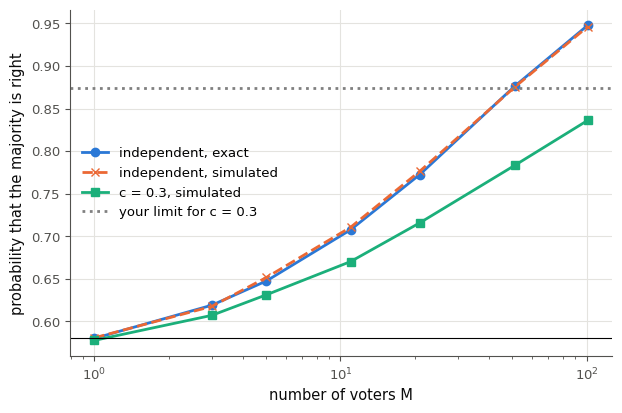

In [30]:
def majority_right_13(M, q):
    """Exact probability that more than half of M independent voters are right (binomial law)."""
    return float(stats.binom.sf(M // 2, M, q))          # P(X > M // 2) = P(X >= (M + 1) / 2) for an odd M


def majority_share_13(right):
    """Share of the trials (rows) where more than half of the voters (columns) are right."""
    return float(np.mean(right.sum(axis=1) > right.shape[1] / 2))


exact_13 = [majority_right_13(M, Q_13) for M in MS_13]
first_090_13 = next(M for M, p in zip(MS_13, exact_13) if p >= 0.9)
simulated_13 = [majority_share_13(jury_13(M, Q_13, 0.0)) for M in MS_13]
correlated_13 = [majority_share_13(jury_13(M, Q_13, 0.3)) for M in MS_13]
corr_13 = float(np.corrcoef(jury_13(11, Q_13, 0.3)[:, 0], jury_13(11, Q_13, 0.3)[:, 1])[0, 1])
plateau_13 = 0.3 * Q_13 + 0.7 * 1.0      # copy: right with probability q; own votes: the majority is right for sure
q_needed_13 = (0.9 - 0.7) / 0.3
print_answer("14.13a", exact_13)
print_answer("14.13b", first_090_13)
print_answer("14.13c", simulated_13)
print_answer("14.13d", correlated_13)
print_answer("14.13e", corr_13)
print_answer("14.13f", plateau_13)
print_answer("14.13g", q_needed_13)
if True:
    if not filled(exact_13, simulated_13, correlated_13):
        raise NotImplementedError("exact_13, simulated_13, correlated_13")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(MS_13, exact_13, marker="o", label="independent, exact")
    ax.plot(MS_13, simulated_13, marker="x", ls="--", label="independent, simulated")
    ax.plot(MS_13, correlated_13, marker="s", label="c = 0.3, simulated")
    if filled(plateau_13):
        ax.axhline(plateau_13, color="grey", ls=":", label="your limit for c = 0.3")
    ax.axhline(Q_13, color="black", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("number of voters M")
    ax.set_ylabel("probability that the majority is right")
    ax.legend()
    plt.show()

In [31]:
sums_13 = [float(stats.binom.sf(M // 2 - 1, M, Q_13)) for M in MS_13]
wb.record("14.13a", exact_13, decimals=4,
          mistakes={"la majorité de M votants (M impair), c'est au moins (M + 1)/2 votants justes : as-tu inclus un terme de trop dans la somme ?": sums_13})
wb.record("14.13b", first_090_13, choices=MS_13,
          fractional="un nombre non entier : est-ce une probabilité ? on demande un M de MS_13",
          mistakes={f"M = {M} : sa probabilité en a) atteint-elle 0,9 ? et est-ce le PREMIER M de MS_13 qui l'atteint ?": M
                    for M in MS_13 if M != first_090_13})
wb.record("14.13c", simulated_13, decimals=3,
          mistakes={"relis la question : on demande les parts mesurées sur les votes simulés de jury_13(M, Q_13, 0.0), pas un calcul exact": exact_13})
wb.record("14.13d", correlated_13, decimals=3,
          mistakes={"relis la question : les votes de d) viennent de jury_13(M, Q_13, 0.3)": simulated_13})
independent_corr_13 = float(np.corrcoef(jury_13(11, Q_13, 0.0)[:, 0], jury_13(11, Q_13, 0.0)[:, 1])[0, 1])
wb.record("14.13e", corr_13, decimals=3,
          mistakes={"relis la question : la corrélation se mesure sur jury_13(11, Q_13, 0.3), avec c = 0,3": independent_corr_13,
                    "c'est c lui-même : on demande la corrélation mesurée sur les votes simulés": 0.3})
wb.record("14.13f", plateau_13, decimals=3,
          mistakes={"tu n'as gardé que le cas où tous recopient : quand chacun décide seul, vers quoi tend la probabilité que la majorité ait raison, et avec quel poids compte ce cas ?": 0.3 * Q_13,
                    "relis la question : c'est la limite pour c = 0,3, pas la probabilité qu'un votant ait raison": Q_13,
                    "quand tous recopient, la majorité a raison avec la probabilité q, pas à coup sûr": 1.0})
wb.record("14.13g", q_needed_13, decimals=3,
          mistakes={"écris la limite de f) avec un q quelconque, puis résous « limite = 0,9 » pour q": 0.9,
                    "tu as résolu 0,3 q + 0,7 = 0,9 sans diviser par 0,3 : isole q": 0.9 - 0.7})

WB_ANSWER {"decimals": 4, "element_coarse": [["512ccd90920432c372a13090e26840489afb66aa90b20e37dee5020730b85255"], ["8533cddb472ae6d3c4090e4979b2939fd86bcc936bdff98b19aefa79cf354962"], ["f7fcfa15d1c7975d7b34f8948d1ff2aa9422cb9967f9eed5c56e5cac5d8b3174"], ["fec37e532bcda7a0c5f27937063cff9b1370442adb7cf754c2042d9919f482a5"], ["fb4c6b216d6cf9973e113d72fc088f25dc85a11594d962808e5823c34571dc72"], ["2de9576a77a25e57a7b2c1f0bc62bbed22f473230280535f65ed09d557bd27e4"], ["b9989bff0c1681141771ad42461eb44a3088464fa44e943612f7dba5e958f052"]], "element_hashes": ["569f7f9c65d8d526180cf0ec85b71fe175b2bc73f02e657eac9a00de17cbefbf", "1de222cd941f0138607d21f245d8a093d649f011d1cca3bc7a19b5bc723e9e06", "671c2205ed1054ced297b0970e4c1ab148593899a44b72a09ecd153f30c2965c", "86bc8f5d0bbc254e2abc26f6614876bcde19259e22ed9cd4b6214b47161d534f", "ab1f42c13b236564422ef0b738a59a72524e5f02b37977ac36063009592ebb9d", "6293fc0df7b31518d94d63f6fa2d9194437d5a7a31b78b66cd922c2db226a7f0", "da5075602c7bd1a9b80ce8c211ed2c297155

💡 Le jury indépendant monte de 0,58 ($M = 1$) à 0,948 ($M = 101$) ; il faut attendre $M = 101$ pour dépasser 0,9 (0,876 à $M = 51$) : avec des votants à peine meilleurs que le hasard, il en faut beaucoup. La simulation suit la loi binomiale à 0,005 près. Avec $c = 0{,}3$, la courbe plafonne (0,836 à $M = 101$) : quand tous recopient le même avis (30 % des votes), la majorité a raison avec la probabilité $q$ quel que soit $M$ ; sinon, elle a raison presque à coup sûr pour un grand jury : la limite vaut $0{,}3 \times 0{,}58 + 0{,}7 = 0{,}874$, sous 0,9 pour tout $M$, et il faudrait $q \ge 2/3$ pour l'atteindre. Deux votants ont une corrélation proche de $c$ (0,304 mesurée) : avec la probabilité $c$ ils sont identiques, sinon indépendants. C'est le plancher $\rho\sigma^2$ de la variance d'une moyenne corrélée : aucun nombre de membres ne compense des erreurs communes.

### Ex 14.14 — Voting et stacking avec les classifieurs du ch. 13 📦 ★★ ⏱️ 25 min
**Objectif :** comparer vote dur, vote souple et stacking, et voir ce que vaut une combinaison face à un seul bon modèle.  
**Prérequis :** Ex 14.11 · ch. 8 (validation croisée) · fiche §14.3 (voting et stacking) · **Fil rouge :** Penguins · **Parcours :** C

Pour que les membres fassent des erreurs **différentes**, chacun ne voit ici qu'**une** mesure : A un kNN à 15 voisins sur la longueur du bec, B `GaussianNB()` sur l'épaisseur du bec, C un arbre de profondeur 3 sur la nageoire (`MEMBERS_14`, une liste de paires `(nom, modèle)`, le format de scikit-learn). La cellule fournie affiche l'accuracy de chacun en validation croisée à 5 folds (`CV_14`, sur les 333 manchots et leurs 4 mesures `X_14` ; chaque membre choisit sa colonne).

Calcule, avec `cross_val_score(..., X_14, Y_14, cv=CV_14)` et la **moyenne** des 5 folds :
a) `hard_14` : `VotingClassifier(MEMBERS_14, voting="hard")` ;
b) `soft_14` : le même avec `voting="soft"` ;
c) `stack_14` : `StackingClassifier(MEMBERS_14, final_estimator=LogisticRegression(max_iter=1000))` (par défaut, son méta-modèle apprend sur les `predict_proba` des membres, obtenus par une validation croisée interne à 5 folds) ;
d) `single_14` : **un seul** modèle qui voit les 4 mesures, `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`.

Dans tes notes : classe les quatre et les trois membres. Pourquoi le vote souple bat-il le vote dur ici ? Que sait faire le méta-modèle que les deux votes ne savent pas ? Pourquoi un seul modèle sur les 4 mesures fait-il encore mieux, et quand un stacking vaut-il vraiment la peine ?

In [32]:
X_14 = PENGUINS[MEASURES].to_numpy()
Y_14 = PENGUINS["species"].to_numpy()
CV_14 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1414)


def on_column(column, model):
    """A pipeline that gives `model` only the column `column` of X."""
    return make_pipeline(ColumnTransformer([("keep", "passthrough", [column])]), model)


MEMBERS_14 = [("A", on_column(0, make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)))),   # bill length
              ("B", on_column(1, GaussianNB())),                                                           # bill depth
              ("C", on_column(2, DecisionTreeClassifier(max_depth=3, random_state=0)))]                    # flipper
for letter, member in MEMBERS_14:
    print(f"member {letter} alone: mean accuracy {cross_val_score(member, X_14, Y_14, cv=CV_14).mean():.3f}")

member A alone: mean accuracy 0.778
member B alone: mean accuracy 0.754
member C alone: mean accuracy 0.811


In [33]:
hard_14 = cross_val_score(VotingClassifier(MEMBERS_14, voting="hard"), X_14, Y_14, cv=CV_14).mean()
soft_14 = cross_val_score(VotingClassifier(MEMBERS_14, voting="soft"), X_14, Y_14, cv=CV_14).mean()
stack_14 = cross_val_score(StackingClassifier(MEMBERS_14, final_estimator=LogisticRegression(max_iter=1000)),
                           X_14, Y_14, cv=CV_14).mean()
single_14 = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_14, Y_14,
                            cv=CV_14).mean()
print_answer("14.14a", hard_14)
print_answer("14.14b", soft_14)
print_answer("14.14c", stack_14)
print_answer("14.14d", single_14)

14.14a: 0.7987788331071913
14.14b: 0.8559023066485754
14.14c: 0.948937132519222
14.14d: 0.990909090909091


In [34]:
members_14 = [cross_val_score(member, X_14, Y_14, cv=CV_14).mean() for _, member in MEMBERS_14]
wb.record("14.14a", hard_14, decimals=4,
          mistakes={"relis la question : voting=\"hard\" compte les classes prédites, sans les probabilités": soft_14})
wb.record("14.14b", soft_14, decimals=4,
          mistakes={"relis la question : voting=\"soft\" moyenne les predict_proba des membres": hard_14})
wb.record("14.14c", stack_14, decimals=4)
wb.record("14.14d", single_14, decimals=4)

WB_ANSWER {"decimals": 4, "hash": "7e118ed135f67437d86224d22607a58b751c0eecfc24270c63d8d21a19ea4bb2", "hash_coarse": "85fa453cb71ff3409e4fb69d4ac61480b5703015f54541096f99f474fcf3e07a", "id": "14.14a", "kind": "float", "magnitude": -1, "mistakes": {"c81db5b394e89e8f14392e912f65e233e6ec72a0d5f51b7c9e99491933749ed0": "relis la question : voting=\"hard\" compte les classes prédites, sans les probabilités"}, "sign": 1}
📝 Ex 14.14a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "c997fc6585676a085f2f3c7df77659962b29b32a642b25b300be45862d423f18", "hash_coarse": "8fa3855043cd7aaf2e897ae4a83fd8c9b917954070d4e29503deb8877d27eee6", "id": "14.14b", "kind": "float", "magnitude": -1, "mistakes": {"3ac5a66319b48426e00baf289b7f87a22a63b5f4253a06b777ab1871b3a5408b": "relis la question : voting=\"soft\" moyenne les predict_proba des membres"}, "sign": 1}
📝 Ex 14.14b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "fd391cd636551b1188ef056c0c

💡 Seuls, les membres font 0,778 (bec), 0,754 (épaisseur) et 0,811 (nageoire). Le vote dur fait 0,799, sous le meilleur membre : quand deux membres faibles se trompent ensemble, ils l'emportent sur le troisième. Le vote souple fait 0,856 : un membre peu sûr de lui pèse peu, un membre sûr pèse beaucoup. Le stacking fait 0,949 : le méta-modèle apprend, sur des prédictions hors échantillon, quel membre croire **pour quelle espèce** (la nageoire pour les Gentoo, la longueur du bec pour séparer Adélie et Chinstrap) ; il combine en fait l'information des trois mesures. Un seul modèle qui voit les 4 mesures fait 0,991 : combiner des modèles ne remplace pas une bonne représentation des données. Un stacking vaut la peine pour combiner des modèles **différents et bons** (un gradient boosting, un réseau, un kNN), et c'est souvent ainsi que se gagnent les compétitions, au prix d'un modèle plus lourd.

## Partie B · Bagging, forêts et ExtraTrees

Les forêts de scikit-learn sur California (14.15), le nombre d'arbres face à des colonnes de bruit (14.16), ton `BaggingClassifier` (14.17), ta forêt et tes ExtraTrees (14.18), puis l'importance des features (14.19). La cellule suivante charge California et la découpe comme le défi 14.28 : 16 512 districts d'entraînement, 4 128 de test (`random_state=42`).

In [35]:
# California: the split of the challenge 14.28 (20 % of test districts, random_state=42), shared by parts B to D
CAL = wb.datasets.load_california()
CAL_FEATURES = [column for column in CAL.columns if column != "MedHouseVal"]
X_CAL, Y_CAL = CAL[CAL_FEATURES].to_numpy(), CAL["MedHouseVal"].to_numpy()
X_CAL_TRAIN, X_CAL_TEST, Y_CAL_TRAIN, Y_CAL_TEST = train_test_split(X_CAL, Y_CAL, test_size=0.2, random_state=42)
print(len(X_CAL_TRAIN), "training districts,", len(X_CAL_TEST), "test districts")

16512 training districts, 4128 test districts


### Ex 14.15 — Forêts scikit-learn sur California : OOB et parallélisme 📦 ★★ ⏱️ 25 min
**Objectif :** utiliser une forêt de régression, son score out-of-bag et son parallélisme, et savoir ce qu'ils valent.  
**Prérequis :** Ex 14.11 · ch. 13 (arbres de régression) · ch. 9 (R²) · fiche §14.4 et §14.5 · **Fil rouge :** California · **Parcours :** R, C

`RandomForestRegressor` de scikit-learn sur 5 000 districts d'entraînement (`X_TRAIN_15`). En régression, `oob_score_` est un $R^2$ (ch. 9) calculé sur les exemples out-of-bag, et `score` rend aussi un $R^2$. Calcule :
a) `oob_15` : le `oob_score_` de `RandomForestRegressor(n_estimators=100, oob_score=True, random_state=0, n_jobs=-1)` ;
b) `test_15` : son $R^2$ sur les 4 128 districts de test ;
c) `oob_curve_15` : la liste des `oob_score_` de la même forêt pour chaque nombre d'arbres de `NS_15` (10 à 200) ;
d) `first_close_15` : le plus petit nombre d'arbres de `NS_15` dont le `oob_score_` est à moins de 0,01 du $R^2$ de test **de la même forêt**.

Avec 10 arbres, scikit-learn prévient que quelques districts n'ont aucun arbre qui ne les a pas vus : c'est normal (tu peux masquer l'avertissement avec `warnings.catch_warnings()`). La vérification contrôle a) à d), puis entraîne la forêt sur un cœur (`n_jobs=1`) et sur tous (`n_jobs=-1`), compare les durées et les prédictions.

Dans tes notes : pourquoi le score out-of-bag est-il pessimiste avec peu d'arbres ? Combien d'arbres prédisent un district out-of-bag, en moyenne, dans une forêt de 10 arbres ? Le gain de `n_jobs=-1` dépend de quoi ? Les prédictions sont-elles identiques au bit près, et pourquoi pourraient-elles ne pas l'être ?

In [36]:
X_TRAIN_15, Y_TRAIN_15 = X_CAL_TRAIN[:5000], Y_CAL_TRAIN[:5000]   # 5,000 training districts
NS_15 = [10, 25, 50, 100, 200]

In [37]:
forest_15 = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=0, n_jobs=-1).fit(X_TRAIN_15, Y_TRAIN_15)
oob_15 = forest_15.oob_score_
test_15 = forest_15.score(X_CAL_TEST, Y_CAL_TEST)
oob_curve_15, test_curve_15 = [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)        # with 10 trees, a few districts have no out-of-bag tree
    for n in NS_15:
        model = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=0, n_jobs=-1).fit(X_TRAIN_15, Y_TRAIN_15)
        oob_curve_15.append(model.oob_score_)
        test_curve_15.append(model.score(X_CAL_TEST, Y_CAL_TEST))
first_close_15 = next(n for n, oob, test in zip(NS_15, oob_curve_15, test_curve_15) if abs(oob - test) < 0.01)
print("test R² for each n:", np.round(test_curve_15, 4).tolist())
print_answer("14.15a", oob_15)
print_answer("14.15b", test_15)
print_answer("14.15c", oob_curve_15)
print_answer("14.15d", first_close_15)
if True:
    if not filled(forest_15):
        raise NotImplementedError("forest_15")
    seconds_15, predictions_15 = {}, {}
    for n_jobs in [1, -1]:                                  # one core, then all the cores
        start_15 = time.perf_counter()
        model_15 = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=n_jobs).fit(X_TRAIN_15, Y_TRAIN_15)
        seconds_15[n_jobs] = time.perf_counter() - start_15
        predictions_15[n_jobs] = model_15.predict(X_CAL_TEST)
    print(f"{os.cpu_count()} core(s): fit in {seconds_15[1]:.2f} s with n_jobs=1, in {seconds_15[-1]:.2f} s with "
          f"n_jobs=-1 (speed-up × {seconds_15[1] / seconds_15[-1]:.1f})")
    print("same predictions to the last bit:", np.array_equal(predictions_15[1], predictions_15[-1]),
          "· largest difference:", float(np.max(np.abs(predictions_15[1] - predictions_15[-1]))))
    verdict("14.15", np.allclose(predictions_15[1], predictions_15[-1], rtol=0, atol=1e-9),
            "avec ou sans parallélisme, la même forêt (même random_state) donne les mêmes prédictions, à 1e-9 près.",
            "les prédictions changent avec n_jobs : est-ce bien la même forêt, avec le même random_state ?")

test R² for each n: [0.7476, 0.7641, 0.7675, 0.7713, 0.7727]
14.15a: 0.7772124700726076
14.15b: 0.7713006011818356
14.15c: [0.6676, 0.7522, 0.7691, 0.7772, 0.7818]
14.15d: 50


2 core(s): fit in 4.24 s with n_jobs=1, in 3.09 s with n_jobs=-1 (speed-up × 1.4)
same predictions to the last bit: False · largest difference: 1.7763568394002505e-15
✅ Ex 14.15 : avec ou sans parallélisme, la même forêt (même random_state) donne les mêmes prédictions, à 1e-9 près.


In [38]:
wb.record("14.15a", oob_15, decimals=4,
          mistakes={"relis la question : on demande oob_score_, calculé sur les districts d'entraînement out-of-bag": test_15})
wb.record("14.15b", test_15, decimals=4,
          mistakes={"relis la question : on demande le R² (score) sur X_CAL_TEST, Y_CAL_TEST": oob_15})
wb.record("14.15c", oob_curve_15, decimals=4,
          mistakes={"relis la question : on demande les oob_score_ des forêts, pas leur score sur le test": test_curve_15})
wb.record("14.15d", first_close_15, choices=NS_15,
          fractional="un nombre non entier : est-ce un R² ? on demande un nombre d'arbres de NS_15",
          mistakes={f"{n} arbres : l'écart entre oob_score_ et le R² de test de la même forêt est-il sous 0,01 ? et est-ce le premier n de NS_15 qui y parvient ?": n
                    for n in NS_15 if n != first_close_15})

WB_ANSWER {"decimals": 4, "hash": "f852dec4548603f8cf486e3d331bf90f83375d43d22f45013eb052a3f487446f", "hash_coarse": "918b62297bac7181d47f79c52f353f77f7590797c840b27fcb2220ff951f12f3", "id": "14.15a", "kind": "float", "magnitude": -1, "mistakes": {"94bf38c270656a6368e88e6a98ea90672cb49fd41e9756a6aade30145317399c": "relis la question : on demande oob_score_, calculé sur les districts d'entraînement out-of-bag"}, "sign": 1}
📝 Ex 14.15a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "c99223701ed070cc9c3b70faca75b15eee09f859126eb2d8fdebd858e9b4e99c", "hash_coarse": "214347ae0d8ba5b4cebcd403d6bfba660360d7642a75bcdc12293993a35257c4", "id": "14.15b", "kind": "float", "magnitude": -1, "mistakes": {"8e6609d3513f30540946f319fcfb9ddf75193ecedffc7b8346e7c11dbf280050": "relis la question : on demande le R² (score) sur X_CAL_TEST, Y_CAL_TEST"}, "sign": 1}
📝 Ex 14.15b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "element_coarse": [["e2a00382

💡 Avec 100 arbres, le $R^2$ out-of-bag vaut 0,777 et celui de test 0,771 : l'estimation gratuite est juste. Avec 10 arbres, elle est très pessimiste (0,668 contre 0,748 en test) : chaque district n'est prédit que par les arbres qui ne l'ont pas vu, en moyenne $10 \times 0{,}368 \approx 3{,}7$ arbres, une forêt bien plus petite que celle qu'on évalue. L'écart passe sous 0,01 à partir de 50 arbres. Sur 2 cœurs, `n_jobs=-1` divise le temps par 1,5 à 2 ; le gain dépend du nombre de cœurs et de la taille du travail (au-delà de quelques centaines d'exemples par arbre). Les prédictions sont identiques à environ $10^{-15}$ près, pas forcément au bit près : en parallèle, les prédictions des arbres s'additionnent dans l'ordre où les cœurs finissent, et l'addition de nombres flottants dépend de l'ordre. C'est pourquoi un benchmark note le nombre de cœurs (🛠️ 14.27).

### Ex 14.16 — Combien d'arbres ? Bagging, forêt et ExtraTrees face au bruit 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer ce que le nombre d'arbres apporte à trois ensembles, et ce que des features de bruit leur coûtent.  
**Prérequis :** Ex 14.15 · ch. 7 (features de bruit) · fiche §14.4 à §14.6 · **Fil rouge :** synthétique · **Parcours :** C

Deux demi-lunes bruitées (500 points d'entraînement, 3 000 de test), puis les mêmes avec **30 colonnes de bruit** (`moons_16(n_noise)`). Trois ensembles de scikit-learn (`ENSEMBLES_16`, chacun appelé avec son nombre d'arbres) : un bagging d'arbres sans limite, une forêt aléatoire (`max_features="sqrt"`) et des ExtraTrees, tous avec `random_state=0`. Écris `curves_16(n_noise)`, qui rend, pour chaque ensemble, la liste de ses accuracies de test pour chaque nombre d'arbres de `NS_16` (1 à 400), puis :
a) `noisy_16` : `curves_16(30)` (la vérification lit la courbe d'ExtraTrees) ; et `clean_16` : `curves_16(0)` ;
b) `worst_16` : l'ensemble qui a la plus petite accuracy avec 400 arbres et 30 colonnes de bruit : `"A"` bagging, `"B"` forêt, `"C"` ExtraTrees ;
c) `gain_extra_16` : pour ExtraTrees avec 30 colonnes de bruit, l'accuracy à 400 arbres moins celle à 25 arbres ;
d) `drop_16` : `True` si l'une des six courbes perd plus de 0,005 entre 100 et 400 arbres, `False` sinon.

Ta cellule entraîne 54 ensembles (compte une quinzaine de secondes) ; la vérification trace les deux familles de courbes.

Dans tes notes : avec 30 colonnes de bruit, combien de features utiles un nœud de la forêt voit-il, en moyenne, parmi les 5 qu'il tire ? Pourquoi les seuils tirés au hasard d'ExtraTrees souffrent-ils encore plus du bruit ? Pourquoi 2 arbres font-ils souvent moins bien qu'un seul ? Combien d'arbres mettrais-tu ?

In [39]:
NS_16 = [1, 2, 5, 10, 25, 50, 100, 200, 400]


def moons_16(n_noise):
    """Two noisy moons plus n_noise columns of standard normal noise: 500 training points, 3,000 test points."""
    X, y = wb.synth.make_moons(n=3500, noise=0.35, seed=1416)
    X = np.hstack([X, np.random.default_rng(1416).normal(size=(len(X), n_noise))])
    return X[:500], y[:500], X[500:], y[500:]


ENSEMBLES_16 = {"bagging": lambda n: BaggingClassifier(DecisionTreeClassifier(), n_estimators=n, random_state=0),
                "forest": lambda n: RandomForestClassifier(n_estimators=n, random_state=0),
                "extra": lambda n: ExtraTreesClassifier(n_estimators=n, random_state=0)}

14.16a: [0.6177, 0.6307, 0.7357, 0.7763, 0.8117, 0.8273, 0.8353, 0.8403, 0.8397]
14.16b: C
14.16c: 0.028000000000000025
14.16d: False


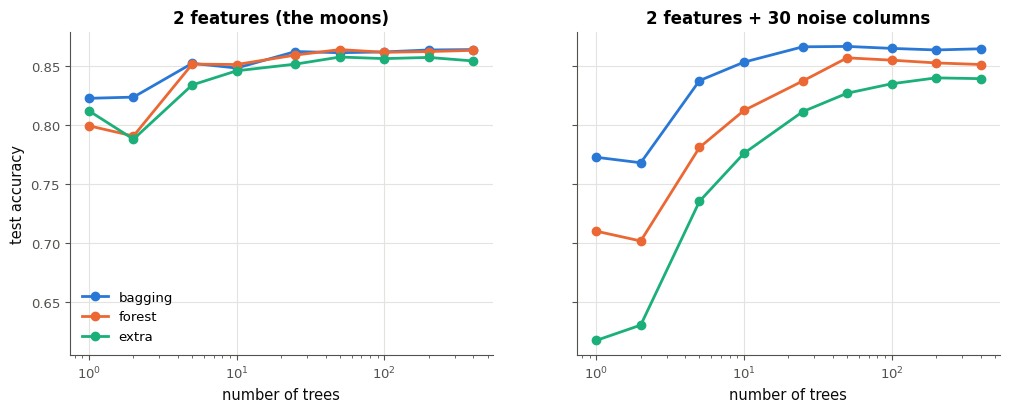

In [40]:
def curves_16(n_noise):
    """Return a dict {"bagging": [...], "forest": [...], "extra": [...]}: for each ensemble of ENSEMBLES_16 (called with
    the number of trees), the list of its test accuracies on moons_16(n_noise), one per number of trees of NS_16."""
    X_train, y_train, X_test, y_test = moons_16(n_noise)
    return {name: [make(n).fit(X_train, y_train).score(X_test, y_test) for n in NS_16]
            for name, make in ENSEMBLES_16.items()}


clean_16 = curves_16(0)
noisy_16 = curves_16(30)
worst_16 = "ABC"[int(np.argmin([noisy_16[name][-1] for name in ENSEMBLES_16]))]
gain_extra_16 = noisy_16["extra"][NS_16.index(400)] - noisy_16["extra"][NS_16.index(25)]
drop_16 = any(curve[NS_16.index(100)] - curve[NS_16.index(400)] > 0.005
              for curves in (clean_16, noisy_16) for curve in curves.values())
print_answer("14.16a", noisy_16.get("extra") if isinstance(noisy_16, dict) else noisy_16)
print_answer("14.16b", worst_16)
print_answer("14.16c", gain_extra_16)
print_answer("14.16d", drop_16)
if True:
    if not filled(clean_16, noisy_16):
        raise NotImplementedError("clean_16, noisy_16")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, (family, title, curves) in zip(axes, [("clean_16", "2 features (the moons)", clean_16),
                                                  ("noisy_16", "2 features + 30 noise columns", noisy_16)]):
        if not isinstance(curves, dict):
            print(f"❌ Ex 14.16 : {family} doit être un dictionnaire {{nom de l'ensemble: liste d'accuracies}}, pas un {type(curves).__name__}.")
            continue
        for name, curve in curves.items():
            if np.ndim(curve) != 1 or len(curve) != len(NS_16):
                print(f"❌ Ex 14.16 : {family}[{name!r}] doit être une liste de {len(NS_16)} accuracies, une par nombre "
                      f"d'arbres de NS_16 (forme reçue : {np.shape(curve)}).")
                continue
            ax.plot(NS_16, curve, marker="o", label=name)
        ax.set_xscale("log")
        ax.set_xlabel("number of trees")
        ax.set_title(title)
    axes[0].set_ylabel("test accuracy")
    axes[0].legend()
    plt.show()

In [41]:
wb.record("14.16a", noisy_16["extra"], decimals=3,
          mistakes={"c'est la courbe sans colonne de bruit : on demande curves_16(30)": clean_16["extra"],
                    "c'est la courbe de la forêt : on demande celle d'ExtraTrees": noisy_16["forest"]})
wb.record("14.16b", worst_16,
          mistakes={"relis la dernière valeur de chaque courbe de noisy_16 : laquelle est la plus petite ?": "A",
                    "relis la dernière valeur de chaque courbe de noisy_16, ExtraTrees compris : laquelle est la plus petite ?": "B"})
wb.record("14.16c", gain_extra_16, decimals=3,
          mistakes={"c'est la valeur avec 400 arbres : on demande la différence avec 25 arbres": noisy_16["extra"][-1],
                    "le signe : 400 arbres moins 25 arbres": -gain_extra_16})
wb.record("14.16d", drop_16, mistakes={"compare, pour chacune des six courbes, la valeur à 100 arbres et celle à 400 : laquelle perd plus de 0,005 ?": True})

WB_ANSWER {"decimals": 3, "element_coarse": [["ef48b2fa43141ce862f8a710a510c197b76d578e0cbff44d4e64370675c698fa"], ["0cc19a5c2cd7196f2a363ad0feb7da18666a534e9daaa0723ac07b21e3e03ee9"], ["1b62ddab4add1d8b8e724099a4dff322e7e82d202266b8382e45e74e93db6ac2"], ["537d25b40f84c4effcac522ab157561033ca145b9fcedf0ceb8537fd04e74d5f"], ["c34f656a82b72edd244bee22004f75cb39b83effc3909e2d06a3aaa30217121a"], ["4c7d9f9557f8e031b4392edf05c0689a841172e2a4bae9b953137571ed7e7d17"], ["ae913b47f339d556b7840b740c8ada523f5abbbc77d1fee5bf108bb41ff3620a"], ["515cb444e80edbb077051f89569a6d9fae1a09b50a2cb8790a739e2ecb8ca903"], ["0838850686199393cbe77227ebd7e0bc7162aa31710c9c084a68a63891f2f92d"]], "element_hashes": ["004555b87ba6bf4e5da25a46a420b5042db7e5265fc76548b59674ebf5678bb1", "4903d52cee3141cc0210635dfc324129129897a49fdd88457a65b435cac48a50", "b6e16262544bdb80e0a467851e50d0950a499e0a6157358979087a84efa28e78", "0081416298bd1f3ee1758a1e6ca88c3600cdd84063e799a3b26f518e3abee299", "163140882efebd2b71eecfa87cc4f85c

💡 Sans bruit, les trois ensembles plafonnent vers 0,86 dès 25 à 50 arbres. Avec 30 colonnes de bruit, le bagging (qui examine les 32 features à chaque nœud) garde 0,865 ; la forêt tire 5 features par nœud, dont $5 \times 2/32 \approx 0{,}3$ utile en moyenne : beaucoup de nœuds coupent sur du bruit, et elle descend à 0,852 ; ExtraTrees, dont les seuils sont aussi tirés au hasard, finit à 0,840 et a besoin de bien plus d'arbres (+0,028 entre 25 et 400). Aucune courbe ne perd plus de 0,004 entre 100 et 400 arbres : plus d'arbres ne fait pas surapprendre, mais au-delà d'une centaine on ne gagne plus rien. Avec 2 arbres, chaque désaccord donne une probabilité de 0,5 pour chaque classe, et l'égalité donne la première classe : la moitié des désaccords sont perdus, d'où un creux à 2 arbres. Avec d'autres tirages des données (graines 1 à 3 de `make_moons` et du bruit), ExtraTrees reste le dernier avec 30 colonnes de bruit (de 0,850 à 0,855 contre 0,859 à 0,871 pour les deux autres).

### Ex 14.17 — Coder BaggingClassifier avec score out-of-bag 🔨 ★★★ ⏱️ 50 min
**Objectif :** écrire un bagging générique : des clones entraînés sur leurs bootstraps, un vote souple et un score out-of-bag.  
**Prérequis :** Ex 14.12 · Ex 13.25 · ch. 8 (`clone`) · fiche §14.4 (pseudo-code) · **Fil rouge :** Penguins · **mylearn :** `ensemble.py` · **Parcours :** C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/ensemble.py` (créé par `python tools/start_chapter.py 14`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement, plus tes modules des chapitres précédents : `clone` (ch. 8, `model_selection.py`) et tes arbres (ch. 13, `tree.py`) ; scikit-learn est l'**oracle** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch14_ensemble.py -q` les lance tous dans un terminal (compte quelques minutes si ton arbre est lent).

Écris la classe `BaggingClassifier`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `__init__` range ses six arguments tels quels ; `fit(X, y)` vérifie, apprend `classes_` (les labels distincts triés), `estimators_`, `estimators_samples_` (et `oob_score_` si `oob_score=True`), puis renvoie `self` ; un second `fit` du même objet redonne le même ensemble ;
- `fit` crée **un** générateur à partir de `random_state` (`np.random.default_rng(random_state)`), d'où vient tout le hasard de l'ensemble ; chaque membre a son propre échantillon d'indices, de la taille que fixe `max_samples` (un bootstrap, avec `bootstrap_indices`, si `bootstrap=True` ; sinon des indices **distincts**), est un `clone(gabarit)` neuf (le gabarit est `estimator`, ou `DecisionTreeClassifier()` de **ton** `tree.py` si `estimator` vaut `None` ; il n'est jamais entraîné lui-même), reçoit, s'il a un attribut `random_state`, un **entier** tiré de ce générateur, et apprend sur `X[indices]`, `y[indices]` ;
- `max_samples` : un entier de 1 à $n$, ou un réel $f$ dans $]0, 1]$ (`max(1, int(f * n))` tirages) ; `ValueError` sinon, ainsi que pour `n_estimators < 1`, `oob_score=True` avec `bootstrap=False`, un `X` qui n'est pas 2-D ou contient `NaN`, ou `len(X) != len(y)` ;
- `predict_proba(X)` : la moyenne des `predict_proba` des membres, **alignés sur `classes_`** (un membre qui n'a vu que certaines classes donne une probabilité nulle aux autres) ; `predict(X)` : la classe de plus grande probabilité moyenne ; `score(X, y)` : l'accuracy, un `float` Python ; `RuntimeError` si `predict_proba`, `predict` ou `score` est appelée avant `fit` ;
- `oob_score_` : chaque exemple d'entraînement est prédit par la moyenne des probabilités des **seuls** membres qui ne l'ont pas vu ; les exemples vus par tous sont laissés de côté ; `ValueError` si aucun exemple n'est out-of-bag.

La vérification essaie l'exemple de la docstring, compare ton bagging (25 arbres, 5 graines) à celui de scikit-learn sur deux mesures des manchots, contrôle les échantillons, les clones et la reproductibilité, puis lance les tests.

Dans tes notes : pourquoi un clone neuf par membre, plutôt que le gabarit réentraîné 25 fois ? Pourquoi le vote souple doit-il aligner les colonnes sur `classes_` ? Que coûte le score out-of-bag ?

In [42]:
with checked("14.17"):
    X_doc_17 = np.array([[0.0], [1.0], [2.0], [3.0], [10.0], [11.0], [12.0], [13.0]])
    y_doc_17 = np.array([0, 0, 0, 0, 1, 1, 1, 1])
    doc_17 = fitted(mylearn.ensemble.BaggingClassifier(n_estimators=5, random_state=0), X_doc_17, y_doc_17)
    predicted_doc_17 = doc_17.predict(np.array([[1.5], [11.5]]))
    if returned("14.17", "predict", predicted_doc_17):
        print("docstring example:", len(doc_17.estimators_), "members, predict", np.asarray(predicted_doc_17).tolist(),
              "(expected 5 members and [0, 1])")
with checked("14.17"):
    X_17, y_17 = P_TRAIN[["bill_depth_mm", "flipper_length_mm"]].to_numpy(), P_TRAIN["species"].to_numpy()
    X_test_17, y_test_17 = P_TEST[["bill_depth_mm", "flipper_length_mm"]].to_numpy(), P_TEST["species"].to_numpy()
    mine_17, oracle_17 = [], []
    start_17 = time.perf_counter()
    for seed in range(5):
        model = fitted(mylearn.ensemble.BaggingClassifier(n_estimators=25, oob_score=True, random_state=seed), X_17, y_17)
        mine_17.append((model.score(X_test_17, y_test_17), model.oob_score_))
    seconds_17 = time.perf_counter() - start_17
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")              # scikit-learn warns when a penguin is in every bootstrap
        for seed in range(5):
            model = BaggingClassifier(DecisionTreeClassifier(), n_estimators=25, oob_score=True, random_state=seed).fit(X_17, y_17)
            oracle_17.append((model.score(X_test_17, y_test_17), model.oob_score_))
    (acc_17, oob_17), (sk_acc_17, sk_oob_17) = np.mean(mine_17, axis=0), np.mean(oracle_17, axis=0)
    print(f"5 baggings of 25 trees (2 measures of the penguins), mean over random_state 0 to 4:\n"
          f"  yours:        test accuracy {acc_17:.3f}, oob_score_ {oob_17:.3f} ({seconds_17:.1f} s for the 5)\n"
          f"  scikit-learn: test accuracy {sk_acc_17:.3f}, oob_score_ {sk_oob_17:.3f}")
    verdict("14.17", abs(acc_17 - sk_acc_17) < 0.03 and abs(oob_17 - sk_oob_17) < 0.05,
            "ton bagging est à moins de 3 points de scikit-learn en test, et ton score out-of-bag à moins de 5 points.",
            "ton bagging s'écarte de scikit-learn de plus de 3 points en test, ou ton score out-of-bag de plus de 5 : "
            "les tests ci-dessous disent où.")
with checked("14.17"):
    template_17 = mylearn.tree.DecisionTreeClassifier(max_depth=3)
    bag_17 = fitted(mylearn.ensemble.BaggingClassifier(template_17, n_estimators=10, random_state=1), X_17, y_17)
    again_17 = fitted(mylearn.ensemble.BaggingClassifier(template_17, n_estimators=10, random_state=1), X_17, y_17)
    samples_17 = [np.asarray(rows) for rows in bag_17.estimators_samples_]
    checks_17 = {
        "10 membres, chacun avec ses 233 indices tirés avec remise": len(bag_17.estimators_) == 10
            and all(rows.shape == (233,) and len(np.unique(rows)) < 233 for rows in samples_17),
        "des échantillons différents d'un membre à l'autre": len({tuple(rows) for rows in samples_17}) == 10,
        "le gabarit n'est jamais entraîné lui-même (des clones)": getattr(template_17, "root_", None) is None
            and all(member is not template_17 for member in bag_17.estimators_),
        "les mêmes probabilités pour le même random_state": np.allclose(bag_17.predict_proba(X_test_17),
                                                                       again_17.predict_proba(X_test_17)),
    }
    for what, ok in checks_17.items():
        verdict("14.17", ok, what + ".", "attendu : " + what + " ; les tests ci-dessous disent où.")
if written(lambda: mylearn.ensemble.BaggingClassifier(n_estimators=1).fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="ensemble", keyword="test_bagging_classifier_")
else:
    print("⏳ Ex 14.17 : les tests attendent le fit de ton BaggingClassifier.")

docstring example: 5 members, predict [0, 1] (expected 5 members and [0, 1])


5 baggings of 25 trees (2 measures of the penguins), mean over random_state 0 to 4:
  yours:        test accuracy 0.764, oob_score_ 0.750 (2.3 s for the 5)
  scikit-learn: test accuracy 0.766, oob_score_ 0.761
✅ Ex 14.17 : ton bagging est à moins de 3 points de scikit-learn en test, et ton score out-of-bag à moins de 5 points.
✅ Ex 14.17 : 10 membres, chacun avec ses 233 indices tirés avec remise.
✅ Ex 14.17 : des échantillons différents d'un membre à l'autre.
✅ Ex 14.17 : le gabarit n'est jamais entraîné lui-même (des clones).
✅ Ex 14.17 : les mêmes probabilités pour le même random_state.


pytest: 38 passed, 141 deselected in 2.01s


💡 Un modèle réentraîné oublie son entraînement précédent : 25 `fit` du même objet laisseraient 25 références au **même** arbre, le dernier. `clone` crée un objet neuf, non entraîné, aux mêmes hyperparamètres. Un membre dont le bootstrap ne contient aucun Chinstrap rend un `predict_proba` à deux colonnes : sans alignement sur `classes_`, la moyenne additionnerait les probabilités de deux espèces différentes. Le score out-of-bag ne demande aucun entraînement de plus, seulement une prédiction de chaque membre sur ses exemples out-of-bag (environ 37 % des exemples d'entraînement).

### Ex 14.18 — Coder RandomForest et ExtraTrees 🔨 ★★★ ⏱️ 45 min
**Objectif :** construire une forêt aléatoire et des ExtraTrees sur ton bagging et tes arbres, avec leurs importances.  
**Prérequis :** Ex 14.17 · Ex 13.25 (`max_features`, `splitter`) · fiche §14.5 et §14.6 · **Fil rouge :** synthétique · **mylearn :** `ensemble.py` · **Parcours :** C

> **mylearn** : dans `mon_travail/mylearn/ensemble.py`, mêmes règles qu'en 14.17. Enregistre, puis relance la cellule de vérification.

Écris les classes `RandomForestClassifier` et `ExtraTreesClassifier`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- chaque arbre est un `DecisionTreeClassifier` de **ton** `tree.py`, avec les `max_depth`, `min_samples_split`, `min_samples_leaf` et `max_features` de l'ensemble, plus `splitter="random"` pour ExtraTrees ; il apprend sur un bootstrap de $n$ tirages (`bootstrap=True`) ou sur tout l'entraînement (`bootstrap=False`), et reçoit un `random_state` entier, différent d'un arbre à l'autre, tiré d'un générateur créé dans `fit` à partir du `random_state` de l'ensemble (comme les membres de ton bagging) ; `__init__` range ses arguments tels quels, et `fit` n'ajoute que des attributs appris (un nom qui finit par `_`) ou privés (un nom qui commence par `_`) ;
- après `fit` : `estimators_`, `classes_`, `feature_importances_` (et `oob_score_` pour la forêt si `oob_score=True`) ; `predict_proba`, `predict` et `score` comme le bagging (vote souple, `RuntimeError` avant `fit`) ; `ValueError` pour un hyperparamètre invalide, `NaN`, `len(X) != len(y)`, ou `oob_score=True` avec `bootstrap=False` ;
- `feature_importances_` : la moyenne des `feature_importances_` des arbres **qui coupent au moins une fois**, renormalisée pour sommer à 1 (des zéros si aucun arbre ne coupe), comme scikit-learn : un arbre réduit à une feuille ne donne que des zéros, qui ne doivent pas tirer la moyenne vers le bas ; c'est ce que demande l'exemple de la docstring (`array([1.])`), que la seule moyenne ne donne pas.

La vérification essaie les exemples des docstrings, compare tes deux ensembles (20 arbres, 3 graines) à ceux de scikit-learn sur des demi-lunes avec 3 colonnes de bruit (accuracy et importances), vérifie les hyperparamètres des arbres, puis lance les tests (les tests statistiques entraînent beaucoup de forêts : compte une à deux minutes si ton arbre est lent).

Dans tes notes : combien de lignes ta forêt a-t-elle demandé, une fois le bagging écrit ? Lequel de tes deux ensembles s'entraîne le plus vite, et pourquoi ?

In [43]:
with checked("14.18"):
    X_doc_18 = np.array([[0.0], [1.0], [2.0], [3.0], [10.0], [11.0], [12.0], [13.0]])
    y_doc_18 = np.array([0, 0, 0, 0, 1, 1, 1, 1])
    forest_doc_18 = fitted(mylearn.ensemble.RandomForestClassifier(n_estimators=5, random_state=0), X_doc_18, y_doc_18)
    extra_doc_18 = fitted(mylearn.ensemble.ExtraTreesClassifier(n_estimators=5, random_state=0), X_doc_18, y_doc_18)
    print("docstring examples: forest", np.asarray(forest_doc_18.predict(np.array([[1.5], [11.5]]))).tolist(),
          "importances", np.round(np.asarray(forest_doc_18.feature_importances_, dtype=float), 4).tolist(), "· extra",
          np.asarray(extra_doc_18.predict(np.array([[1.5], [11.5]]))).tolist(), "(expected [0, 1], [1.0] and [0, 1])")
with checked("14.18"):
    X_18, y_18 = wb.synth.make_moons(n=1300, noise=0.3, seed=1418)
    X_18 = np.hstack([X_18, np.random.default_rng(1418).normal(size=(1300, 3))])   # 2 useful features, 3 of noise
    X_train_18, y_train_18, X_test_18, y_test_18 = X_18[:300], y_18[:300], X_18[300:], y_18[300:]
    pairs_18 = [("RandomForestClassifier", mylearn.ensemble.RandomForestClassifier, RandomForestClassifier),
                ("ExtraTreesClassifier", mylearn.ensemble.ExtraTreesClassifier, ExtraTreesClassifier)]
    for name, mine_class, oracle_class in pairs_18:
        start_18 = time.perf_counter()
        mine_18 = [fitted(mine_class(n_estimators=20, random_state=seed), X_train_18, y_train_18) for seed in range(3)]
        seconds_18 = time.perf_counter() - start_18
        oracles_18 = [oracle_class(n_estimators=20, random_state=seed).fit(X_train_18, y_train_18) for seed in range(3)]
        acc_18 = np.mean([model.score(X_test_18, y_test_18) for model in mine_18])
        sk_acc_18 = np.mean([model.score(X_test_18, y_test_18) for model in oracles_18])
        importances_18 = np.mean([np.asarray(model.feature_importances_, dtype=float) for model in mine_18], axis=0)
        print(f"{name}, 20 trees, mean over random_state 0 to 2: yours {acc_18:.3f} ({seconds_18:.1f} s), "
              f"scikit-learn {sk_acc_18:.3f}; your importances {np.round(importances_18, 3).tolist()}")
        verdict("14.18", abs(acc_18 - sk_acc_18) < 0.03,
                f"{name} : à moins de 3 points de scikit-learn.",
                f"{name} : plus de 3 points d'écart avec scikit-learn ; les tests ci-dessous disent où.")
        verdict("14.18", importances_18.shape == (5,) and set(np.argsort(importances_18)[-2:]) == {0, 1}
                and abs(importances_18.sum() - 1) < 1e-6,
                f"{name} : les deux features utiles (0 et 1) ont les plus grandes importances, qui somment à 1.",
                f"{name} : attendu des importances de forme (5,), qui somment à 1, les plus grandes pour les features 0 "
                "et 1 (les trois autres sont du bruit).")
    trees_18 = {"forest": fitted(mylearn.ensemble.RandomForestClassifier(n_estimators=3, max_depth=4, random_state=0),
                                 X_train_18, y_train_18).estimators_[0],
                "extra": fitted(mylearn.ensemble.ExtraTreesClassifier(n_estimators=3, max_depth=4, random_state=0),
                                X_train_18, y_train_18).estimators_[0]}
    verdict("14.18", getattr(trees_18["forest"], "max_features", None) == "sqrt"
            and getattr(trees_18["forest"], "max_depth", None) == 4 and getattr(trees_18["extra"], "splitter", None) == "random",
            "les arbres reçoivent les hyperparamètres de l'ensemble (max_features=\"sqrt\", max_depth, et "
            "splitter=\"random\" pour ExtraTrees).",
            "chaque arbre doit recevoir max_depth, min_samples_split, min_samples_leaf et max_features de l'ensemble, "
            "et splitter=\"random\" pour ExtraTrees.")
if written(lambda: mylearn.ensemble.RandomForestClassifier(n_estimators=1).fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="ensemble", keyword="test_random_forest_classifier_ or test_extra_trees_classifier_")
else:
    print("⏳ Ex 14.18 : les tests attendent le fit de ta RandomForestClassifier.")

docstring examples: forest [0, 1] importances [1.0] · extra [0, 1] (expected [0, 1], [1.0] and [0, 1])


RandomForestClassifier, 20 trees, mean over random_state 0 to 2: yours 0.902 (1.0 s), scikit-learn 0.899; your importances [0.301, 0.51, 0.074, 0.058, 0.056]
✅ Ex 14.18 : RandomForestClassifier : à moins de 3 points de scikit-learn.
✅ Ex 14.18 : RandomForestClassifier : les deux features utiles (0 et 1) ont les plus grandes importances, qui somment à 1.


ExtraTreesClassifier, 20 trees, mean over random_state 0 to 2: yours 0.903 (2.4 s), scikit-learn 0.903; your importances [0.317, 0.483, 0.076, 0.064, 0.059]
✅ Ex 14.18 : ExtraTreesClassifier : à moins de 3 points de scikit-learn.
✅ Ex 14.18 : ExtraTreesClassifier : les deux features utiles (0 et 1) ont les plus grandes importances, qui somment à 1.
✅ Ex 14.18 : les arbres reçoivent les hyperparamètres de l'ensemble (max_features="sqrt", max_depth, et splitter="random" pour ExtraTrees).


pytest: 44 passed, 135 deselected in 8.31s


💡 Une fois le bagging écrit, une forêt tient en quelques lignes : un gabarit `DecisionTreeClassifier(max_features=..., ...)`, un `BaggingClassifier` de ce gabarit, puis la moyenne des importances. Ici, avec l'arbre de la référence, ExtraTrees s'entraîne plus lentement que la forêt (2 à 3 fois) : sans bootstrap et avec des seuils tirés, ses arbres sont bien plus profonds (environ 19 niveaux et 99 feuilles, contre 11 et 33). Avec un arbre « naïf », qui essaie tous les seuils sans trier, un seuil tiré fait au contraire gagner beaucoup de temps (la fiche, §14.6, dit que cela dépend des données ; cela dépend aussi de l'arbre).

### Ex 14.19 — Importance des features : impureté contre permutation 📦 ★★★ ⏱️ 35 min
**Objectif :** comparer l'importance MDI d'une forêt à l'importance par permutation, et voir ce qui trompe la première.  
**Prérequis :** Ex 14.15 · ch. 12 (sélection de features) · fiche §14.5 (importance des features) · **Fil rouge :** California · **Parcours :** C

California, avec deux colonnes **sans aucun lien** avec la cible : `row_id`, un numéro différent pour chaque district, et `coin`, 0 ou 1 au hasard. Une forêt de 100 arbres apprend sur 5 000 districts (`X_TRAIN_19`, un DataFrame) ; 2 000 autres districts d'entraînement servent de validation (`X_VAL_19`). Calcule `forest_19`, `mdi_19` (son `feature_importances_`) et `perm_19` (l'importance par permutation sur la validation, avec `permutation_importance(..., n_repeats=5, random_state=0, n_jobs=-1)`, attribut `importances_mean`), deux `pandas.Series` indexées par `FEATURES_19` et triées par ordre décroissant, puis :
a) `rank_id_19` : le rang de `row_id` dans `mdi_19` (1 pour la plus importante) ;
b) `ratio_19` : l'importance MDI de `row_id` divisée par celle de `coin` ;
c) `second_mdi_19` : le nom de la deuxième feature de `mdi_19` ;
d) `second_perm_19` : le nom de la deuxième feature de `perm_19` ;
e) `id_train_19` : l'importance par permutation de `row_id` mesurée sur les districts d'**entraînement** (le même appel sur `X_TRAIN_19`, `Y_TRAIN_19`) ;
f) `joint_19` : la baisse moyenne du $R^2$ de validation quand on permute **ensemble** `Latitude` et `Longitude` : pour `r` de 0 à 4, une permutation `np.random.default_rng(r).permutation(len(X_VAL_19))`, appliquée aux deux colonnes d'une copie de `X_VAL_19` ; la baisse est le $R^2$ de validation (`forest_19.score`) moins celui de la copie.

La vérification contrôle a) à f), puis trace les deux importances.

Dans tes notes : pourquoi `row_id` pèse-t-il tant plus que `coin` dans l'importance MDI ? Que dit e) sur ce que la forêt a appris de `row_id` ? Compare f) à la somme des importances par permutation de `Latitude` et de `Longitude` : pourquoi n'est-ce pas la même chose ?

In [44]:
rng_19 = np.random.default_rng(1419)
DATA_19 = pd.concat([pd.DataFrame({"row_id": rng_19.permutation(len(CAL)).astype(float),   # a distinct number per
                                   "coin": rng_19.integers(0, 2, len(CAL)).astype(float)}),  # district; 0 or 1 at random:
                     CAL[CAL_FEATURES]], axis=1)                                             # both unrelated to y
FEATURES_19 = list(DATA_19.columns)
rows_train_19, _ = train_test_split(np.arange(len(DATA_19)), test_size=0.2, random_state=42)   # the split of part B
X_TRAIN_19, Y_TRAIN_19 = DATA_19.iloc[rows_train_19[:5000]], Y_CAL[rows_train_19[:5000]]
X_VAL_19, Y_VAL_19 = DATA_19.iloc[rows_train_19[5000:7000]], Y_CAL[rows_train_19[5000:7000]]
print(FEATURES_19)

['row_id', 'coin', 'MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


14.19a: 9
14.19b: 7.932819147954261
14.19c: AveOccup
14.19d: Latitude
14.19e: 0.015653139586486287
14.19f: 0.23188136459059172


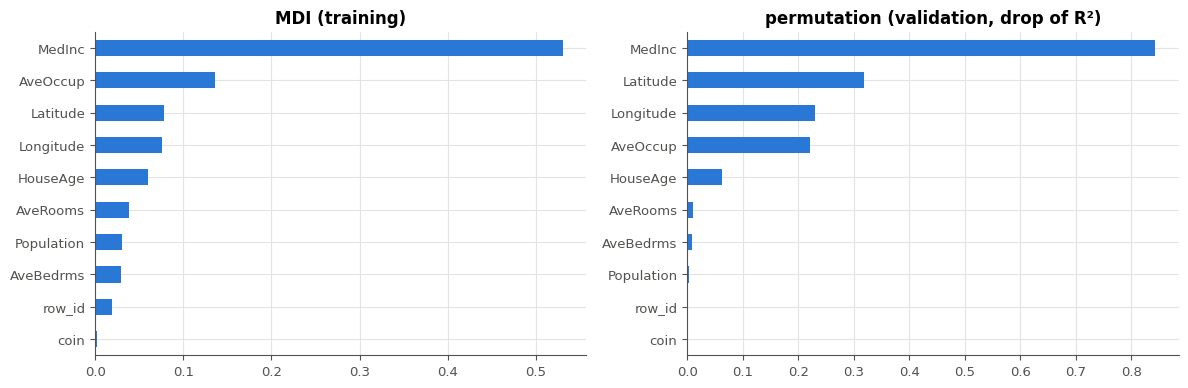

In [45]:
forest_19 = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(X_TRAIN_19, Y_TRAIN_19)
mdi_19 = pd.Series(forest_19.feature_importances_, index=FEATURES_19).sort_values(ascending=False)
on_val_19 = permutation_importance(forest_19, X_VAL_19, Y_VAL_19, n_repeats=5, random_state=0, n_jobs=-1)
perm_19 = pd.Series(on_val_19.importances_mean, index=FEATURES_19).sort_values(ascending=False)
rank_id_19 = list(mdi_19.index).index("row_id") + 1
ratio_19 = mdi_19["row_id"] / mdi_19["coin"]
second_mdi_19, second_perm_19 = mdi_19.index[1], perm_19.index[1]
on_train_19 = permutation_importance(forest_19, X_TRAIN_19, Y_TRAIN_19, n_repeats=5, random_state=0, n_jobs=-1)
id_train_19 = on_train_19.importances_mean[FEATURES_19.index("row_id")]
base_19 = forest_19.score(X_VAL_19, Y_VAL_19)
drops_19 = []
for r in range(5):
    order = np.random.default_rng(r).permutation(len(X_VAL_19))
    shuffled = X_VAL_19.copy()
    shuffled[["Latitude", "Longitude"]] = X_VAL_19[["Latitude", "Longitude"]].to_numpy()[order]
    drops_19.append(base_19 - forest_19.score(shuffled, Y_VAL_19))
joint_19 = float(np.mean(drops_19))
print_answer("14.19a", rank_id_19)
print_answer("14.19b", ratio_19)
print_answer("14.19c", second_mdi_19)
print_answer("14.19d", second_perm_19)
print_answer("14.19e", id_train_19)
print_answer("14.19f", joint_19)
if True:
    if not filled(mdi_19, perm_19):
        raise NotImplementedError("mdi_19, perm_19")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    pd.Series(mdi_19).sort_values().plot.barh(ax=axes[0], title="MDI (training)")
    pd.Series(perm_19).sort_values().plot.barh(ax=axes[1], title="permutation (validation, drop of R²)")
    plt.tight_layout()
    plt.show()

In [46]:
wb.record("14.19a", rank_id_19, choices=list(range(1, 11)),
          fractional="un nombre non entier : est-ce une importance ? on demande un rang, de 1 à 10",
          mistakes={"le rang se compte à partir de 1 (la plus importante) : as-tu pris la position Python, qui commence à 0 ?": rank_id_19 - 1,
                    "le rang se compte depuis la feature la plus importante : as-tu trié dans l'ordre décroissant ?": 11 - rank_id_19,
                    **{f"rang {k} : relis mdi_19, triée par ordre décroissant ; à quelle position y est row_id (1 pour la première) ?": k
                       for k in range(1, 11) if k not in (rank_id_19, rank_id_19 - 1, 11 - rank_id_19)}})
wb.record("14.19b", ratio_19, decimals=1,
          mistakes={"c'est le rapport inverse : importance de row_id divisée par celle de coin": 1 / ratio_19,
                    "relis la question : le rapport des importances MDI (mdi_19), pas des importances par permutation": float(perm_19["row_id"] / perm_19["coin"])})
wb.record("14.19c", second_mdi_19,
          mistakes={"c'est la feature la plus importante : on demande la deuxième de mdi_19": mdi_19.index[0],
                    "relis la question : on demande la deuxième feature de mdi_19 (l'importance MDI)": perm_19.index[1]})
wb.record("14.19d", second_perm_19,
          mistakes={"c'est la feature la plus importante : on demande la deuxième de perm_19": perm_19.index[0],
                    "relis la question : on demande la deuxième feature de perm_19 (l'importance par permutation)": mdi_19.index[1]})
id_val_19 = float(perm_19["row_id"])
wb.record("14.19e", id_train_19, decimals=3,
          mistakes={"relis la question : on demande l'importance par permutation mesurée sur les districts d'entraînement (X_TRAIN_19)": id_val_19})
def drop_19(shuffle):
    """Mean drop of the validation R² over r = 0..4, when shuffle(copy, r) permutes the two columns of the copy."""
    drops = []
    for r in range(5):
        shuffled = X_VAL_19.copy()
        shuffle(shuffled, r)
        drops.append(base_19 - forest_19.score(shuffled, Y_VAL_19))
    return float(np.mean(drops))


def independent_19(copy, r):
    copy["Latitude"] = X_VAL_19["Latitude"].to_numpy()[np.random.default_rng(r).permutation(len(copy))]
    copy["Longitude"] = X_VAL_19["Longitude"].to_numpy()[np.random.default_rng(100 + r).permutation(len(copy))]


def aligned_19(copy, r):                    # pandas puts the rows back in their place: nothing moves
    copy[["Latitude", "Longitude"]] = X_VAL_19[["Latitude", "Longitude"]].iloc[np.random.default_rng(r).permutation(len(copy))]


wb.record("14.19f", joint_19, decimals=2,
          mistakes={"c'est la somme des deux importances par permutation : on demande la baisse quand les deux colonnes sont permutées ensemble, par la même permutation": float(perm_19["Latitude"] + perm_19["Longitude"]),
                    "c'est le R² de la copie permutée : on demande la baisse, le R² de validation d'origine moins celui de la copie": base_19 - joint_19,
                    "les deux colonnes doivent recevoir la même permutation (le même order) : as-tu tiré une permutation par colonne ?": drop_19(independent_19),
                    "rien n'a bougé : en affectant un DataFrame, pandas aligne les lignes sur leur index ; prends les valeurs permutées avec .to_numpy()": drop_19(aligned_19)})

WB_ANSWER {"choices": ["1", "2", "3", "4", "5", "6", "7", "8", "9", "10"], "fractional": "un nombre non entier : est-ce une importance ? on demande un rang, de 1 à 10", "hash": "20502e1ca4f8d4c41314afbf968af8b725bb1186a761820a80383911182ade3a", "id": "14.19a", "kind": "int", "magnitude": 0, "mistakes": {"3c3f8a8b79fe2072786f57880a949b4c09b54ce62367eb13b33c620f62ac5bd9": "le rang se compte à partir de 1 (la plus importante) : as-tu pris la position Python, qui commence à 0 ?", "436facdfd28f466670feeadf07a3af395fb649dd93e331540b70e33ca46ff145": "rang 7 : relis mdi_19, triée par ordre décroissant ; à quelle position y est row_id (1 pour la première) ?", "4bfb9099d4497ed2d55ee197427e49af53167304e7fc4bff69edb7afa14d00ff": "rang 6 : relis mdi_19, triée par ordre décroissant ; à quelle position y est row_id (1 pour la première) ?", "50938cd1a7d9653613304bcaa36e11fc522d4fe78ce6ee3672567723ab8d6eeb": "rang 10 : relis mdi_19, triée par ordre décroissant ; à quelle position y est row_id (1 pour l

WB_ANSWER {"decimals": 2, "hash": "859386204f61fc7e17697bea851aaab11575b3bacf1260635a84a11188b2d137", "hash_coarse": "0fb90727d687079e8ed6b3240917d8946d993ab4ff33a83006ae2f6d350a3f72", "id": "14.19f", "kind": "float", "magnitude": -1, "mistakes": {"88cc4116b6d54dd9ab9623712bca28effdce934ad96b20dee4d37f73c1d09ef0": "rien n'a bougé : en affectant un DataFrame, pandas aligne les lignes sur leur index ; prends les valeurs permutées avec .to_numpy()", "8e9d3abdfdb0af6ebfde52c1437f3eb17b8e60bc08695dbb52b1ced8390d7377": "c'est le R² de la copie permutée : on demande la baisse, le R² de validation d'origine moins celui de la copie", "a33f5ac0943a3a4ffa5599e8cb930d0ecc9c31a5ec76b527e425f370734208d0": "c'est la somme des deux importances par permutation : on demande la baisse quand les deux colonnes sont permutées ensemble, par la même permutation", "bf1d91a1bedeb100466fddd8a73c24d8969353dbc396ede6db89069c1f81f9a7": "les deux colonnes doivent recevoir la même permutation (le même order) : as-tu 

💡 L'importance MDI place `row_id` au 9ᵉ rang (sur 10), environ 8 fois au-dessus de `coin`, deux colonnes aussi inutiles l'une que l'autre : `row_id` offre des milliers de seuils, et un arbre profond finit toujours par en trouver un qui sépare quelques districts dans un petit nœud ; `coin` n'en offre qu'un. Les deux importances ne s'accordent pas sur l'ordre : la MDI met `AveOccup` en deuxième, la permutation `Latitude`. Sur l'entraînement, permuter `row_id` fait perdre 0,016 de $R^2$ : la forêt s'en sert pour retenir des districts par cœur ; sur la validation, presque rien (0,0015). Permuter `Latitude` et `Longitude` ensemble fait perdre 0,23 de $R^2$, **moins** que la somme de leurs deux importances (0,32 + 0,23 = 0,55) : permutées ensemble, les deux colonnes déplacent chaque district vers la position d'un **autre** district, un lieu qui existe ; permutée seule, une latitude prise ailleurs crée des positions impossibles (en mer, dans le désert), où les arbres prédisent n'importe quoi, et l'importance de chacune est gonflée : deux features complémentaires (l'une ne dit rien sans l'autre) paraissent trop importantes, comme deux features redondantes paraissent trop peu importantes (fiche §14.5). Dans les deux cas, on permute le groupe entier.

## Partie C · Le boosting

Lire les courbes d'entraînement et de validation d'un gradient boosting (14.20), prévoir l'effet du learning rate (14.21), voir AdaBoost découper le plan souche après souche (14.22), réparer un AdaBoost qui n'apprend rien (14.23), puis tes `AdaBoostClassifier` (14.24) et `GradientBoostingRegressor` (14.25). La cellule suivante prend 3 000 districts d'entraînement pour les boostings et 2 000 autres pour les valider, et définit `boosting_curves`, qui rend les RMSE d'entraînement et de validation après chaque arbre.

In [47]:
# 3,000 training districts to fit the boostings, 2,000 others to validate them (taken from the training split)
X_FIT_C, Y_FIT_C = X_CAL_TRAIN[:3000], Y_CAL_TRAIN[:3000]
X_VAL_C, Y_VAL_C = X_CAL_TRAIN[3000:5000], Y_CAL_TRAIN[3000:5000]


def boosting_curves(**params):
    """Fit GradientBoostingRegressor(random_state=0, **params) on X_FIT_C; return the training RMSE and the validation
    RMSE after each tree (two arrays)."""
    model = GradientBoostingRegressor(random_state=0, **params).fit(X_FIT_C, Y_FIT_C)
    validation = np.array([rmse(Y_VAL_C, predicted) for predicted in model.staged_predict(X_VAL_C)])
    return np.sqrt(model.train_score_), validation

### Ex 14.20 — Lire les courbes train/validation d'un boosting 📈 ★ ⏱️ 15 min
**Objectif :** diagnostiquer un gradient boosting à ses courbes d'entraînement et de validation, et choisir où s'arrêter.  
**Prérequis :** ✏️ 14.7 · ch. 9 (overfitting, underfitting) · fiche, section sur le gradient boosting · **Fil rouge :** California · **Parcours :** R, C

La cellule fournie entraîne trois `GradientBoostingRegressor` sur 3 000 districts, avec 400 arbres et un learning rate de 0,3. Ils ne diffèrent que par la **profondeur** de leurs arbres : 1, 3 et 8, dans un ordre caché (panneaux A, B et C). Elle trace, pour chacun, la RMSE d'entraînement et celle de validation après chaque arbre. Réponds en lisant les courbes, puis vérifie d) et e) par le calcul :
a) `overfit_20` : le panneau dont le modèle apprend son entraînement **par cœur** ;
b) `underfit_20` : le panneau dont le modèle est encore en **underfitting** après 400 arbres ;
c) `stop_20` : pour le panneau restant (ni celui de a), ni celui de b)), où est le minimum de la courbe de validation : `"A"` avant 50 arbres ; `"B"` de 50 à 300 arbres ; `"C"` de 301 à 400 arbres ; `"D"` la courbe de validation descend encore à 400 arbres ;
d) `best_trees_20` : pour les panneaux A, B et C, le nombre d'arbres (de 1 à 400) au minimum de la RMSE de validation, calculé à partir de `CURVES_20` (un dictionnaire `panneau → (RMSE d'entraînement, RMSE de validation)`) ;
e) `gap_20` : pour le panneau de c), la RMSE de validation après 400 arbres moins son minimum.

Dans tes notes : attribue une profondeur à chaque panneau, et dis à quoi tu la reconnais. Combien d'arbres garderais-tu pour chacun ? Lequel des trois choisirais-tu, et que changerais-tu à son réglage ?

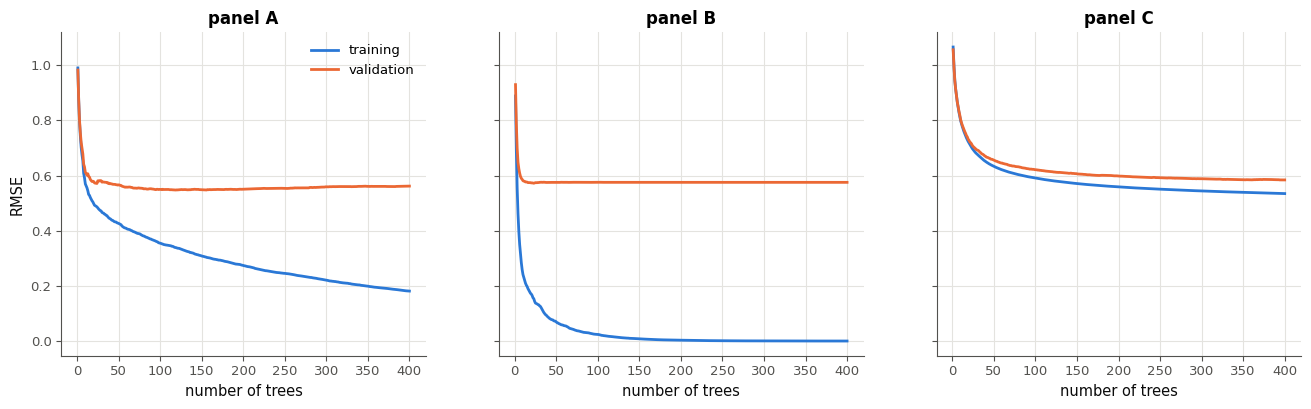

In [48]:
ORDER_20 = np.random.default_rng(1421).permutation([1, 3, 8])   # the depths of panels A, B and C, in a hidden order
CURVES_20 = {panel: boosting_curves(max_depth=int(depth), learning_rate=0.3, n_estimators=400)
             for panel, depth in zip("ABC", ORDER_20)}                 # panel -> (training RMSE, validation RMSE)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (panel, (train, validation)) in zip(axes, CURVES_20.items()):
    ax.plot(np.arange(1, 401), train, label="training")
    ax.plot(np.arange(1, 401), validation, label="validation")
    ax.set_xlabel("number of trees")
    ax.set_title(f"panel {panel}")
axes[0].set_ylabel("RMSE")
axes[0].legend()
plt.show()
del ORDER_20                         # the answer is not kept in the notebook

In [49]:
order_20 = np.random.default_rng(1421).permutation([1, 3, 8])        # recomputed for the record only
panel_of_20 = {int(depth): panel for panel, depth in zip("ABC", order_20)}
overfit_20, underfit_20 = panel_of_20[8], panel_of_20[1]
best_trees_20 = [int(np.argmin(CURVES_20[panel][1])) + 1 for panel in "ABC"]
middle_20 = CURVES_20[panel_of_20[3]][1]
best_middle_20 = int(np.argmin(middle_20)) + 1
stop_20 = "A" if best_middle_20 < 50 else "B" if best_middle_20 <= 300 else "C" if best_middle_20 < 400 else "D"
gap_20 = float(middle_20[-1] - middle_20.min())
print("depths of panels A, B, C:", order_20.tolist(), "· trees at the validation minimum:", best_trees_20)

depths of panels A, B, C: [3, 8, 1] · trees at the validation minimum: [155, 23, 397]


In [50]:
wb.record("14.20a", overfit_20,
          mistakes={f"panneau {panel} : sa RMSE d'entraînement tombe-t-elle presque à 0 pendant que celle de validation reste bien plus haute ?": panel
                    for panel in "ABC" if panel != overfit_20})
wb.record("14.20b", underfit_20,
          mistakes={f"panneau {panel} : ses deux courbes descendent-elles encore ensemble, proches l'une de l'autre, à 400 arbres ?": panel
                    for panel in "ABC" if panel != underfit_20})
wb.record("14.20c", stop_20,
          mistakes={f"choix {choice} : repère le point le plus bas de la courbe de validation du panneau restant (ni celui de a), ni celui de b)), et lis son abscisse": choice
                    for choice in "ABCD" if choice != stop_20})
wb.record("14.20d", best_trees_20,
          mistakes={"np.argmin rend une position qui commence à 0 : un nombre d'arbres commence à 1": [b - 1 for b in best_trees_20],
                    "c'est le minimum de la RMSE d'entraînement : on demande celui de la validation": [int(np.argmin(CURVES_20[p][0])) + 1 for p in "ABC"]})
wb.record("14.20e", gap_20, decimals=3, mistakes={"le signe : la valeur après 400 arbres moins le minimum": -gap_20})

WB_ANSWER {"hash": "08c3786de0f4eefad2407aa5245c525f1823361997eb2aa976ff75978e02ea6c", "id": "14.20a", "kind": "str", "mistakes": {"0ee6f71d13a1c7e1d8e79ba35f35e7ba55f66b732416fbe0605e4d0b1e181347": "panneau C : sa RMSE d'entraînement tombe-t-elle presque à 0 pendant que celle de validation reste bien plus haute ?", "9345f4decfdb396380d9a1a473ee4d6ae09272321d21a8fc9922890cab39bd73": "panneau A : sa RMSE d'entraînement tombe-t-elle presque à 0 pendant que celle de validation reste bien plus haute ?"}}
📝 Ex 14.20a : réponse enregistrée (str).
WB_ANSWER {"hash": "84c67997eed0ead5211a2da83d275f8482911e070fb9c2c144cfe73a3d69c845", "id": "14.20b", "kind": "str", "mistakes": {"4bf74616e7b790059e0230d45de9f193f145421ae7728f6e72579066b0f36f18": "panneau B : ses deux courbes descendent-elles encore ensemble, proches l'une de l'autre, à 400 arbres ?", "f2a7c1e462083a99c1eb7384a02d29732945f50539a3bc846db54539cfbfc438": "panneau A : ses deux courbes descendent-elles encore ensemble, proches l'une d

💡 Le panneau de profondeur 8 apprend l'entraînement par cœur (RMSE d'entraînement presque nulle, 0,02, après une centaine d'arbres), et sa validation est au plus bas dès 23 arbres, puis stagne vers 0,575 : chaque arbre de profondeur 8 (jusqu'à 256 feuilles, environ 200 pour les premiers) colle au bruit. Le panneau de profondeur 1 (des souches) est encore en underfitting : ses deux courbes descendent ensemble, à 0,535 et 0,584 après 400 arbres, et son minimum est presque au dernier arbre (397). Le panneau de profondeur 3 a le meilleur minimum (0,547 à 155 arbres), puis remonte doucement (0,562 à 400) : c'est l'overfitting progressif d'un boosting, que l'early stopping arrête. On garderait 155 arbres pour la profondeur 3, une vingtaine pour la profondeur 8 ; les souches demandent plus d'arbres, ou un learning rate plus grand. Le meilleur choix est la profondeur 3, avec un learning rate plus petit et plus d'arbres (🔮 14.21).

### Ex 14.21 — Learning rate et nombre d'arbres : prédire les courbes 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir, en nombres, ce que le learning rate change au nombre d'arbres utile et à l'erreur de validation.  
**Prérequis :** Ex 14.20 · fiche, section sur le gradient boosting (le learning rate et le nombre d'arbres) · **Fil rouge :** California · **Parcours :** C

Mêmes données que 14.20, des arbres de profondeur 3, jusqu'à 1 000 arbres, et cinq learning rates : 0,02 ; 0,05 ; 0,1 ; 0,5 et 1. La fiche te dit déjà le sens des effets (un petit learning rate demande plus d'arbres et généralise d'ordinaire mieux) ; prédis plutôt leur **taille**.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `ratio_21` : en passant de 0,5 à 0,05 (un learning rate divisé par 10), le nombre d'arbres au minimum de la RMSE de validation est multiplié par environ : `"A"` 1 ; `"B"` 3 ; `"C"` 10 ; `"D"` 100 ;
b) `gain_21` : la meilleure RMSE de validation avec 0,05, comparée à celle avec 0,5 : `"A"` moins bonne ; `"B"` meilleure de moins de 0,005 ; `"C"` meilleure de 0,005 à 0,1 ; `"D"` meilleure de plus de 0,1 ;
c) `slow_beats_21` : avec 0,02, la meilleure RMSE de validation **en 1 000 arbres au plus** est-elle plus basse qu'avec 0,1 ? (`True` ou `False`)

Puis exécute l'expérience (une quarantaine de secondes) : elle affiche, pour chaque learning rate, le nombre d'arbres au minimum, la meilleure RMSE de validation, la RMSE après 1 000 arbres et la RMSE d'entraînement, et trace les courbes de validation.

In [51]:
LRS_21 = [0.02, 0.05, 0.1, 0.5, 1.0]   # learning rates, all with trees of depth 3 and up to 1,000 trees

In [52]:
ratio_21, gain_21, slow_beats_21 = "C", "C", False   # the answers, for the record

In [53]:
wb.record("14.21a", "C", mistakes={"le learning rate multiplie chaque arbre : pour la même correction totale, faut-il autant d'arbres avec des pas dix fois plus petits ?": "A",
                                     "chaque arbre ne corrige qu'une fraction η de ce qui reste : avec η dix fois plus petit, combien d'arbres pour la même correction ?": "B",
                                     "dix fois plus petit, est-ce cent fois plus d'arbres ? pense à une somme de pas de taille η": "D"})
wb.record("14.21b", "C", mistakes={"un petit learning rate corrige moins vite : est-ce qu'il finit par moins bien généraliser, si on lui laisse assez d'arbres ?": "A",
                                    "avec η = 0,5, chaque arbre colle fortement au bruit de l'entraînement : l'écart reste-t-il si petit ?": "B",
                                    "une RMSE de validation vers 0,5 : peut-elle gagner plus de 0,1 par le seul learning rate ?": "D"})
wb.record("14.21c", False, mistakes={"un learning rate de 0,02 avance cinq fois moins vite que 0,1 : 1 000 arbres suffisent-ils à l'amener au même niveau ?": True})

WB_ANSWER {"hash": "5bace1d3787c35a2497242566f8240896ef7fe95224783da90c996c380356e6a", "id": "14.21a", "kind": "str", "mistakes": {"124b3888567138c72638627190e761101a68a88a291b3742be4fc271326d7f3d": "dix fois plus petit, est-ce cent fois plus d'arbres ? pense à une somme de pas de taille η", "3a6a1f205aa0b4de999aaf2d1256a4d1216b35bd995cb37542d9fce8de46987f": "le learning rate multiplie chaque arbre : pour la même correction totale, faut-il autant d'arbres avec des pas dix fois plus petits ?", "9ece424fcf5e2af21d3bbbb56cbbe58c476836f0a75c9f5a26c2d0e31ccf1cb5": "chaque arbre ne corrige qu'une fraction η de ce qui reste : avec η dix fois plus petit, combien d'arbres pour la même correction ?"}}
📝 Ex 14.21a : réponse enregistrée (str).
WB_ANSWER {"hash": "29e8d1a182c2fdcf8511e60802d1a91e2d006b8b87d3ccf77f4751853419f82e", "id": "14.21b", "kind": "str", "mistakes": {"1148c11c0e1642af1f0eae1f537455ca2be9cf068f946edcc8a69299bc8c0b77": "une RMSE de validation vers 0,5 : peut-elle gagner plus de

 learning rate · trees at the minimum · best validation RMSE · after 1,000 trees · training RMSE after 1,000 trees
          0.02 ·                 992 ·                   0.5326 ·            0.5326 · 0.3991
          0.05 ·                 964 ·                   0.5243 ·            0.5245 · 0.2992
          0.10 ·                 652 ·                   0.5232 ·            0.5247 · 0.2106
          0.50 ·                  96 ·                   0.5762 ·            0.5863 · 0.0268
          1.00 ·                  31 ·                   0.6307 ·            0.7109 · 0.0062


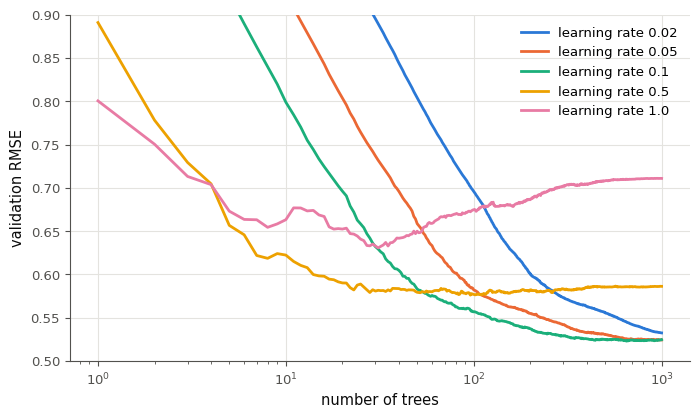

✅ Ex 14.21a : C'est ça !
✅ Ex 14.21b : Parfait !
✅ Ex 14.21c : Bravo !


In [54]:
if any(answer is ... or answer is None for answer in [ratio_21, gain_21, slow_beats_21]):
    print("⏳ Ex 14.21 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    curves_21 = {lr: boosting_curves(max_depth=3, learning_rate=lr, n_estimators=1000) for lr in LRS_21}   # ≈ 40 s
    print(" learning rate · trees at the minimum · best validation RMSE · after 1,000 trees · training RMSE after 1,000 trees")
    for lr, (train, validation) in curves_21.items():
        print(f"{lr:14.2f} · {int(np.argmin(validation)) + 1:19d} · {validation.min():24.4f} · {validation[-1]:17.4f} · "
              f"{train[-1]:.4f}")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for lr, (train, validation) in curves_21.items():
        ax.plot(np.arange(1, 1001), validation, label=f"learning rate {lr}")
    ax.set_xscale("log")
    ax.set_ylim(0.5, 0.9)
    ax.set_xlabel("number of trees")
    ax.set_ylabel("validation RMSE")
    ax.legend()
    plt.show()
    wb.check("14.21a", ratio_21)
    wb.check("14.21b", gain_21)
    wb.check("14.21c", slow_beats_21)

Dans tes notes : compare avec tes prédictions. Le produit « learning rate × nombre d'arbres au minimum » est-il à peu près constant ? Que se passe-t-il à droite du minimum pour les grands learning rates, et pour 0,02 ? Quel couple (learning rate, nombre d'arbres) choisirais-tu, avec quel budget de temps ?

💡 De 0,5 à 0,05, le minimum passe de 96 à 964 arbres : 10 fois plus, comme le learning rate est 10 fois plus petit (le produit learning rate × arbres reste vers 48 à 65 pour 0,05, 0,1 et 0,5 ; 31 pour 1, qui colle au bruit dès les premiers arbres ; 20 pour 0,02, qui n'a pas fini). La meilleure RMSE de validation passe de 0,576 à 0,524 : 0,052 de mieux. Avec 0,02, la courbe est encore presque à son plus bas au 1 000ᵉ arbre (0,533 ; elle descendrait jusqu'à 0,522 vers 1 900 arbres) et reste au-dessus de celle de 0,1 (0,523 à 652 arbres) : un learning rate trop petit coûte des arbres, donc du temps, sans gain dans un budget fixé. Avec 1, le minimum arrive après 31 arbres (0,631), puis la validation remonte à 0,711 : le modèle colle au bruit. Sur huit autres tranches de 3 000 districts d'entraînement et 2 000 de validation prises dans `X_CAL_TRAIN` (de `[1000:6000]` à `[11500:16500]`), le rapport reste entre 7 et 16 (toujours plus proche de 10 que de 3 ou de 100), le gain entre 0,010 et 0,044, et 0,02 reste derrière 0,1.

### Ex 14.22 — Frontières d'AdaBoost après 1, 3, 10 et 50 souches 🎨 ★★ ⏱️ 25 min
**Objectif :** voir un ensemble de souches découper le plan, tour après tour.  
**Prérequis :** ✏️ 14.6 · ch. 13 (souches, frontières) · fiche §14.7 (AdaBoost) · **Fil rouge :** synthétique · **Parcours :** C

Deux demi-lunes bruitées (300 points, `X_22`) et l'`AdaBoostClassifier` de scikit-learn, dont les membres par défaut sont des souches. Écris :
- `model_22` : `AdaBoostClassifier(n_estimators=50, random_state=0)` entraîné sur `X_22`, `Y_22` ;
- `stage_predictions_22(model, X, rounds)` : un dictionnaire qui associe à chaque $m$ de `rounds` les prédictions du modèle sur `X` quand il ne garde que ses $m$ premiers membres (`model.staged_predict(X)` donne celles après 1, 2, 3… membres) ;
- `draw_22(model, X, y, rounds)` : une figure de `len(rounds)` panneaux ; dans le panneau $m$, les régions prédites sur la grille `GRID_22` après $m$ membres (remises à la forme de `GRID1_22`, avec `ax.contourf`), les points d'entraînement colorés par classe, et un titre avec $m$ et l'accuracy d'entraînement après $m$ membres ; elle rend la figure ;
- `train_acc_22` : la liste des accuracies d'entraînement après 1, 3, 10 et 50 membres (`ROUNDS_22`).

La vérification contrôle `train_acc_22`, vérifie qu'après une souche les régions sont coupées par une seule droite parallèle à un axe, puis appelle `draw_22`.

Dans tes notes : décris la frontière après 3 souches, puis après 50. Pourquoi est-elle toujours faite de segments horizontaux et verticaux ? Où l'ensemble finit-il par dessiner de petits rectangles, et est-ce bon signe ?

In [55]:
X_22, Y_22 = wb.synth.make_moons(n=300, noise=0.25, seed=1422)
ROUNDS_22 = [1, 3, 10, 50]
GRID1_22, GRID2_22 = np.meshgrid(np.linspace(-1.6, 2.6, 160), np.linspace(-1.2, 1.7, 110))
GRID_22 = np.column_stack([GRID1_22.ravel(), GRID2_22.ravel()])   # 17,600 points that cover the moons

14.22a: [0.82, 0.9233, 0.9267, 0.9667]


✅ Ex 14.22 : après une souche, une seule coupure parallèle à un axe ; après 50, les prédictions de model_22.


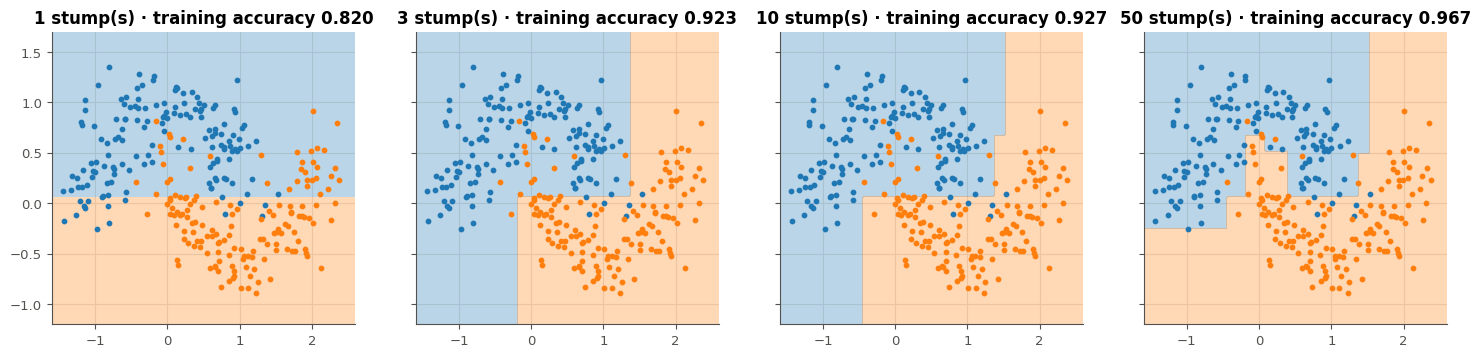

In [56]:
model_22 = AdaBoostClassifier(n_estimators=50, random_state=0).fit(X_22, Y_22)


def stage_predictions_22(model, X, rounds):
    """Return a dict {m: the predictions of the fitted AdaBoost `model` on X when it keeps only its first m members},
    for each m of `rounds` (use model.staged_predict, which yields the predictions after 1, 2, 3... members)."""
    wanted = set(rounds)
    return {m: predicted for m, predicted in enumerate(model.staged_predict(X), start=1) if m in wanted}


def draw_22(model, X, y, rounds):
    """Draw 1 x len(rounds) panels: in panel m, the regions predicted after m members on GRID_22 (reshaped like
    GRID1_22, e.g. with ax.contourf), the training points X coloured by y, and a title with m and the training
    accuracy after m members. Return the figure."""
    on_grid = stage_predictions_22(model, GRID_22, rounds)
    on_train = stage_predictions_22(model, X, rounds)
    fig, axes = plt.subplots(1, len(rounds), figsize=(4.5 * len(rounds), 3.8), sharey=True)
    for ax, m in zip(axes, rounds):
        ax.contourf(GRID1_22, GRID2_22, on_grid[m].reshape(GRID1_22.shape), levels=[-0.5, 0.5, 1.5], alpha=0.3,
                    colors=["tab:blue", "tab:orange"])
        ax.scatter(*X[y == 0].T, s=10, c="tab:blue")
        ax.scatter(*X[y == 1].T, s=10, c="tab:orange")
        ax.set_title(f"{m} stump(s) · training accuracy {np.mean(on_train[m] == y):.3f}")
    return fig


train_acc_22 = [float(np.mean(stage_predictions_22(model_22, X_22, ROUNDS_22)[m] == Y_22)) for m in ROUNDS_22]
print_answer("14.22a", train_acc_22)
if True:
    if not filled(model_22):
        raise NotImplementedError("model_22")
    stages_22 = stage_predictions_22(model_22, GRID_22, ROUNDS_22)
    if returned("14.22", "stage_predictions_22", stages_22) and not (isinstance(stages_22, dict) and set(ROUNDS_22) <= set(stages_22)):
        print("❌ Ex 14.22 : stage_predictions_22 doit rendre un dictionnaire {m: prédictions} avec une clé pour chaque m "
              f"de ROUNDS_22 ({ROUNDS_22}).")
    elif stages_22 is not None:
        first_22 = np.asarray(stages_22[1]).reshape(GRID1_22.shape)
        one_cut_22 = (first_22 == first_22[:1, :]).all() or (first_22 == first_22[:, :1]).all()
        verdict("14.22", one_cut_22 and np.array_equal(np.asarray(stages_22[50]), model_22.predict(GRID_22)),
                "après une souche, une seule coupure parallèle à un axe ; après 50, les prédictions de model_22.",
                "attendu : après 1 membre, des régions coupées par une seule droite verticale ou horizontale (une "
                "souche), et après 50 membres les prédictions de model_22.predict ; relis staged_predict.")
        figure_22 = draw_22(model_22, X_22, Y_22, ROUNDS_22)
        if returned("14.22", "draw_22", figure_22):
            plt.show()

In [57]:
wb.record("14.22a", train_acc_22, decimals=3)

WB_ANSWER {"decimals": 3, "element_coarse": [["bd089d76da5f7602786208030674c5bf4459582e77314a30dc15fca04139c958"], ["5fc20df70bd76b06577f926e4967091e2ab44b22eabeef23f50c8951b1629369"], ["f9ccdd9f4d22ae5d41b9687642f6a110a318a39f33484c06aff7823fb4fecd1a"], ["e9fbf40e8d10caf02565bff7c508079a3a8e6c813d5d9563b8f8b6e51ff589c8"]], "element_hashes": ["b797225fcc8ec9b3d5b41d228c758809247c3c01c1899cb6e686e3c9ce13b1e2", "07506dd13c415f611d3ff7dc45f350b01c3352b3ab7a69dd356b513484049b07", "01a8f9534d890941a3272eb22388d246cdfcfa266425a486f6f7911c17e06e51", "3ede7c0565f1257caac4897e26f908374df2c4abacfbe3d984bbc0755e66224a"], "hash": "a78655cdd026bb98db65fa6fdd3744b54df97dc6c11197277d57dc2fd5bffddb", "id": "14.22a", "kind": "array", "shape": [4]}
📝 Ex 14.22a : réponse enregistrée (array, 3 décimale(s)).


💡 Après une souche, une seule coupure horizontale ($x_2$ vers 0,06) : 0,820 d'accuracy d'entraînement. Après trois, un escalier grossier (0,923) ; après dix, l'escalier suit l'allure des lunes (0,927) ; après 50, la frontière contourne aussi des points isolés de l'autre classe par de petits rectangles (0,967 sur l'entraînement). Chaque souche pose une question sur **une** coordonnée, et la somme pondérée de leurs votes ne change qu'en franchissant l'un de leurs seuils : la frontière est faite de segments parallèles aux axes. Les petits rectangles autour de points isolés sont le début de l'overfitting : AdaBoost donne de plus en plus de poids aux points qu'il classe mal, souvent des points bruités. On le contrôle par le nombre de tours et le learning rate, choisis sur une validation.

### Ex 14.23 — L'AdaBoost qui n'apprend rien 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les erreurs d'un AdaBoost écrit à la main, en s'aidant de ses propriétés.  
**Prérequis :** ✏️ 14.6 · fiche §14.7 (pseudo-code d'AdaBoost) · **Fil rouge :** synthétique · **Parcours :** C

Un collègue a écrit `adaboost_23`, un AdaBoost (SAMME, deux classes 0 et 1) avec des souches de scikit-learn, et `predict_23`, son vote pondéré (correct). Son accuracy d'entraînement ne bouge pas, quel que soit le nombre de tours. Il y a **trois** erreurs dans `adaboost_23` : trouve-les et corrige-les (sans changer sa signature ni ce qu'elle rend), en t'aidant du pseudo-code de la fiche (§14.7).

La vérification lance ta version sur 400 points de deux demi-lunes, puis contrôle trois propriétés, dans l'ordre où les erreurs se masquent (un point ne se teste que si les précédents passent) : 1) après le premier tour, la mise à jour alourdit les exemples que la souche a mal classés, par rapport aux autres ; 2) les poids avec lesquels chaque souche est entraînée somment à 1 ; 3) les souches changent d'un tour à l'autre. Quand les trois points passent, elle vérifie a) l'accuracy d'entraînement des 40 tours et b) le poids $\alpha$ de la **deuxième** souche, puis compare ta version à l'`AdaBoostClassifier` de scikit-learn.

Dans tes notes : pour chaque erreur, le symptôme qu'elle provoque seule. Lesquelles des trois erreurs, seules, figent l'accuracy ? Une fois tout corrigé, pourquoi les exemples que la souche précédente classait mal pèsent-ils exactement la moitié du total après chaque mise à jour (à deux classes, avec $\alpha = \ln\frac{1 - \varepsilon}{\varepsilon}$) ?

In [58]:
X_23, Y_23 = wb.synth.make_moons(n=400, noise=0.3, seed=1423)   # two classes, 0 and 1


def predict_23(stumps, alphas, X):
    """Weighted vote of the stumps (correct, nothing to fix): the class whose stumps have the largest sum of alphas."""
    votes = np.zeros((len(X), 2))
    for stump, alpha in zip(stumps, alphas):
        votes[np.arange(len(X)), stump.predict(X)] += alpha
    return np.argmax(votes, axis=1)

In [59]:
def adaboost_23(X, y, n_rounds=40):
    """AdaBoost with scikit-learn stumps. Return (stumps, alphas, weights), where weights[m] is the vector of sample
    weights (summing to 1) with which stump m was fitted."""
    n = len(X)
    w = np.full(n, 1 / n)
    stumps, alphas, weights = [], [], []
    for m in range(n_rounds):
        w = w / w.sum()                                  # fix 2: normalise, so that err is a weighted error rate
        weights.append(w.copy())
        stump = DecisionTreeClassifier(max_depth=1, random_state=m)
        stump.fit(X, y, sample_weight=w)                 # fix 3: the stump must see the weights
        wrong = stump.predict(X) != y
        err = np.sum(w[wrong])
        alpha = np.log((1 - err) / err)
        w = w * np.exp(alpha * wrong)                    # fix 1: the MISclassified samples weigh more
        stumps.append(stump)
        alphas.append(alpha)
    return stumps, alphas, weights
if True:
    try:
        with np.errstate(all="ignore"):
            result_23 = adaboost_23(X_23, Y_23)
        crash_23 = None
    except ValueError as exc:                            # NaN weights refused by scikit-learn
        if "nan" not in str(exc).lower() and "infinity" not in str(exc).lower():
            raise
        result_23, crash_23 = None, exc
    if crash_23 is not None:
        print("❌ Ex 14.23 : point 1 : les poids sont devenus NaN ou infinis (scikit-learn refuse alors d'entraîner la "
              "souche) : l'erreur pondérée est tombée à 0 et α est devenu infini. Relis quels exemples la mise à jour "
              "doit alourdir.")
        print("⏳ Ex 14.23 : points 2 et 3, puis a) et b) : corrige d'abord le point 1.")
    elif returned("14.23", "adaboost_23", result_23):
        stumps_23, alphas_23, weights_23 = result_23
        weights_23 = [np.asarray(w, dtype=float) for w in weights_23]
        wrong0_23 = stumps_23[0].predict(X_23) != Y_23
        with np.errstate(all="ignore"):
            growth_23 = weights_23[1] / weights_23[0]        # how the update changed each weight after round 1
        cuts_23 = {(int(s.tree_.feature[0]), round(float(s.tree_.threshold[0]), 6)) for s in stumps_23}
        diagnostics_23 = [
            ("après le premier tour, la mise à jour alourdit les exemples que la souche a mal classés, par rapport aux "
             "autres", bool(np.mean(growth_23[wrong0_23]) > np.mean(growth_23[~wrong0_23]) * (1 + 1e-9))),
            ("les poids avec lesquels chaque souche est entraînée somment à 1",
             all(np.isfinite(w).all() and abs(w.sum() - 1) < 1e-9 for w in weights_23)),
            ("les souches changent d'un tour à l'autre", len(cuts_23) > 1),
        ]
        all_ok_23, failed_23 = True, None
        for k, (what, ok) in enumerate(diagnostics_23, start=1):
            if not all_ok_23:
                print(f"⏳ Ex 14.23 : point {k} ({what}) : corrige d'abord le point {failed_23}.")
                continue
            verdict("14.23", ok, f"point {k} : {what}.", f"point {k} : attendu : {what}.")
            if not ok:
                all_ok_23, failed_23 = False, k
        with np.errstate(all="ignore"):
            accuracy_23 = float(np.mean(predict_23(stumps_23, alphas_23, X_23) == Y_23))
        print(f"training accuracy of the 40 rounds: {accuracy_23:.3f} · of the first stump alone: "
              f"{float(np.mean(stumps_23[0].predict(X_23) == Y_23)):.3f}")
        if not all_ok_23:
            print(f"⏳ Ex 14.23a et 14.23b : corrige d'abord le point {failed_23}.")
        else:                                            # a) and b) only once the three points pass
            print_answer("14.23a", accuracy_23, computed=True)
            print_answer("14.23b", float(alphas_23[1]), computed=True)
            oracle_23 = AdaBoostClassifier(n_estimators=40, random_state=0).fit(X_23, Y_23)
            verdict("14.23", np.array_equal(predict_23(stumps_23, alphas_23, X_23), oracle_23.predict(X_23))
                    and np.allclose(alphas_23, oracle_23.estimator_weights_),
                    "mêmes poids des souches et mêmes prédictions que l'AdaBoostClassifier de scikit-learn.",
                    "tes poids de souches ou tes prédictions diffèrent de ceux de l'AdaBoostClassifier de scikit-learn.")

✅ Ex 14.23 : point 1 : après le premier tour, la mise à jour alourdit les exemples que la souche a mal classés, par rapport aux autres.
✅ Ex 14.23 : point 2 : les poids avec lesquels chaque souche est entraînée somment à 1.
✅ Ex 14.23 : point 3 : les souches changent d'un tour à l'autre.
training accuracy of the 40 rounds: 0.897 · of the first stump alone: 0.820
14.23a: 0.8975
14.23b: 1.035466175544376
✅ Ex 14.23 : mêmes poids des souches et mêmes prédictions que l'AdaBoostClassifier de scikit-learn.


In [60]:
def variant_23(n_rounds=40, weights_ok=True, normalise=True, update="wrong"):
    """The function of the statement with some of its bugs left (to compute the classic mistakes)."""
    w = np.full(len(X_23), 1 / len(X_23))
    stumps, alphas = [], []
    for m in range(n_rounds):
        if normalise:
            w = w / w.sum()
        stump = DecisionTreeClassifier(max_depth=1, random_state=m)
        stump.fit(X_23, Y_23, sample_weight=w if weights_ok else None)
        wrong = stump.predict(X_23) != Y_23
        err = np.sum(w[wrong])
        alpha = np.log((1 - err) / err)
        w = w * np.exp(alpha * (wrong if update == "wrong" else ~wrong))
        stumps.append(stump)
        alphas.append(alpha)
    return float(np.mean(predict_23(stumps, alphas, X_23) == Y_23)), float(alphas[1])


def safe_variant_23(**bugs):
    """variant_23, or (nan, nan) when the bugs make it crash (an error of 0 gives an infinite alpha)."""
    try:
        with np.errstate(all="ignore"):
            return variant_23(**bugs)
    except ValueError:
        return float("nan"), float("nan")


right_23 = variant_23()
classic_23 = {"c'est l'accuracy de la première souche seule : l'ensemble n'apprend rien de plus. Regarde si tes souches changent d'un tour à l'autre, et ce que valent les poids au début de chaque tour": safe_variant_23(weights_ok=False),
              "l'ensemble fait moins bien que sa première souche : ses α changent de signe d'un tour à l'autre et s'annulent ; regarde ce que valent les poids au début de chaque tour": safe_variant_23(weights_ok=False, normalise=False)}
wb.record("14.23a", right_23[0], decimals=4,
          mistakes={message: value[0] for message, value in classic_23.items()
                    if np.isfinite(value[0]) and round(value[0], 4) != round(right_23[0], 4)})
wb.record("14.23b", right_23[1], decimals=4,
          mistakes={"α nul : la deuxième souche se trompe sur la moitié exacte des poids, comme si c'était encore la première ; regarde ce que voit la souche quand elle s'entraîne": safe_variant_23(weights_ok=False)[1],
                    "un α négatif : l'erreur pondérée de la deuxième souche dépasse 0,5 ; regarde ce que valent les poids au début de chaque tour": safe_variant_23(weights_ok=False, normalise=False)[1],
                    "α faussé : err n'est pas une proportion ; regarde ce que valent les poids au début de chaque tour": safe_variant_23(normalise=False)[1],
                    "la formule de la fiche n'a pas de facteur 1/2 : α = ln((1 − ε)/ε) à deux classes": right_23[1] / 2})

WB_ANSWER {"alt_coarse": ["e6bf041b9a1e6a5381da86c0a24ab4507a8a75fbab26deba35d20d539cf10968"], "decimals": 4, "hash": "3b5ee3fa9ef842d0beef7c38b1eb578af7f1c271cd1417413204a1ca9c5fa3d0", "hash_coarse": "8327ef103a3f2f7b38661eda7267147891d9d8e691d3abfa1e33dd0037abce14", "id": "14.23a", "kind": "float", "magnitude": -1, "mistakes": {"09375a7f4d54f0783f035bd5dd10b3127d7e8b63d8ec0fff6e5449763d5a73cd": "l'ensemble fait moins bien que sa première souche : ses α changent de signe d'un tour à l'autre et s'annulent ; regarde ce que valent les poids au début de chaque tour", "e7d0a595898a4d71b3948ebef8944d6aa384a0be3d9601303bcfd883a33b68ad": "c'est l'accuracy de la première souche seule : l'ensemble n'apprend rien de plus. Regarde si tes souches changent d'un tour à l'autre, et ce que valent les poids au début de chaque tour"}, "sign": 1}
📝 Ex 14.23a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "17c567bee26c8c6c9a92f4eda3004d0e218dde3b05d7672d0f960bfb6c6c0e1c", 

💡 Les trois erreurs, dans l'ordre des points : la mise à jour alourdit les exemples **bien** classés (`== y` au lieu de `!= y`) ; les poids ne sont jamais renormalisés, si bien que `err` n'est plus une proportion (ici elle dépasse 0,5, et $\alpha$ devient négatif) ; la souche est entraînée sans `sample_weight`, et toutes les souches sont alors la même. Deux d'entre elles, seules, figent l'accuracy à celle de la première souche (0,820) : l'oubli de `sample_weight` et celui de la normalisation ; la mauvaise mise à jour, seule, fait tomber l'erreur pondérée à 0, $\alpha$ devient infini et les poids NaN. Une fois tout corrigé, les mal classés pesaient $\varepsilon$ et sont multipliés par $e^\alpha = (1 - \varepsilon)/\varepsilon$ : ils pèsent $1 - \varepsilon$, autant que les bien classés ; après normalisation, chaque groupe vaut la moitié, la souche précédente fait exactement comme le hasard sur les nouveaux poids, et la suivante doit trouver autre chose. Corrigée, la fonction donne les mêmes poids et les mêmes prédictions que scikit-learn.

### Ex 14.24 — Coder AdaBoost (SAMME) avec des souches pondérées 🔨 ★★★ ⏱️ 75 min
**Objectif :** écrire AdaBoost multi-classe sur tes souches, identique à celui de scikit-learn.  
**Prérequis :** ✏️ 14.6 · Ex 13.25 (`sample_weight`) · Ex 14.23 · fiche §14.7 (pseudo-code) · **Fil rouge :** synthétique · **mylearn :** `ensemble.py` · **Parcours :** C

> **mylearn** : dans `mon_travail/mylearn/ensemble.py`, mêmes règles qu'en 14.17. Enregistre, puis relance la cellule de vérification.

Écris la classe `AdaBoostClassifier`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `__init__` range ses quatre arguments tels quels ; le gabarit est `estimator`, ou `DecisionTreeClassifier(max_depth=1)` de **ton** `tree.py` si `estimator` vaut `None` ; il n'est jamais entraîné lui-même : chaque membre est un `clone`, qui reçoit, s'il a un `random_state`, un entier tiré d'un générateur `np.random.default_rng(random_state)` créé dans `fit` (comme le bagging) ;
- `fit` vérifie **d'abord** que le `fit` du gabarit a un paramètre `sample_weight`, avant tout entraînement ; puis les poids partent de $1/n$ ; à chaque tour : normaliser les poids (somme 1), entraîner le clone avec `sample_weight`, calculer `err` (la somme des poids des mal classés) ; si `err == 0`, garder le membre avec le poids 1,0 et l'erreur 0,0, et s'arrêter ; si `err >= 1 - 1/K`, rejeter le membre et s'arrêter (`ValueError` si c'était le tout premier : l'ensemble serait vide) ; sinon $\alpha = \eta\,(\ln\frac{1 - \text{err}}{\text{err}} + \ln(K - 1))$, garder le membre et multiplier par $e^\alpha$ le poids des mal classés ;
- attributs : `classes_` (labels triés, au moins 2 : `ValueError` sinon), `estimators_`, `estimator_weights_` et `estimator_errors_` (des tableaux NumPy, un élément par membre gardé) ; `ValueError` aussi pour `n_estimators < 1`, `learning_rate <= 0`, `NaN` ou `len(X) != len(y)` ;
- `decision_function(X)` rend un tableau `(n, K)` : pour chaque classe, la somme des $\alpha_m$ des membres qui la prédisent, divisée par la somme de tous les $\alpha_m$ ; `predict(X)` la classe de plus grand vote (à égalité, la première de `classes_`) ; `staged_predict(X)` est une **fonction génératrice** qui donne les prédictions après 1, 2, … membres ; `score(X, y)` l'accuracy, un `float` Python ; `RuntimeError` avant `fit`.

La vérification essaie l'exemple de la docstring, compare ton AdaBoost à celui de scikit-learn sur trois classes (poids, erreurs, prédictions après chaque tour, avec deux réglages), contrôle `decision_function`, puis lance les tests.

Dans tes notes : pourquoi vérifier la signature avant tout entraînement ? À deux classes, que vaut $\ln(K - 1)$ ? À trois classes, quel $\alpha$ la formule sans ce terme donnerait-elle à un membre qui se trompe sur 55 % des poids ?

In [61]:
with checked("14.24"):
    X_doc_24, y_doc_24 = np.arange(1.0, 8.0).reshape(-1, 1), np.array([0, 0, 0, 1, 1, 0, 1])
    doc_24 = fitted(mylearn.ensemble.AdaBoostClassifier(n_estimators=3), X_doc_24, y_doc_24)
    print("docstring example: errors", np.round(np.asarray(doc_24.estimator_errors_, dtype=float), 4).tolist(),
          "(expected [0.1429, 0.1667, 0.2]) · weights", np.round(np.asarray(doc_24.estimator_weights_, dtype=float), 4).tolist(),
          "(expected [1.7918, 1.6094, 1.3863])")
with checked("14.24"):
    X_24, y_24 = wb.synth.make_blobs(n=400, centers=3, std=4.0, seed=1424)   # three overlapping classes
    X_24 = X_24.astype(np.float32).astype(float)                              # continuous data, no ties
    X_train_24, y_train_24, X_test_24 = X_24[:300], y_24[:300], X_24[300:]
    for params in [{"n_estimators": 20}, {"n_estimators": 15, "learning_rate": 0.5}]:
        start_24 = time.perf_counter()
        mine_24 = fitted(mylearn.ensemble.AdaBoostClassifier(**params), X_train_24, y_train_24)
        seconds_24 = time.perf_counter() - start_24
        oracle_24 = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=0, **params).fit(X_train_24, y_train_24)
        k_24 = len(mine_24.estimators_)
        same_weights_24 = (k_24 == len(oracle_24.estimators_)
                           and np.allclose(mine_24.estimator_weights_, oracle_24.estimator_weights_[:k_24])
                           and np.allclose(mine_24.estimator_errors_, oracle_24.estimator_errors_[:k_24]))
        same_stages_24 = all(np.array_equal(np.asarray(a), b) for a, b in
                             zip(mine_24.staged_predict(X_test_24), oracle_24.staged_predict(X_test_24)))
        verdict("14.24", same_weights_24 and same_stages_24,
                f"{params} : mêmes {k_24} poids, mêmes erreurs et mêmes prédictions après chaque tour que scikit-learn "
                f"(trois classes, en {fr(seconds_24, 2)} s).",
                f"{params} : scikit-learn garde {len(oracle_24.estimators_)} membres, de poids "
                f"{np.round(oracle_24.estimator_weights_[:3], 4).tolist()}… ; toi {k_24}, de poids "
                f"{np.round(np.asarray(mine_24.estimator_weights_[:3], dtype=float), 4).tolist()}… (ou d'autres "
                "prédictions) ; les tests ci-dessous disent où.")
    votes_24 = np.asarray(mine_24.decision_function(X_test_24), dtype=float)
    verdict("14.24", votes_24.shape == (100, 3) and np.allclose(votes_24.sum(axis=1), 1),
            "decision_function rend une ligne de 3 votes normalisés par exemple.",
            (f"decision_function : les lignes doivent sommer à 1 (divise par la somme des α), et non à "
             f"{np.round(votes_24.sum(axis=1)[:3], 4).tolist()}…" if votes_24.shape == (100, 3) else
             f"decision_function doit rendre un tableau (100, 3), une colonne par classe, pas {votes_24.shape}."))
if written(lambda: mylearn.ensemble.AdaBoostClassifier(n_estimators=1).fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="ensemble", keyword="test_ada_boost_classifier_")
else:
    print("⏳ Ex 14.24 : les tests attendent le fit de ton AdaBoostClassifier.")

docstring example: errors [0.1429, 0.1667, 0.2] (expected [0.1429, 0.1667, 0.2]) · weights [1.7918, 1.6094, 1.3863] (expected [1.7918, 1.6094, 1.3863])


✅ Ex 14.24 : {'n_estimators': 20} : mêmes 20 poids, mêmes erreurs et mêmes prédictions après chaque tour que scikit-learn (trois classes, en 0,03 s).
✅ Ex 14.24 : {'n_estimators': 15, 'learning_rate': 0.5} : mêmes 15 poids, mêmes erreurs et mêmes prédictions après chaque tour que scikit-learn (trois classes, en 0,01 s).
✅ Ex 14.24 : decision_function rend une ligne de 3 votes normalisés par exemple.


pytest: 32 passed, 147 deselected in 3.19s


💡 Vérifier la signature d'abord évite un entraînement inutile, et surtout un message obscur : un gabarit sans `sample_weight` lèverait un `TypeError` au premier tour, sans dire pourquoi AdaBoost a besoin de poids. À deux classes, $\ln(K - 1) = \ln 1 = 0$ : SAMME redonne l'AdaBoost à deux classes. Sans ce terme, un membre à trois classes qui se trompe sur 55 % des poids aurait $\alpha = \ln(0{,}45/0{,}55) \approx -0{,}20$, négatif, alors qu'il fait mieux que le hasard (66,7 % d'erreur) ; avec SAMME, il reçoit $\ln(0{,}45/0{,}55) + \ln 2 \approx 0{,}49$ et compte dans le vote.

### Ex 14.25 — Coder un gradient boosting de régression 🔨 ★★★ ⏱️ 60 min
**Objectif :** écrire le gradient boosting de la fiche sur tes arbres de régression, identique à celui de scikit-learn.  
**Prérequis :** ✏️ 14.7 · Ex 13.26 · ch. 9 (MSE, R²) · fiche, section sur le gradient boosting (pseudo-code) · **Fil rouge :** California · **mylearn :** `ensemble.py` et `tree.py` · **Parcours :** M, C

> **mylearn** : dans `mon_travail/mylearn/ensemble.py` (et `tree.py`), mêmes règles qu'en 14.17. Enregistre, puis relance la cellule de vérification.

**D'abord, finis ton arbre de régression** (`tree.py`). Le 13.26 l'a laissé sans les options des ensembles : comme ton `DecisionTreeClassifier` au 13.25, ton `DecisionTreeRegressor` accepte `sample_weight` (un poids 2 équivaut à un exemple répété), `max_features` et `splitter="random"` (avec un générateur créé dans `fit` à partir de `random_state`), et calcule `feature_importances_` (la baisse de variance pondérée, normalisée). Ce sont les options d'une forêt de régression, comme celle de scikit-learn du 14.15.

**Puis écris la classe `GradientBoostingRegressor`** (`ensemble.py`). **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `__init__` range ses six arguments tels quels ; `fit(X, y)` : `init_ = float(np.mean(y))` et $F = $ `init_` pour tous les exemples ; à chaque étape, les lignes de l'étape (toutes, ou, si `subsample < 1`, `max(1, int(subsample * n))` lignes tirées sans remise par **un** générateur créé dans `fit` à partir de `random_state`), un `clone` d'un `DecisionTreeRegressor(max_depth=..., min_samples_leaf=...)` de **ton** `tree.py` ajusté aux résidus $y - F$ de ces lignes, puis $F \leftarrow F + \eta \times$ `tree.predict(X)` pour **tous** les exemples ;
- `train_score_[m]` est la MSE après l'étape $m$ sur les lignes de l'étape (toutes si `subsample=1.0`) ; `estimators_` est la liste des arbres ; `ValueError` pour `n_estimators < 1`, `learning_rate <= 0`, `subsample` hors de $]0, 1]$, `NaN` ou `len(X) != len(y)` ;
- `predict(X)` rend `init_` plus $\eta$ fois la somme des prédictions des arbres, un tableau `float64` ; `staged_predict(X)` est une **fonction génératrice** qui donne les prédictions après 1, 2, … arbres ; `score(X, y)` rend le $R^2$, un `float` Python ; `RuntimeError` avant `fit`.

La vérification contrôle d'abord ton arbre de régression (poids, `max_features`, importances), essaie l'exemple de la docstring, compare ton boosting à celui de scikit-learn sur 400 districts (prédictions après chaque arbre, `init_`, `train_score_`), vérifie `subsample`, puis lance les tests du boosting et ceux de ton arbre de régression qui étaient réservés à ce chapitre (`test_decision_tree_regressor_ensemble_` du ch. 13).

Dans tes notes : pourquoi `predict` peut-il se réduire à parcourir `staged_predict` ? Que mesure `train_score_` avec `subsample=0.5`, et pourquoi n'est-ce plus la MSE d'entraînement ?

In [62]:
with checked("14.25"):
    X_w_25, y_w_25 = wb.synth.make_moons(n=60, noise=0.3, seed=1425)
    X_w_25 = X_w_25.astype(np.float32).astype(float)
    t_w_25 = y_w_25 + X_w_25[:, 0]                                            # a real target
    weighted_25 = fitted(mylearn.tree.DecisionTreeRegressor(max_depth=4), X_w_25, t_w_25, sample_weight=np.full(60, 2.0))
    doubled_25 = fitted(mylearn.tree.DecisionTreeRegressor(max_depth=4), np.vstack([X_w_25, X_w_25]), np.concatenate([t_w_25, t_w_25]))
    first_25 = mylearn.tree.DecisionTreeRegressor(max_features=1, random_state=0)
    a_25 = fitted(first_25, X_w_25, t_w_25).predict(X_w_25)
    b_25 = fitted(first_25, X_w_25, t_w_25).predict(X_w_25)
    oracle_tree_25 = DecisionTreeRegressor(max_depth=4, random_state=0).fit(X_w_25, t_w_25)
    mine_tree_25 = fitted(mylearn.tree.DecisionTreeRegressor(max_depth=4), X_w_25, t_w_25)
    verdict("14.25", np.allclose(weighted_25.predict(X_w_25), doubled_25.predict(X_w_25)) and np.array_equal(a_25, b_25)
            and np.allclose(mine_tree_25.feature_importances_, oracle_tree_25.feature_importances_),
            "ton DecisionTreeRegressor a les options du 13.25 : poids, max_features reproductible, importances.",
            "ton DecisionTreeRegressor doit accepter sample_weight (un poids 2 = un exemple répété), rendre "
            "max_features reproductible avec random_state et calculer feature_importances_ comme scikit-learn ; les "
            "tests du ch. 13 lancés plus bas disent où.")
with checked("14.25"):
    doc_25 = fitted(mylearn.ensemble.GradientBoostingRegressor(n_estimators=2, learning_rate=0.5, max_depth=1),
                    np.array([[1.0], [2.0], [3.0], [4.0]]), np.array([1.0, 1.2, 3.0, 3.4]))
    staged_doc_25 = [np.round(np.asarray(p, dtype=float), 4).tolist() for p in doc_25.staged_predict(np.array([[0.0], [5.0]]))]
    print("docstring example: init_", round(float(doc_25.init_), 4), "(expected 2.15) · staged", staged_doc_25,
          "(expected [[1.625, 2.675], [1.3625, 2.9375]]) · train_score_",
          np.round(np.asarray(doc_25.train_score_, dtype=float), 4).tolist(), "(expected [0.3006, 0.0939])")
with checked("14.25"):
    rows_25 = np.random.default_rng(1425).choice(len(X_CAL_TRAIN), 1400, replace=False)
    X_25 = X_CAL_TRAIN[rows_25].astype(np.float32).astype(float)               # continuous data, no ties
    y_25 = Y_CAL_TRAIN[rows_25]
    X_train_25, y_train_25, X_test_25, y_test_25 = X_25[:400], y_25[:400], X_25[400:], y_25[400:]
    params_25 = {"n_estimators": 20, "learning_rate": 0.3, "max_depth": 2, "min_samples_leaf": 10}   # no tiny leaves: no ties
    start_25 = time.perf_counter()
    mine_25 = fitted(mylearn.ensemble.GradientBoostingRegressor(**params_25), X_train_25, y_train_25)
    seconds_25 = time.perf_counter() - start_25
    oracle_25 = GradientBoostingRegressor(criterion="squared_error", random_state=0, **params_25).fit(X_train_25, y_train_25)
    stages_25 = list(mine_25.staged_predict(X_test_25))
    same_25 = (len(stages_25) == 20 and abs(float(mine_25.init_) - float(np.mean(y_train_25))) < 1e-12
               and all(np.allclose(a, b) for a, b in zip(stages_25, oracle_25.staged_predict(X_test_25)))
               and np.allclose(mine_25.train_score_, oracle_25.train_score_))
    verdict("14.25", same_25,
            f"mêmes prédictions après chacun des 20 arbres et même train_score_ que scikit-learn (en {fr(seconds_25, 2)} s) ; "
            f"RMSE de test {fr(rmse(y_test_25, stages_25[-1]))}.",
            "tes prédictions après chaque arbre, ton init_ ou ton train_score_ diffèrent de ceux de scikit-learn ; les "
            "tests ci-dessous disent où.")
    sub_a_25 = fitted(mylearn.ensemble.GradientBoostingRegressor(subsample=0.5, random_state=3, **params_25), X_train_25, y_train_25)
    sub_b_25 = fitted(mylearn.ensemble.GradientBoostingRegressor(subsample=0.5, random_state=3, **params_25), X_train_25, y_train_25)
    verdict("14.25", np.array_equal(sub_a_25.predict(X_test_25), sub_b_25.predict(X_test_25))
            and all(tree.root_.n_samples == 200 for tree in sub_a_25.estimators_),
            "subsample=0.5 : chaque arbre apprend sur 200 exemples tirés, et le même random_state redonne le même modèle.",
            "subsample=0.5 : chaque arbre doit apprendre sur max(1, int(0.5 × 400)) = 200 exemples tirés sans remise, "
            "avec un générateur créé dans fit (le même random_state redonne le même modèle).")
if written(lambda: mylearn.ensemble.GradientBoostingRegressor(n_estimators=1).fit(np.array([[0.0], [1.0]]), np.array([0.0, 1.0]))):
    run_mylearn_tests(impl="ref", module="ensemble", keyword="test_gradient_boosting_regressor_")
else:
    print("⏳ Ex 14.25 : les tests attendent le fit de ton GradientBoostingRegressor.")
if written(lambda: mylearn.tree.DecisionTreeRegressor().fit(np.array([[0.0], [1.0]]), np.array([0.0, 1.0]))):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_decision_tree_regressor_ensemble_")
else:
    print("⏳ Ex 14.25 : les tests du ch. 13 attendent ton DecisionTreeRegressor.")

✅ Ex 14.25 : ton DecisionTreeRegressor a les options du 13.25 : poids, max_features reproductible, importances.
docstring example: init_ 2.15 (expected 2.15) · staged [[1.625, 2.675], [1.3625, 2.9375]] (expected [[1.625, 2.675], [1.3625, 2.9375]]) · train_score_ [0.3006, 0.0939] (expected [0.3006, 0.0939])
✅ Ex 14.25 : mêmes prédictions après chacun des 20 arbres et même train_score_ que scikit-learn (en 0,06 s) ; RMSE de test 0,641.


✅ Ex 14.25 : subsample=0.5 : chaque arbre apprend sur 200 exemples tirés, et le même random_state redonne le même modèle.


pytest: 28 passed, 151 deselected in 1.92s


pytest: 21 passed, 263 deselected in 1.18s


💡 Les prédictions après $m$ arbres s'obtiennent en ajoutant un arbre à celles après $m - 1$ : la dernière valeur de `staged_predict` est `predict`, et une seule fonction porte la boucle (la référence fait ainsi). Avec `subsample=0.5`, chaque arbre n'apprend que sur la moitié des exemples, tirée à chaque étape ; `train_score_` mesure la MSE sur ces seuls exemples, ceux que l'étape a vus : une estimation bruitée de l'erreur d'entraînement, qui monte et descend d'une étape à l'autre. scikit-learn calcule en plus, sur les exemples laissés de côté, `oob_improvement_`, une estimation de ce qu'apporte chaque arbre.

## Partie D · Le gradient boosting en pratique

Les trois bibliothèques de gradient boosting à histogrammes avec early stopping (14.26), un benchmark reproductible (14.27), puis le défi sur California (14.28). La cellule suivante importe XGBoost et LightGBM.

In [63]:
# The gradient boosting libraries: XGBoost and LightGBM (installed on Colab and by requirements.txt)
import platform
import sklearn

warnings.filterwarnings("ignore", message="X does not have valid feature names")   # LightGBM names its columns itself

try:
    import lightgbm
    import xgboost
except ImportError as exc:                                # wb.ensure installs a missing package at its pinned version
    print(f"⏳ {exc.name} absent : wb.ensure(\"{exc.name}\") l'installe à la version du workbook.")
print("xgboost", getattr(globals().get("xgboost"), "__version__", "absent"), "· lightgbm",
      getattr(globals().get("lightgbm"), "__version__", "absent"))

xgboost 3.4.1 · lightgbm 4.6.0


### Ex 14.26 — HistGradientBoosting, XGBoost et LightGBM sur California 📦 ★★★ ⏱️ 45 min
**Objectif :** entraîner trois gradient boostings à histogrammes avec early stopping, et lire leurs nombres d'arbres.  
**Prérequis :** Ex 14.20 · ch. 8 (jeu de validation) · ch. 9 (early stopping) · fiche, section sur le gradient boosting · **Fil rouge :** California · **Parcours :** R, C

Les 16 512 districts d'entraînement, coupés en 13 209 pour entraîner (`X_FIT_26`) et 3 303 pour valider (`X_VAL_26`) ; le test (`X_CAL_TEST`) ne sert qu'à la mesure finale. Les trois modèles ont le même learning rate, 0,1, et au plus 1 000 arbres ; l'early stopping s'arrête après 20 arbres sans amélioration de la RMSE de validation.
- **HistGradientBoosting** (dans scikit-learn 1.6, son `fit` n'accepte pas de jeu de validation fourni par toi) : entraîne-le **sans** early stopping, calcule sa courbe de validation avec `staged_predict`, puis fais l'early stopping toi-même avec `best_iteration_26(curve, patience=20)`, que tu écris : parcourir la courbe depuis le début, s'arrêter dès que `patience` arbres de suite n'ont pas battu (strictement) la meilleure valeur, et rendre le nombre d'arbres (compté à partir de 1) de cette meilleure valeur.
- **XGBoost** et **LightGBM** font l'early stopping eux-mêmes sur `eval_set` ; leurs `predict` utilisent ensuite le meilleur nombre d'arbres. Attention : `best_iteration` de XGBoost compte à partir de 0, `best_iteration_` de LightGBM à partir de 1.

Calcule les variables de la cellule, dont :
a) `hgb_trees_26` : le nombre d'arbres que garde ton early stopping ;
b) `hgb_rmse_26` : la RMSE de test de HistGradientBoosting réduit à ces arbres (`staged_predict` sur le test) ;
c) `xgb_trees_26` : le nombre d'arbres que garde XGBoost ; d) `xgb_rmse_26` : sa RMSE de test ;
e) `lgbm_trees_26` : le nombre d'arbres que garde LightGBM ; f) `lgbm_rmse_26` : sa RMSE de test ;
et `seconds_26`, les durées d'entraînement.

Les RMSE de XGBoost et de LightGBM se vérifient à 2 décimales seulement : leur calcul peut changer à la marge d'une machine à l'autre. Dans tes notes : classe les trois en RMSE et en temps. Pourquoi les trois ne gardent-ils pas le même nombre d'arbres, avec le même learning rate ? Pourquoi l'early stopping se règle-t-il sur la validation et pas sur le test ? À combien de la barre de 0,45 du défi (🏆 14.28) es-tu ?

In [64]:
X_FIT_26, X_VAL_26, Y_FIT_26, Y_VAL_26 = train_test_split(X_CAL_TRAIN, Y_CAL_TRAIN, test_size=0.2, random_state=1426)
print(len(X_FIT_26), "districts to fit,", len(X_VAL_26), "to validate (early stopping),", len(X_CAL_TEST), "to test")

13209 districts to fit, 3303 to validate (early stopping), 4128 to test


In [65]:
def best_iteration_26(curve, patience=20):
    """`curve` holds the validation RMSE after 1, 2, 3... trees. Scan it from the start and stop as soon as `patience`
    trees in a row have not improved on the best value so far (improve = strictly lower). Return the number of trees
    (counted from 1) at that best value."""
    best_value, best_index = np.inf, -1
    for index, value in enumerate(curve):
        if value < best_value:
            best_value, best_index = value, index
        elif index - best_index >= patience:
            break
    return best_index + 1


seconds_26 = {}
start = time.perf_counter()
hgb_26 = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.1, early_stopping=False, random_state=0)
hgb_26.fit(X_FIT_26, Y_FIT_26)
seconds_26["hgb"] = time.perf_counter() - start
hgb_curve_26 = [rmse(Y_VAL_26, predicted) for predicted in hgb_26.staged_predict(X_VAL_26)]
hgb_trees_26 = best_iteration_26(hgb_curve_26)
hgb_rmse_26 = next(rmse(Y_CAL_TEST, predicted) for m, predicted in enumerate(hgb_26.staged_predict(X_CAL_TEST), start=1)
                   if m == hgb_trees_26)
start = time.perf_counter()
xgb_26 = xgboost.XGBRegressor(n_estimators=1000, learning_rate=0.1, early_stopping_rounds=20, random_state=0)
xgb_26.fit(X_FIT_26, Y_FIT_26, eval_set=[(X_VAL_26, Y_VAL_26)], verbose=False)
seconds_26["xgb"] = time.perf_counter() - start
xgb_trees_26 = xgb_26.best_iteration + 1
xgb_rmse_26 = rmse(Y_CAL_TEST, xgb_26.predict(X_CAL_TEST))
start = time.perf_counter()
lgbm_26 = lightgbm.LGBMRegressor(n_estimators=1000, learning_rate=0.1, random_state=0, verbose=-1)
lgbm_26.fit(X_FIT_26, Y_FIT_26, eval_set=[(X_VAL_26, Y_VAL_26)], callbacks=[lightgbm.early_stopping(20, verbose=False)])
seconds_26["lgbm"] = time.perf_counter() - start
lgbm_trees_26 = lgbm_26.best_iteration_
lgbm_rmse_26 = rmse(Y_CAL_TEST, lgbm_26.predict(X_CAL_TEST))
print_answer("14.26a", hgb_trees_26)
print_answer("14.26b", hgb_rmse_26)
if True:
    if not filled(xgb_26, xgb_trees_26, xgb_rmse_26, lgbm_26, lgbm_trees_26, lgbm_rmse_26):
        raise NotImplementedError("xgb_26, xgb_trees_26, xgb_rmse_26, lgbm_26, lgbm_trees_26, lgbm_rmse_26")
    params_ok_26 = (xgb_26.get_params()["learning_rate"] == 0.1 and xgb_26.get_params()["n_estimators"] == 1000
                    and xgb_26.get_params()["early_stopping_rounds"] == 20 and lgbm_26.get_params()["learning_rate"] == 0.1
                    and lgbm_26.get_params()["n_estimators"] == 1000 and getattr(lgbm_26, "best_iteration_", 0) >= 1)
    verdict("14.26", params_ok_26,
            "les deux modèles ont les réglages de l'énoncé (learning rate 0,1, au plus 1 000 arbres) et un early stopping.",
            "relis les réglages : learning_rate=0.1 et n_estimators=1000 pour les deux, early_stopping_rounds=20 pour "
            "XGBoost, et pour LightGBM eval_set avec callbacks=[lightgbm.early_stopping(20, verbose=False)] "
            "(sans early stopping, best_iteration_ vaut 0).")
    on_test_26 = (abs(float(xgb_rmse_26) - rmse(Y_CAL_TEST, xgb_26.predict(X_CAL_TEST))) < 1e-9
                  and abs(float(lgbm_rmse_26) - rmse(Y_CAL_TEST, lgbm_26.predict(X_CAL_TEST))) < 1e-9)
    verdict("14.26", on_test_26, "d) et f) sont les RMSE de test des deux modèles.",
            "d) et f) sont les RMSE sur le test (X_CAL_TEST, Y_CAL_TEST) des modèles entraînés, pas sur la validation.")
    if not (params_ok_26 and on_test_26):
        raise NotImplementedError("c) à f) : corrige d'abord les points signalés ci-dessus")
    verdict("14.26", xgb_trees_26 == xgb_26.best_iteration + 1,
            f"c) XGBoost garde {xgb_trees_26} arbres (best_iteration = {xgb_26.best_iteration}, compté à partir de 0).",
            f"c) XGBoost garde best_iteration + 1 arbres, soit {xgb_26.best_iteration + 1} : best_iteration compte "
            "à partir de 0.")
    print_answer("14.26d", xgb_rmse_26)
    verdict("14.26", lgbm_trees_26 == lgbm_26.best_iteration_,
            f"e) LightGBM garde {lgbm_trees_26} arbres (best_iteration_, compté à partir de 1).",
            f"e) LightGBM garde best_iteration_ arbres, soit {lgbm_26.best_iteration_} (compté à partir de 1).")
    print_answer("14.26f", lgbm_rmse_26)
    if filled(seconds_26):
        print("fit times (s):", {name: round(float(seconds), 2) for name, seconds in dict(seconds_26).items()})

14.26a: 349
14.26b: 0.44686756141503164
✅ Ex 14.26 : les deux modèles ont les réglages de l'énoncé (learning rate 0,1, au plus 1 000 arbres) et un early stopping.
✅ Ex 14.26 : d) et f) sont les RMSE de test des deux modèles.
✅ Ex 14.26 : c) XGBoost garde 217 arbres (best_iteration = 216, compté à partir de 0).
14.26d: 0.45764550394470555
✅ Ex 14.26 : e) LightGBM garde 312 arbres (best_iteration_, compté à partir de 1).
14.26f: 0.4474361822374877
fit times (s): {'hgb': 1.87, 'xgb': 0.39, 'lgbm': 0.29}


In [66]:
hgb_argmin_26 = int(np.argmin(hgb_curve_26)) + 1
test_curve_26 = [rmse(Y_CAL_TEST, predicted) for predicted in hgb_26.staged_predict(X_CAL_TEST)]
wb.record("14.26a", hgb_trees_26,
          mistakes={"c'est le minimum de toute la courbe : l'early stopping s'arrête dès que 20 arbres de suite n'ont rien amélioré": hgb_argmin_26,
                    "le nombre d'arbres se compte à partir de 1 : as-tu rendu la position Python ?": hgb_trees_26 - 1,
                    "c'est le dernier arbre parcouru : on demande celui de la meilleure valeur": hgb_trees_26 + 20})
wb.record("14.26b", hgb_rmse_26, decimals=3,
          mistakes={"c'est la RMSE avec les 1 000 arbres : garde seulement les hgb_trees_26 premiers": test_curve_26[-1],
                    "c'est la RMSE de validation : on demande celle du test": hgb_curve_26[hgb_trees_26 - 1],
                    "c'est une MSE : prends sa racine": hgb_rmse_26 ** 2})
wb.record("14.26d", xgb_rmse_26, decimals=2, mistakes={"c'est une MSE : prends sa racine": xgb_rmse_26 ** 2})
wb.record("14.26f", lgbm_rmse_26, decimals=2, mistakes={"c'est une MSE : prends sa racine": lgbm_rmse_26 ** 2})

WB_ANSWER {"hash": "790ccc215f48dedfe189b611f31f29547674161d3b14e4eff54599cdbdc8a878", "id": "14.26a", "kind": "int", "magnitude": 2, "mistakes": {"60bb3f9c6788cb480c8e59ec1efb881b9e08cfcb136f30263af46d849e3f2df0": "le nombre d'arbres se compte à partir de 1 : as-tu rendu la position Python ?", "cb18261b8167d2fa7e0389a6d6ac89a547733fc0b8d1b9c62d48d6f4cf0af1a4": "c'est le dernier arbre parcouru : on demande celui de la meilleure valeur", "d31c1f6917aabd547b47e1e6d15ea43e56973b6a4aafa5c1df69a08d3aceeb71": "c'est le minimum de toute la courbe : l'early stopping s'arrête dès que 20 arbres de suite n'ont rien amélioré"}, "sign": 1}
📝 Ex 14.26a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "303c489fb8c2b5a945b15576809f036b01771426efbe48144a2ff4d19c55e35c", "hash_coarse": "30ee141acde6d806817e6dd853b1e766f5059a65ea6c05203ea73f21167b095c", "id": "14.26b", "kind": "float", "magnitude": -1, "mistakes": {"6f5efe0fa0fcf518c28e18e826c6c1aceefc710dea60cb71b891b4409caa3004": "c'est l

💡 Ton early stopping garde 349 arbres de HistGradientBoosting (le minimum de toute la courbe est à 426 arbres, à peine plus bas) : RMSE de test 0,447. XGBoost garde 217 arbres (`best_iteration` = 216) : 0,458 ; LightGBM 312 arbres : 0,447. Les trois partent du même learning rate, mais leurs arbres diffèrent : XGBoost pousse ses arbres en profondeur (`max_depth=6`, jusqu'à 64 feuilles, et une régularisation L2 des feuilles), LightGBM et HistGradientBoosting feuille par feuille, avec 31 feuilles au plus ; chaque arbre corrige donc plus ou moins, et la validation cesse de s'améliorer à des moments différents. Régler l'early stopping sur le test serait une fuite : le nombre d'arbres serait choisi pour ce test-là, et sa RMSE ne serait plus une estimation honnête. Les trois sont en dessous ou tout près de 0,45 sur ce découpage ; le défi en demande autant sur trois autres.

### Ex 14.27 — Un benchmark reproductible : graines, versions et tableau de résultats 🛠️ ★★ ⏱️ 25 min
**Objectif :** écrire un petit banc d'essai qu'un collègue pourra relancer : graines, plusieurs exécutions, versions notées.  
**Prérequis :** Ex 14.26 · ch. 2 (moyenne, écart-type) · fiche, encadré « fixer les graines d'un ensemble » · **Fil rouge :** California · **Parcours :** C

Un tableau de résultats ne vaut que si on peut le refaire. Écris quatre fonctions :
- `versions_27()` : un dictionnaire des versions de `"python"` (`platform.python_version()`), `"numpy"`, `"scikit-learn"`, `"xgboost"` et `"lightgbm"` (leur `__version__`), plus `"cores"`, le nombre de cœurs (`os.cpu_count()`) ;
- `benchmark_27(models, X_train, y_train, X_test, y_test, seeds)` : `models` associe un nom à une fonction `graine → modèle neuf` (`MODELS_27` : une régression ridge, une forêt de 50 arbres, un HistGradientBoosting) ; pour chaque modèle et chaque graine de `seeds`, construire le modèle, l'entraîner, mesurer la durée de `fit` (`time.perf_counter`) et la RMSE de test ; rendre un `DataFrame` d'une ligne par couple (modèle, graine), aux colonnes `"model"`, `"seed"`, `"rmse"` et `"fit_seconds"` ;
- `summary_27(results)` : une ligne par modèle, indexée par son nom et triée par RMSE moyenne croissante, aux colonnes `"rmse_mean"`, `"rmse_std"` (écart-type avec `ddof=1`) et `"fit_seconds_mean"` ;
- `markdown_27(summary, versions)` : le texte d'un tableau Markdown du résumé (une ligne d'en-tête, une ligne `|---|`, une ligne par modèle, la RMSE avec 4 décimales et les secondes avec 2), suivi d'une ligne vide et d'une ligne qui liste les versions (`DataFrame.to_markdown` demande le paquet `tabulate`, absent : écris les lignes toi-même).

La vérification contrôle les versions, la forme du tableau, la reproductibilité (le benchmark relancé redonne les mêmes RMSE), l'effet des graines, le résumé et le texte, qu'elle affiche. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : qu'est-ce qui, dans ce tableau, changerait sur une autre machine, et qu'est-ce qui ne changerait pas ? Pourquoi trois graines plutôt qu'une ? Où rangerais-tu ce tableau dans un dépôt, et avec quel commit ?

In [67]:
X_TRAIN_27, Y_TRAIN_27 = X_CAL_TRAIN[:5000], Y_CAL_TRAIN[:5000]
MODELS_27 = {"ridge": lambda seed: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
             "forest": lambda seed: RandomForestRegressor(n_estimators=50, random_state=seed, n_jobs=-1),
             "hgb": lambda seed: HistGradientBoostingRegressor(random_state=seed)}
SEEDS_27 = [0, 1, 2]

In [68]:
def versions_27():
    """Return a dict {name: version} for "python", "numpy", "scikit-learn", "xgboost" and "lightgbm", plus "cores":
    the number of CPU cores (os.cpu_count())."""
    return {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "cores": os.cpu_count()}


def benchmark_27(models, X_train, y_train, X_test, y_test, seeds):
    """`models` maps a name to a function seed -> NEW unfitted regressor. For every name and every seed: build the
    model, fit it, measure the fit time (time.perf_counter) and the test RMSE. Return a pandas DataFrame with one row
    per (model, seed) and the columns "model", "seed", "rmse", "fit_seconds"."""
    rows = []
    for name, make in models.items():
        for seed in seeds:
            model = make(seed)
            start = time.perf_counter()
            model.fit(X_train, y_train)
            seconds = time.perf_counter() - start
            rows.append({"model": name, "seed": seed, "rmse": rmse(y_test, model.predict(X_test)),
                         "fit_seconds": seconds})
    return pd.DataFrame(rows, columns=["model", "seed", "rmse", "fit_seconds"])


def summary_27(results):
    """One row per model, sorted by increasing mean RMSE: the columns "rmse_mean", "rmse_std" (ddof=1) and
    "fit_seconds_mean" (a DataFrame indexed by the model name)."""
    grouped = results.groupby("model")
    return pd.DataFrame({"rmse_mean": grouped["rmse"].mean(), "rmse_std": grouped["rmse"].std(ddof=1),
                         "fit_seconds_mean": grouped["fit_seconds"].mean()}).sort_values("rmse_mean")


def markdown_27(summary, versions):
    """A Markdown table of `summary` (a header line, a |---| line, one line per model, the numbers with 4 decimals
    for the RMSE and 2 for the seconds), followed by an empty line and one line that lists the versions."""
    lines = ["| model | RMSE (mean) | RMSE (std) | fit (s) |", "|---|---|---|---|"]
    for name, row in summary.iterrows():
        lines.append(f"| {name} | {row['rmse_mean']:.4f} | {row['rmse_std']:.4f} | {row['fit_seconds_mean']:.2f} |")
    return "\n".join(lines) + "\n\n" + " · ".join(f"{name} {version}" for name, version in versions.items())
if True:
    versions_found_27 = versions_27()
    if returned("14.27", "versions_27", versions_found_27):
        expected_27 = {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                       "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__, "cores": os.cpu_count()}
        verdict("14.27", {k: str(v) for k, v in dict(versions_found_27).items()} == {k: str(v) for k, v in expected_27.items()},
                "versions_27 rend les six informations attendues.",
                f"versions_27 doit rendre exactement les clés {list(expected_27)} et les versions installées.")
if True:
    results_27 = benchmark_27(MODELS_27, X_TRAIN_27, Y_TRAIN_27, X_CAL_TEST, Y_CAL_TEST, SEEDS_27)
    if returned("14.27", "benchmark_27", results_27):
        shape_ok_27 = (isinstance(results_27, pd.DataFrame) and list(results_27.columns) == ["model", "seed", "rmse", "fit_seconds"]
                       and len(results_27) == 9)
        verdict("14.27", shape_ok_27, "benchmark_27 rend 9 lignes (3 modèles × 3 graines) et les 4 colonnes attendues.",
                "benchmark_27 doit rendre un DataFrame de 9 lignes, aux colonnes model, seed, rmse, fit_seconds.")
        if shape_ok_27:
            again_27 = benchmark_27(MODELS_27, X_TRAIN_27, Y_TRAIN_27, X_CAL_TEST, Y_CAL_TEST, SEEDS_27)
            verdict("14.27", np.allclose(results_27["rmse"], again_27["rmse"], rtol=0, atol=1e-9),
                    "relancé, le benchmark redonne les mêmes RMSE : il est reproductible.",
                    "relancé, le benchmark donne d'autres RMSE : chaque modèle reçoit-il bien sa graine, et un modèle "
                    "neuf à chaque appel ?")
            spread_27 = results_27.groupby("model")["rmse"].std(ddof=1)
            verdict("14.27", spread_27["ridge"] < 1e-12 and spread_27["forest"] > 1e-6,
                    "la régression ridge ne dépend pas de la graine, la forêt si.",
                    "attendu : un écart nul entre graines pour ridge (aucun hasard), non nul pour la forêt.")
            table_27 = summary_27(results_27)
            text_27 = markdown_27(table_27, versions_found_27)
            lines_27 = str(text_27).splitlines()
            verdict("14.27", list(table_27.columns) == ["rmse_mean", "rmse_std", "fit_seconds_mean"]
                    and list(table_27["rmse_mean"]) == sorted(table_27["rmse_mean"])
                    and len(lines_27) >= 6 and lines_27[0].startswith("|") and lines_27[1].replace(" ", "").startswith("|---")
                    and "scikit-learn" in lines_27[-1],
                    "summary_27 trie les modèles par RMSE moyenne, et markdown_27 rend un tableau suivi des versions.",
                    "attendu : summary_27 aux colonnes rmse_mean, rmse_std, fit_seconds_mean, trié par rmse_mean ; "
                    "markdown_27 : une ligne d'en-tête, une ligne |---|, une ligne par modèle, puis les versions.")
            print(text_27)

✅ Ex 14.27 : versions_27 rend les six informations attendues.


✅ Ex 14.27 : benchmark_27 rend 9 lignes (3 modèles × 3 graines) et les 4 colonnes attendues.


✅ Ex 14.27 : relancé, le benchmark redonne les mêmes RMSE : il est reproductible.
✅ Ex 14.27 : la régression ridge ne dépend pas de la graine, la forêt si.
✅ Ex 14.27 : summary_27 trie les modèles par RMSE moyenne, et markdown_27 rend un tableau suivi des versions.
| model | RMSE (mean) | RMSE (std) | fit (s) |
|---|---|---|---|
| hgb | 0.4909 | 0.0000 | 0.21 |
| forest | 0.5481 | 0.0034 | 1.17 |
| ridge | 0.7402 | 0.0000 | 0.00 |

python 3.13.13 · numpy 2.1.3 · scikit-learn 1.6.1 · xgboost 3.4.1 · lightgbm 4.6.0 · cores 2


💡 Sur une autre machine, les durées changent (processeur, nombre de cœurs, charge), et parfois les derniers chiffres d'une RMSE (une autre version de scikit-learn, de NumPy ou d'une bibliothèque d'algèbre linéaire, un autre nombre de cœurs pour une somme faite en parallèle) ; les graines, les données et le code ne changent pas. Une seule graine peut faire prendre la chance pour un progrès : la forêt de 50 arbres varie de quelques millièmes de RMSE d'une graine à l'autre, autant que l'écart entre deux réglages voisins. Le tableau et les versions vont dans le dépôt (par exemple `results/benchmark.md`), écrits par le code et commités avec lui (« benchmark: forest vs HGB on California, 3 seeds »), pour qu'on sache quel code a produit quels chiffres.

### Ex 14.28 — Défi : RMSE ≤ 0,45 sur California 🏆 ★★★★ ⏱️ 100 min
**Objectif :** construire et régler un modèle tabulaire qui passe sous 0,45 de RMSE, sur le test et sur d'autres découpages.  
**Prérequis :** Ex 14.26 · ch. 8 (validation croisée) · ch. 12 (préparation des features) · fiche, section sur le gradient boosting · **Fil rouge :** California · **Parcours :** C

**Objectif** : une RMSE de test d'au plus **0,45** sur le découpage du défi (20 % de test, `random_state=42`, celui des parties B à D), **et** au plus 0,45 en moyenne sur trois autres découpages (`random_state` = 1, 2 et 3), ta méthode étant réentraînée sur chacun. Palier 🌟 : les deux sous 0,43. Écris `build_model_28()`, qui rend un modèle **neuf**, non entraîné (scikit-learn, XGBoost ou LightGBM, éventuellement un pipeline), qui reçoit les 8 features brutes de California (forme `(n, 8)`, dans l'ordre de `CAL_FEATURES`) et prédit `MedHouseVal`.

Règles : règle ta méthode par validation croisée (ou early stopping) sur les données d'entraînement, dans une cellule à toi ; les quatre jeux de test ne servent qu'à la mesure finale, révélée **une fois par session** (relancer la cellule redonne le même résultat ; redémarre le noyau pour une nouvelle tentative). Pour te situer : `HistGradientBoostingRegressor(random_state=0)`, avec ses réglages par défaut, fait 0,462 sur le test du défi et 0,466 en moyenne sur les trois autres. La vérification refuse un modèle déjà entraîné, ou le même objet rendu deux fois, signale une RMSE trop belle pour être honnête (sous 0,35) et réentraîne ta méthode une fois sur des cibles mélangées au hasard, sur lesquelles elle ne doit rien apprendre (sinon, ton modèle voit-il les lignes de test ?) ; le reste est une règle d'honneur : ne règle rien sur les découpages de la vérification, et ne fais pas oublier à la cellule ce qu'elle a révélé. Ce défi se corrige avec `05_solutions.md`.

Dans tes notes : les modèles et les réglages essayés, avec leurs scores de validation croisée ; ce qui a le plus aidé (les hyperparamètres, le learning rate et l'early stopping, de nouvelles features) ; le temps d'entraînement de ton modèle.

In [69]:
from sklearn.preprocessing import FunctionTransformer


def add_location_28(X):
    """The 8 features, plus rotated coordinates (a tree cuts one axis at a time: oblique coasts and valleys need
    several cuts) and the income per room times the occupancy."""
    X = np.asarray(X, dtype=float)
    latitude, longitude = X[:, 6], X[:, 7]
    rotated = [np.cos(a) * latitude + np.sin(a) * longitude for a in (np.pi / 6, np.pi / 4, np.pi / 3)]
    rotated += [-np.sin(a) * latitude + np.cos(a) * longitude for a in (np.pi / 6, np.pi / 4, np.pi / 3)]
    return np.column_stack([X, *rotated, X[:, 0] * X[:, 5] / X[:, 2]])


def build_model_28():
    """Return a NEW, unfitted regressor (scikit-learn, XGBoost or LightGBM, possibly a pipeline) that receives the 8 raw
    features of California (shape (n, 8), in the order of CAL_FEATURES) and predicts MedHouseVal."""
    return make_pipeline(FunctionTransformer(add_location_28),
                         HistGradientBoostingRegressor(max_iter=3000, learning_rate=0.05, max_leaf_nodes=63,
                                                       min_samples_leaf=20, l2_regularization=1.0, early_stopping=True,
                                                       validation_fraction=0.15, n_iter_no_change=50, random_state=0))
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted


def is_fitted_28(model):
    """True when check_is_fitted says the model was already fitted."""
    try:
        check_is_fitted(model)
    except NotFittedError:
        return False
    except Exception:                                   # not a scikit-learn-like model: the fit below will say
        return False
    return True


if True:
    if globals().get("REVEALED_28") is None:
        scores_28 = {}
        first_28, second_28 = build_model_28(), build_model_28()
        accepted_28 = returned("14.28", "build_model_28", first_28)
        if accepted_28 and (isinstance(first_28, type) or is_fitted_28(first_28)):
            print("❌ Ex 14.28 : build_model_28 doit rendre un modèle (une instance) neuf, non entraîné.")
            accepted_28 = False
        elif accepted_28 and first_28 is second_28:
            print("❌ Ex 14.28 : build_model_28 rend deux fois le même objet : il doit construire un modèle NEUF à chaque appel.")
            accepted_28 = False
        for split_seed in ([42, 1, 2, 3] if accepted_28 else []):   # the challenge, then three other splits
            X_tr, X_te, y_tr, y_te = train_test_split(X_CAL, Y_CAL, test_size=0.2, random_state=split_seed)
            model_28 = build_model_28()
            start_28 = time.perf_counter()
            model_28.fit(X_tr, y_tr)
            scores_28[split_seed] = (rmse(y_te, model_28.predict(X_te)), time.perf_counter() - start_28)
        if len(scores_28) == 4:                         # a control: the same method on shuffled targets must learn nothing
            X_tr, X_te, y_tr, y_te = train_test_split(X_CAL, Y_CAL, test_size=0.2, random_state=42)
            control_28 = build_model_28()
            control_28.fit(X_tr, np.random.default_rng(1428).permutation(y_tr))
            scores_28["shuffled"] = (rmse(y_te, control_28.predict(X_te)), 0.0)
            REVEALED_28 = scores_28                     # revealed once per session: kept if the cell runs again
    if globals().get("REVEALED_28") is not None:
        main_28 = REVEALED_28[42][0]
        others_28 = float(np.mean([REVEALED_28[s][0] for s in (1, 2, 3)]))
        print(f"test RMSE, split random_state=42: {main_28:.4f} (fit in {REVEALED_28[42][1]:.1f} s) · mean over the "
              f"splits 1, 2, 3: {others_28:.4f} ({', '.join(f'{REVEALED_28[s][0]:.4f}' for s in (1, 2, 3))})")
        shuffled_28 = REVEALED_28["shuffled"][0]
        if min(main_28, others_28) < 0.35 or shuffled_28 < 0.9:
            print(f"⚠️ Ex 14.28 : le défi n'est pas validé : {'une RMSE sous 0,35 est trop belle pour être honnête' if min(main_28, others_28) < 0.35 else ''}"
                  f"{' ; ' if min(main_28, others_28) < 0.35 and shuffled_28 < 0.9 else ''}"
                  f"{f'entraîné sur des cibles mélangées au hasard, ton modèle fait encore {fr(shuffled_28)} (un modèle honnête ne fait pas mieux que 1,15 environ)' if shuffled_28 < 0.9 else ''}"
                  " : ton modèle voit-il les lignes de test (des variables globales, un fit qui ignore ses arguments) ?")
        else:
            verdict("14.28", main_28 <= 0.45 and others_28 <= 0.45,
                    f"défi réussi : {fr(main_28, 4)} sur le test du défi et {fr(others_28, 4)} en moyenne sur trois "
                    "autres découpages." + (" 🌟 Palier atteint : les deux sous 0,43." if max(main_28, others_28) <= 0.43 else ""),
                    f"{fr(main_28, 4)} sur le test du défi, {fr(others_28, 4)} en moyenne ailleurs : les deux doivent "
                    "être au plus 0,45 ; règle ta méthode par validation croisée sur l'entraînement, jamais sur ces "
                    "tests (redémarre le noyau pour une nouvelle tentative).")

test RMSE, split random_state=42: 0.4230 (fit in 3.1 s) · mean over the splits 1, 2, 3: 0.4236 (0.4280, 0.4283, 0.4146)
✅ Ex 14.28 : défi réussi : 0,4230 sur le test du défi et 0,4236 en moyenne sur trois autres découpages. 🌟 Palier atteint : les deux sous 0,43.


💡 Le corrigé passe le défi et le palier : 0,423 sur le test du défi et 0,424 en moyenne ailleurs, en trois secondes environ par découpage. Deux choses l'expliquent, mesurées en validation croisée à 5 folds sur l'entraînement du défi (RMSE moyenne). Les **features** : un arbre ne coupe qu'un axe à la fois, et les prix de la Californie suivent des lignes obliques (la côte, les vallées) ; des coordonnées tournées de 30°, 45° et 60° (et le revenu par pièce multiplié par l'occupation) les rendent faciles à découper : 0,472 → 0,453 avec les réglages par défaut. Les **réglages** : un learning rate de 0,05, des arbres de 63 feuilles au plus, une régularisation L2 et un early stopping patient (50 itérations) : 0,472 → 0,457 sans les features. Les deux ensemble : 0,438. `05_solutions.md` donne les essais et la validation croisée qui ont mené à ces choix.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dire quand un ensemble bat ses membres, et pourquoi il ne corrige pas un biais commun ?
2. Sais-tu dérouler à la main un vote pondéré, un tour d'AdaBoost et une étape de gradient boosting ?
3. Sais-tu choisir entre une forêt et un gradient boosting, et régler le nombre d'arbres et le learning rate ?

**Pour aller plus loin** : les articles de Breiman (1996, 2001), de Freund et Schapire (1997) et de Friedman (2001), et le guide utilisateur « Ensembles » de scikit-learn, cités dans la fiche. La suite : le ch. 15 (scikit-learn), qui mettra ces ensembles dans des pipelines et des recherches d'hyperparamètres.